# Más allá del voto binario: evaluación de la representatividad de las calificaciones de Steam mediante clasificación manual y automática de reseñas en español

**Autor:** Romero, Eduardo

**Trabajo Final de Grado — Licenciatura en Ciencia de Datos**
Universidad del Gran Rosario · 2026

---

Este notebook reúne la totalidad del procedimiento, en el orden en que se llevó adelante.
Las celdas conservan los resultados de la corrida original.

**Sobre la ejecución.** El código lee y escribe en una carpeta de Google Drive propia
(`/content/drive/MyDrive/tesina_steam/checkpoints`), de modo que no puede ejecutarse tal
como está desde otra cuenta. Se conserva ejecutado para que cada resultado quede a la vista
junto al código que lo produjo.

Dos secciones no conviene volver a ejecutarlas aunque se disponga de los archivos: la
**adquisición de datos**, porque una nueva extracción devolvería reseñas distintas y los
valores del informe dejarían de coincidir, y el **ajuste del modelo**, que requiere varias
horas de unidad de procesamiento gráfico.

## Glosario de nombres del código

El código conserva los nombres con los que se escribió. Esta tabla los traduce a los
términos que utiliza el informe.

| En el código | Qué es |
|---|---|
| `voted_up` | El voto de Steam: verdadero si el usuario recomienda el videojuego |
| `corpus`, `df` | El conjunto de reseñas sobre el que se trabaja |
| `ratio_compromiso` | Proporción del tiempo total de juego acumulada al escribir la reseña |
| `nivel_compromiso` | La anterior, dividida en tres niveles dentro de cada videojuego |
| `indice_utilidad` | Medida construida a partir de los votos que otros usuarios dieron a la reseña |
| `dias_desde_resena_hasta_extraccion` | Días transcurridos entre la publicación y la extracción |
| `peso_expansion` | Peso por estrato calculado en su momento, que finalmente no se utilizó |
| `valor_humano` | La clasificación manual llevada a escala: 0 negativa, 0,5 neutral, 1 positiva |
| `referencia` | La valoración de referencia de cada videojuego |
| `ee_referencia` | Imprecisión de esa valoración, expresada como error estándar |
| `errores`, `MAE`, *error absoluto medio* | La **distancia promedio** entre un sistema y la referencia |
| `desvio` | La **dispersión** de un conjunto de valores |
| `senal_ruido` | Relación entre la diferencia que se busca medir y la imprecisión de la estimación |
| `binario` | El porcentaje de votos positivos de Steam |
| `tres_uniforme` | El esquema de tres categorías, sin ponderar |
| `tres_horas_creciente` | El de tres categorías, ponderado por horas jugadas |
| `binario_horas_creciente` | El voto de Steam, ponderado por horas jugadas |
| `oof`, *out-of-fold* | Predicción hecha por una versión del modelo que no vio esa reseña |
| `f1_macro` | Promedio del F1 de las tres categorías, con el mismo peso cada una |

## 1 · Adquisición de datos

Esta sección:
1. Resuelve automáticamente el `appid` de cada videojuego a partir de su nombre, sin transcribir identificadores a mano.
2. Extrae reseñas en español, paginando con el `cursor` de la interfaz pública de datos.
3. Guarda el avance **videojuego por videojuego**, de modo que una desconexión no obligue a repetir lo ya extraído.
4. Verifica que cada videojuego alcance un volumen mínimo de reseñas en español antes de incorporarlo al conjunto final.

> Las celdas se ejecutan en orden. Montar Google Drive en la celda opcional permite que el avance persista entre sesiones.

### 1.1 (Opcional) Montar Google Drive para persistir los checkpoints

In [ ]:
# Poné USE_DRIVE = True si querés que los checkpoints se guarden en tu Google Drive
# (recomendado si vas a dejarlo corriendo un rato largo, para no perder progreso
# si se corta la sesión). Si lo dejás en False, se guardan localmente en la sesión
# de Colab (mas rapido, pero se pierde todo si el entorno se reinicia).
USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

print(f"Los checkpoints se van a guardar en: {CHECKPOINT_DIR}")


Mounted at /content/drive
Los checkpoints se van a guardar en: /content/drive/MyDrive/tesina_steam/checkpoints


### 1.2 Imports y configuración

In [ ]:
import requests
import time
import json
import os
import pandas as pd
from datetime import datetime, timezone

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

HEADERS = {"User-Agent": "Mozilla/5.0 (tesina-ciencia-de-datos; contacto: tu_email@ejemplo.com)"}

# Parámetros generales del pipeline
LANGUAGE = "spanish"
REVIEWS_PER_PAGE = 100          # máximo permitido por la API
MAX_REVIEWS_PER_GAME = 5000     # tope por juego
MIN_SPANISH_REVIEWS = 50        # umbral mínimo para incluir un juego en la muestra final
SLEEP_BETWEEN_REQUESTS = 1.5    # segundos entre requests, para ser respetuosos con la API
SLEEP_BETWEEN_GAMES = 3         # segundos entre juegos

REVIEW_WINDOW_DAYS = 365        # ventana de 12 meses: no tomamos reseñas mas viejas que esto.
                                 # Se amplio de 6 a 12 meses para darle mas margen a juegos de
                                 # menor volumen de reseñas recientes (corrida previa de esta sección).
POOL_CAP = 12000                # tope de seguridad al juntar el "pool" dentro de la ventana,
                                 # para no paginar sin fin en juegos con volumen extremo (ej. CS2).
                                 # Se deja bien por encima de MAX_REVIEWS_PER_GAME para que el
                                 # muestreo distribuido tenga margen real donde elegir.

EXTRACTION_TIMESTAMP = int(time.time())  # momento exacto de esta corrida, igual para todos los juegos
CUTOFF_TIMESTAMP = EXTRACTION_TIMESTAMP - (REVIEW_WINDOW_DAYS * 86400)

print(f"Ventana de extracción: reseñas desde hace {REVIEW_WINDOW_DAYS} días hasta hoy.")
print(f"Timestamp de extracción: {EXTRACTION_TIMESTAMP} ({datetime.fromtimestamp(EXTRACTION_TIMESTAMP, tz=timezone.utc)})")

# Estimacion aproximada de tiempo: cada pagina trae 100 reseñas y esperamos
# SLEEP_BETWEEN_REQUESTS segundos entre pedidos. En el peor caso (juegos que
# llegan al POOL_CAP), esto puede tardar varios minutos por juego.
paginas_peor_caso = POOL_CAP / REVIEWS_PER_PAGE
tiempo_peor_caso_por_juego = paginas_peor_caso * SLEEP_BETWEEN_REQUESTS
print(f"\nEstimacion (peor caso, juegos de alto volumen): ~{tiempo_peor_caso_por_juego/60:.1f} min por juego.")
print("Los juegos de menor volumen terminan antes (dejan de paginar cuando se acaban las reseñas en la ventana).")
print("No hace falta quedarse mirando: el checkpointing por juego permite cerrar y retomar despues.")


Ventana de extracción: reseñas desde hace 365 días hasta hoy.
Timestamp de extracción: 1785365193 (2026-07-29 22:46:33+00:00)

Estimacion (peor caso, juegos de alto volumen): ~3.0 min por juego.
Los juegos de menor volumen terminan antes (dejan de paginar cuando se acaban las reseñas en la ventana).
No hace falta quedarse mirando: el checkpointing por juego permite cerrar y retomar despues.


### 1.3 Lista de juegos candidatos (estratificada por género)

Estratificamos en 5 géneros con 4 juegos cada uno (20 en total). La idea es correr el
pipeline sobre estos 20 y quedarnos con los 15-25 que efectivamente superen el umbral
mínimo de reseñas en español (`MIN_SPANISH_REVIEWS`).

Si algún nombre resuelve al `appid` equivocado (puede pasar con nombres ambiguos),
se puede forzar manualmente en `APPID_OVERRIDES`.

In [ ]:
GAMES = [
    # Acción / Shooter
    ("Counter-Strike 2", "Accion"),
    ("PUBG: BATTLEGROUNDS", "Accion"),
    ("Apex Legends", "Accion"),
    ("DOOM Eternal", "Accion"),
    # RPG
    ("Elden Ring", "RPG"),
    ("The Witcher 3: Wild Hunt", "RPG"),
    ("Baldur's Gate 3", "RPG"),
    ("The Elder Scrolls V: Skyrim Special Edition", "RPG"),
    # Indie / Plataformas
    ("Hollow Knight", "Indie"),
    ("Stardew Valley", "Indie"),
    ("Hades", "Indie"),
    ("Terraria", "Indie"),
    # Simulacion / Gestion
    ("Cities: Skylines", "Simulacion"),
    ("The Sims 4", "Simulacion"),
    ("Farming Simulator 22", "Simulacion"),
    ("Planet Zoo", "Simulacion"),
    # Survival / Terror
    ("Phasmophobia", "Survival"),
    ("Dead by Daylight", "Survival"),
    ("Rust", "Survival"),
    ("No Man's Sky", "Survival"),
]

# Overrides manuales por si la búsqueda automática resuelve mal algún nombre
APPID_OVERRIDES = {
    "No Man's Sky": 275850,  # confirmado en la prueba piloto
}


### 1.4 Función para resolver el `appid` a partir del nombre del juego

In [ ]:
def resolver_appid(nombre_juego):
    '''Busca el juego por nombre en la Steam Store Search API y devuelve el appid
    del primer resultado que matchee razonablemente el nombre.'''
    if nombre_juego in APPID_OVERRIDES:
        return APPID_OVERRIDES[nombre_juego]

    url = "https://store.steampowered.com/api/storesearch/"
    params = {"term": nombre_juego, "l": "spanish", "cc": "AR"}
    resp = requests.get(url, params=params, headers=HEADERS, timeout=15)
    resp.raise_for_status()
    data = resp.json()

    if not data.get("items"):
        return None

    # Tomamos el primer resultado que sea de tipo "app" (evita bundles/dlc sueltos)
    for item in data["items"]:
        if item.get("type", "app") == "app":
            return item["id"]
    return data["items"][0]["id"]


### 1.5 Función de extracción de reseñas (ventana de 365 días + muestreo distribuido + guardado de avance)

Cambio de diseño respecto de la primera versión: en vez de tomar directamente las
reseñas más recientes —lo cual, en videojuegos con alta frecuencia de publicación, las
concentraba en apenas un par de días—, ahora:

1. Se reúne un **conjunto intermedio** de reseñas en español dentro de los últimos
   `REVIEW_WINDOW_DAYS` días (365 por defecto), paginando con `filter=recent` hasta que
   la reseña más antigua de una página queda fuera de la ventana, momento en el que se
   detiene la recuperación.
2. Si ese conjunto supera `MAX_REVIEWS_PER_GAME`, se toma una **muestra sistemática
   distribuida** a lo largo de todo el conjunto, una de cada N a paso constante, en vez
   de conservar solo las más nuevas. Así, incluso los videojuegos de altísima frecuencia
   quedan representados con reseñas de distintos momentos de la ventana.
3. Se guarda `timestamp_extraccion` en cada fila, para poder calcular después cuánto
   tiempo transcurrió entre la publicación de la reseña y el momento de la extracción.

In [ ]:
def extraer_resenas(appid, nombre_juego, genero):
    '''Extrae reseñas en español de un juego dentro de una ventana de REVIEW_WINDOW_DAYS,
    con muestreo sistemático distribuido si el pool supera MAX_REVIEWS_PER_GAME.
    Guarda checkpoint CSV + JSON de resumen oficial (query_summary) por juego.'''

    checkpoint_path = os.path.join(CHECKPOINT_DIR, f"{appid}.csv")
    summary_path = os.path.join(CHECKPOINT_DIR, f"{appid}_summary.json")

    if os.path.exists(checkpoint_path):
        print(f"  [SKIP] {nombre_juego} (appid {appid}) ya tiene checkpoint, se omite.")
        df = pd.read_csv(checkpoint_path)
        summary = json.load(open(summary_path)) if os.path.exists(summary_path) else None
        return df, summary

    pool = []
    cursor = "*"
    url = f"https://store.steampowered.com/appreviews/{appid}"
    query_summary = None
    fuera_de_ventana = False

    while len(pool) < POOL_CAP and not fuera_de_ventana:
        params = {
            "json": 1,
            "language": LANGUAGE,
            "filter": "recent",
            "num_per_page": REVIEWS_PER_PAGE,
            "cursor": cursor,
            "purchase_type": "all",
        }
        try:
            resp = requests.get(url, params=params, headers=HEADERS, timeout=15)
            resp.raise_for_status()
            data = resp.json()
        except Exception as e:
            print(f"  [ERROR] {nombre_juego}: {e}. Se corta la extracción de este juego.")
            break

        if data.get("success") != 1 or not data.get("reviews"):
            break  # no hay más reseñas disponibles

        if query_summary is None:
            query_summary = data.get("query_summary")

        for r in data["reviews"]:
            if r.get("timestamp_created", 0) < CUTOFF_TIMESTAMP:
                fuera_de_ventana = True  # esta reseña (y las que siguen, más viejas aún) quedan fuera de la ventana
                break

            author = r.get("author", {})
            pool.append({
                "appid": appid,
                "juego": nombre_juego,
                "genero": genero,
                "recommendationid": r.get("recommendationid"),
                "review": r.get("review"),
                "language": r.get("language"),
                "voted_up": r.get("voted_up"),
                "timestamp_created": r.get("timestamp_created"),
                "timestamp_extraccion": EXTRACTION_TIMESTAMP,
                "playtime_at_review": author.get("playtime_at_review"),
                "playtime_forever": author.get("playtime_forever"),
                "votes_up": r.get("votes_up"),
                "votes_funny": r.get("votes_funny"),
                "weighted_vote_score": r.get("weighted_vote_score"),
                "steam_purchase": r.get("steam_purchase"),
                "received_for_free": r.get("received_for_free"),
                "app_release_date": r.get("app_release_date"),
            })

        new_cursor = data.get("cursor")
        if not new_cursor or new_cursor == cursor:
            break  # llegamos al final del listado de reseñas en español
        cursor = new_cursor

        time.sleep(SLEEP_BETWEEN_REQUESTS)

    # Muestreo sistemático distribuido si el pool superó el tope
    if len(pool) > MAX_REVIEWS_PER_GAME:
        paso = len(pool) / MAX_REVIEWS_PER_GAME
        indices = [int(i * paso) for i in range(MAX_REVIEWS_PER_GAME)]
        muestra = [pool[i] for i in indices]
    else:
        muestra = pool

    df = pd.DataFrame(muestra)
    df.to_csv(checkpoint_path, index=False)

    if query_summary:
        with open(summary_path, "w") as f:
            json.dump(query_summary, f)

    print(f"  [OK] {nombre_juego} (appid {appid}): pool de {len(pool)} reseñas en la ventana de "
          f"{REVIEW_WINDOW_DAYS} días -> muestra final de {len(df)} guardada en {checkpoint_path}")
    return df, query_summary


### 1.6 Loop principal: resolver appid + extraer + guardar checkpoint por juego

In [ ]:
resultados = {}
summaries = {}
appids_por_juego = {}

for nombre_juego, genero in GAMES:
    print(f"Procesando: {nombre_juego} ({genero})")
    appid = resolver_appid(nombre_juego)

    if appid is None:
        print(f"  [WARN] No se pudo resolver appid para '{nombre_juego}'. Se omite.")
        continue

    appids_por_juego[nombre_juego] = appid
    df_juego, query_summary = extraer_resenas(appid, nombre_juego, genero)
    resultados[nombre_juego] = df_juego
    summaries[nombre_juego] = query_summary
    time.sleep(SLEEP_BETWEEN_GAMES)

print("\nProcesamiento completo.")


Procesando: Counter-Strike 2 (Accion)
  [OK] Counter-Strike 2 (appid 730): pool de 12098 reseñas en la ventana de 365 días -> muestra final de 5000 guardada en /content/drive/MyDrive/tesina_steam/checkpoints/730.csv
Procesando: PUBG: BATTLEGROUNDS (Accion)
  [OK] PUBG: BATTLEGROUNDS (appid 578080): pool de 2779 reseñas en la ventana de 365 días -> muestra final de 2779 guardada en /content/drive/MyDrive/tesina_steam/checkpoints/578080.csv
Procesando: Apex Legends (Accion)
  [OK] Apex Legends (appid 1172470): pool de 1927 reseñas en la ventana de 365 días -> muestra final de 1927 guardada en /content/drive/MyDrive/tesina_steam/checkpoints/1172470.csv
Procesando: DOOM Eternal (Accion)
  [OK] DOOM Eternal (appid 782330): pool de 1085 reseñas en la ventana de 365 días -> muestra final de 1085 guardada en /content/drive/MyDrive/tesina_steam/checkpoints/782330.csv
Procesando: Elden Ring (RPG)
  [OK] Elden Ring (appid 1245620): pool de 3634 reseñas en la ventana de 365 días -> muestra final d

### 1.7 Validación: ¿qué juegos superan el umbral mínimo de reseñas en español?

In [ ]:
resumen = []
for nombre_juego, df_juego in resultados.items():
    resumen.append({
        "juego": nombre_juego,
        "reseñas_extraidas": len(df_juego),
        "cumple_umbral": len(df_juego) >= MIN_SPANISH_REVIEWS,
    })

df_resumen = pd.DataFrame(resumen).sort_values("reseñas_extraidas", ascending=False)
display(df_resumen)

juegos_validos = df_resumen[df_resumen["cumple_umbral"]]["juego"].tolist()
print(f"\n{len(juegos_validos)} de {len(df_resumen)} juegos superan el umbral de {MIN_SPANISH_REVIEWS} reseñas en español.")
print("Juegos que NO llegaron al umbral (considerar reemplazar por otro del mismo género):")
print(df_resumen[~df_resumen["cumple_umbral"]]["juego"].tolist())


,juego,reseñas_extraidas,cumple_umbral
0,Counter-Strike 2,5000,True
8,Hollow Knight,5000,True
11,Terraria,5000,True
9,Stardew Valley,5000,True
17,Dead by Daylight,5000,True
18,Rust,4550,True
4,Elden Ring,3634,True
19,No Man's Sky,3476,True
6,Baldur's Gate 3,3079,True
1,PUBG: BATTLEGROUNDS,2779,True



20 de 20 juegos superan el umbral de 50 reseñas en español.
Juegos que NO llegaron al umbral (considerar reemplazar por otro del mismo género):
[]


### 1.8 Comparación: % positivas publicado (todos los idiomas) vs. % de la muestra en español

Esto **no** es la comparación que pone a prueba la hipótesis: es una verificación de la
muestra. `query_summary` trae el porcentaje que publica Steam, calculado sobre el
histórico completo y todos los idiomas. Se lo confronta contra el porcentaje que arroja
el subconjunto propio, de reseñas en español dentro de la ventana de 365 días.

Los dos valores no corresponden al mismo conjunto de reseñas, de modo que no se espera
que coincidan. Una diferencia grande en algún videojuego indica que su muestra en español
puede no parecerse al conjunto general de ese título, lo que se tiene en cuenta al
interpretar los resultados. El análisis de estas diferencias está en la sección 3.

In [ ]:
comparacion = []
for nombre_juego, df_juego in resultados.items():
    summary = summaries.get(nombre_juego)
    if not summary or len(df_juego) == 0:
        continue

    total_pos_oficial = summary.get("total_positive", 0)
    total_neg_oficial = summary.get("total_negative", 0)
    total_oficial = total_pos_oficial + total_neg_oficial
    pct_oficial = (total_pos_oficial / total_oficial * 100) if total_oficial > 0 else None

    pct_muestra_es = df_juego["voted_up"].mean() * 100

    comparacion.append({
        "juego": nombre_juego,
        "appid": appids_por_juego.get(nombre_juego),
        "score_oficial_desc": summary.get("review_score_desc"),
        "pct_positivas_oficial_todos_idiomas": round(pct_oficial, 1) if pct_oficial is not None else None,
        "pct_positivas_muestra_espanol": round(pct_muestra_es, 1),
        "diferencia_pp": round(pct_muestra_es - pct_oficial, 1) if pct_oficial is not None else None,
        "n_muestra_espanol": len(df_juego),
    })

df_comparacion = pd.DataFrame(comparacion).sort_values("diferencia_pp", key=abs, ascending=False)
display(df_comparacion)

df_comparacion.to_csv(os.path.join(CHECKPOINT_DIR, "comparacion_oficial_vs_muestra.csv"), index=False)
print("\nJuegos con mayor diferencia entre el % oficial y el % de nuestra muestra en español (revisar representatividad):")
display(df_comparacion.head(5)[["juego", "pct_positivas_oficial_todos_idiomas", "pct_positivas_muestra_espanol", "diferencia_pp"]])


,juego,appid,score_oficial_desc,pct_positivas_oficial_todos_idiomas,pct_positivas_muestra_espanol,diferencia_pp,n_muestra_espanol
16,Phasmophobia,739630,Overwhelmingly Positive,96.5,85.3,-11.1,1600
1,PUBG: BATTLEGROUNDS,578080,Mostly Positive,75.6,83.6,8.0,2779
2,Apex Legends,1172470,Very Positive,83.4,76.5,-6.9,1927
0,Counter-Strike 2,730,Very Positive,89.4,83.3,-6.2,5000
19,No Man's Sky,275850,Very Positive,91.7,96.8,5.1,3476
14,Farming Simulator 22,1248130,Very Positive,94.5,99.3,4.9,151
18,Rust,252490,Very Positive,91.6,88.2,-3.4,4550
13,The Sims 4,1222670,Very Positive,90.4,87.4,-3.1,1814
15,Planet Zoo,703080,Very Positive,93.5,90.6,-2.9,309
7,The Elder Scrolls V: Skyrim Special Edition,489830,Overwhelmingly Positive,95.3,98.2,2.9,2186



Juegos con mayor diferencia entre el % oficial y el % de nuestra muestra en español (revisar representatividad):


,juego,pct_positivas_oficial_todos_idiomas,pct_positivas_muestra_espanol,diferencia_pp
16,Phasmophobia,96.5,85.3,-11.1
1,PUBG: BATTLEGROUNDS,75.6,83.6,8.0
2,Apex Legends,83.4,76.5,-6.9
0,Counter-Strike 2,89.4,83.3,-6.2
19,No Man's Sky,91.7,96.8,5.1


### 1.9 Consolidar el dataset final

In [ ]:
dfs_validos = [resultados[j] for j in juegos_validos if j in resultados]
df_final = pd.concat(dfs_validos, ignore_index=True)

print(f"Dataset final: {len(df_final)} reseñas de {df_final['juego'].nunique()} juegos.")
df_final.to_csv(os.path.join(CHECKPOINT_DIR, "dataset_consolidado.csv"), index=False)
df_final.head()


Dataset final: 56498 reseñas de 20 juegos.


,appid,juego,genero,recommendationid,review,language,voted_up,timestamp_created,timestamp_extraccion,playtime_at_review,playtime_forever,votes_up,votes_funny,weighted_vote_score,steam_purchase,received_for_free,app_release_date
0,730,Counter-Strike 2,Accion,231619847,un escopetaso al pecho,spanish,True,1785359983,1785365193,33017,33068.0,0,0,0.5,True,False,1345568400
1,730,Counter-Strike 2,Accion,231619151,lleno de chetos... injugable,spanish,False,1785359291,1785365193,62201,62231.0,0,0,0.5,True,False,1345568400
2,730,Counter-Strike 2,Accion,231614665,Muchos hackers la ptmr xd,spanish,True,1785355031,1785365193,127624,127722.0,0,0,0.5,True,False,1345568400
3,730,Counter-Strike 2,Accion,231614076,"Buen Juego, lastima que esta lleno de chiteros...",spanish,True,1785354483,1785365193,13204,13204.0,0,0,0.5,True,False,1345568400
4,730,Counter-Strike 2,Accion,231611835,muy buen juego,spanish,True,1785352461,1785365193,14350,14350.0,0,0,0.5,True,False,1345568400


## 2 · Limpieza y construcción de variables

Esta sección toma el `dataset_consolidado.csv` que produjo la sección 1 y:
1. Elimina los registros inconsistentes.
2. Construye las variables derivadas: `ratio_compromiso`, `dias_desde_lanzamiento`, `nivel_compromiso`, `indice_utilidad` y `dias_desde_resena_hasta_extraccion`.
3. Deja el conjunto listo (`dataset_variables.csv`) para el análisis exploratorio de la sección 3.

### 2.1 Cargar el dataset consolidado

In [ ]:
import pandas as pd
import numpy as np
import os

# Usa el MISMO valor de USE_DRIVE que usaste en la sección 1,
# para apuntar al mismo lugar donde quedaron guardados los checkpoints.
USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

INPUT_PATH = os.path.join(CHECKPOINT_DIR, "dataset_consolidado.csv")

df = pd.read_csv(INPUT_PATH)
print(f"Filas cargadas: {len(df)}")
df.head()


Mounted at /content/drive
Filas cargadas: 56498


,appid,juego,genero,recommendationid,review,language,voted_up,timestamp_created,timestamp_extraccion,playtime_at_review,playtime_forever,votes_up,votes_funny,weighted_vote_score,steam_purchase,received_for_free,app_release_date
0,730,Counter-Strike 2,Accion,231619847,un escopetaso al pecho,spanish,True,1785359983,1785365193,33017,33068.0,0,0,0.5,True,False,1345568400
1,730,Counter-Strike 2,Accion,231619151,lleno de chetos... injugable,spanish,False,1785359291,1785365193,62201,62231.0,0,0,0.5,True,False,1345568400
2,730,Counter-Strike 2,Accion,231614665,Muchos hackers la ptmr xd,spanish,True,1785355031,1785365193,127624,127722.0,0,0,0.5,True,False,1345568400
3,730,Counter-Strike 2,Accion,231614076,"Buen Juego, lastima que esta lleno de chiteros...",spanish,True,1785354483,1785365193,13204,13204.0,0,0,0.5,True,False,1345568400
4,730,Counter-Strike 2,Accion,231611835,muy buen juego,spanish,True,1785352461,1785365193,14350,14350.0,0,0,0.5,True,False,1345568400


### 2.2 Limpieza

Se aplican los criterios definidos en la Metodología:
- Eliminar duplicados por `recommendationid`.
- Eliminar registros con `playtime_at_review` o `playtime_forever` nulos.
- Eliminar registros inconsistentes donde `playtime_at_review > playtime_forever`
  (error de datos: no se puede haber jugado más al momento de la reseña que en total).
- Eliminar registros con `playtime_forever == 0` (no se puede calcular el ratio de compromiso
  si el denominador es cero; además, jugar 0 minutos y dejar reseña es en sí mismo un caso raro
  que conviene excluir del análisis principal).

In [ ]:
n_inicial = len(df)

# Duplicados
df = df.drop_duplicates(subset="recommendationid")
n_sin_duplicados = len(df)

# Nulos en las columnas críticas
df = df.dropna(subset=["playtime_at_review", "playtime_forever", "voted_up", "timestamp_created", "app_release_date", "timestamp_extraccion"])
n_sin_nulos = len(df)

# Inconsistencias: jugó más al momento de la reseña que en total
df = df[df["playtime_at_review"] <= df["playtime_forever"]]
n_sin_inconsistencias = len(df)

# playtime_forever == 0 (evita división por cero en el ratio de compromiso)
df = df[df["playtime_forever"] > 0]
n_final = len(df)

print("Resumen de limpieza:")
print(f"  Filas iniciales:                {n_inicial}")
print(f"  Tras eliminar duplicados:       {n_sin_duplicados}  (-{n_inicial - n_sin_duplicados})")
print(f"  Tras eliminar nulos:            {n_sin_nulos}  (-{n_sin_duplicados - n_sin_nulos})")
print(f"  Tras eliminar inconsistencias:  {n_sin_inconsistencias}  (-{n_sin_nulos - n_sin_inconsistencias})")
print(f"  Tras eliminar playtime=0:       {n_final}  (-{n_sin_inconsistencias - n_final})")
print(f"\nTotal descartado: {n_inicial - n_final} filas ({(n_inicial - n_final) / n_inicial * 100:.1f}%)")


Resumen de limpieza:
  Filas iniciales:                56498
  Tras eliminar duplicados:       56498  (-0)
  Tras eliminar nulos:            56497  (-1)
  Tras eliminar inconsistencias:  56496  (-1)
  Tras eliminar playtime=0:       56496  (-0)

Total descartado: 2 filas (0.0%)


### 2.3 Construcción de variables propias

- `ratio_compromiso = playtime_at_review / playtime_forever` (0 a 1)
- `dias_desde_lanzamiento = (timestamp_created − app_release_date) / 86400`
- `nivel_compromiso`: terciles de `ratio_compromiso` (bajo / medio / alto), calculados
  **dentro de cada juego** (no global), porque la distribución de horas jugadas varía
  mucho entre géneros — un ratio "bajo" en un shooter corto no es comparable a uno
  "bajo" en un RPG de 100 horas si usáramos terciles globales.
- `indice_utilidad = votes_up / (votes_up + votes_funny + 1)`
- `dias_desde_resena_hasta_extraccion = (timestamp_extraccion − timestamp_created) / 86400`:
  **variable de control**, no de interés directo. Como `playtime_forever` se mide al
  momento de la extracción (no al momento de la reseña), una reseña escrita hace poco
  tiene mecánicamente menos tiempo para que `playtime_forever` se despegue de
  `playtime_at_review` — lo que infla `ratio_compromiso` artificialmente cerca de 1
  sin que sea un patrón real de comportamiento. Esta variable se incorporó
  para poder controlar ese efecto en los análisis que utilizan `ratio_compromiso`.


In [ ]:
df["ratio_compromiso"] = df["playtime_at_review"] / df["playtime_forever"]

df["dias_desde_lanzamiento"] = (df["timestamp_created"] - df["app_release_date"]) / 86400
df["dias_desde_lanzamiento"] = df["dias_desde_lanzamiento"].clip(lower=0)  # por si hay reseñas de acceso anticipado previas al release oficial

df["dias_desde_resena_hasta_extraccion"] = (df["timestamp_extraccion"] - df["timestamp_created"]) / 86400

def terciles_por_juego(grupo):
    try:
        return pd.qcut(grupo["ratio_compromiso"], q=3, labels=["bajo", "medio", "alto"], duplicates="drop")
    except ValueError:
        # si el juego tiene muy poca variabilidad para 3 cortes, se categoriza todo como "medio"
        return pd.Series(["medio"] * len(grupo), index=grupo.index)

df["nivel_compromiso"] = df.groupby("juego", group_keys=False)[["ratio_compromiso"]].apply(
    lambda grupo: terciles_por_juego(grupo)
)

df["indice_utilidad"] = df["votes_up"] / (df["votes_up"] + df["votes_funny"] + 1)

df[["ratio_compromiso", "dias_desde_lanzamiento", "dias_desde_resena_hasta_extraccion", "nivel_compromiso", "indice_utilidad"]].describe(include="all")


,ratio_compromiso,dias_desde_lanzamiento,dias_desde_resena_hasta_extraccion,nivel_compromiso,indice_utilidad
count,56496.000000,56496.000000,56496.000000,56496,56496.000000
unique,NaN,NaN,NaN,3,NaN
top,NaN,NaN,NaN,bajo,NaN
freq,NaN,NaN,NaN,18835,NaN
mean,0.684731,3157.222639,172.433171,NaN,0.073465
std,0.302363,1312.730534,104.186732,NaN,0.193659
min,0.000116,450.477257,0.037361,NaN,0.000000
25%,0.453267,2105.861997,80.327104,NaN,0.000000
50%,0.779775,3317.407731,173.282517,NaN,0.000000
75%,0.960910,3692.441889,257.054308,NaN,0.000000


### 2.4 Chequeo rápido de las variables construidas

In [ ]:
print("Distribución de nivel_compromiso:")
print(df["nivel_compromiso"].value_counts())

print("\nRatio de compromiso - estadísticos generales:")
print(df["ratio_compromiso"].describe())

print("\ndias_desde_resena_hasta_extraccion - estadísticos generales:")
print(df["dias_desde_resena_hasta_extraccion"].describe())

print("\n¿Hay valores fuera de rango (ratio > 1)? ->", (df["ratio_compromiso"] > 1).sum())
print("¿Hay dias_desde_lanzamiento negativos? ->", (df["dias_desde_lanzamiento"] < 0).sum())
print("¿Hay dias_desde_resena_hasta_extraccion negativos? ->", (df["dias_desde_resena_hasta_extraccion"] < 0).sum())


Distribución de nivel_compromiso:
nivel_compromiso
bajo     18835
alto     18835
medio    18826
Name: count, dtype: int64

Ratio de compromiso - estadísticos generales:
count    56496.000000
mean         0.684731
std          0.302363
min          0.000116
25%          0.453267
50%          0.779775
75%          0.960910
max          1.000000
Name: ratio_compromiso, dtype: float64

dias_desde_resena_hasta_extraccion - estadísticos generales:
count    56496.000000
mean       172.433171
std        104.186732
min          0.037361
25%         80.327104
50%        173.282517
75%        257.054308
max        364.996528
Name: dias_desde_resena_hasta_extraccion, dtype: float64

¿Hay valores fuera de rango (ratio > 1)? -> 0
¿Hay dias_desde_lanzamiento negativos? -> 0
¿Hay dias_desde_resena_hasta_extraccion negativos? -> 0


### 2.5 Guardar el dataset final con variables

In [ ]:
OUTPUT_PATH = os.path.join(CHECKPOINT_DIR, "dataset_variables.csv")
df.to_csv(OUTPUT_PATH, index=False)
print(f"Dataset final guardado en {OUTPUT_PATH}: {len(df)} filas, {df['juego'].nunique()} juegos.")
df.head()


Dataset final guardado en /content/drive/MyDrive/tesina_steam/checkpoints/dataset_variables.csv: 56496 filas, 20 juegos.


,appid,juego,genero,recommendationid,review,language,voted_up,timestamp_created,timestamp_extraccion,playtime_at_review,...,votes_funny,weighted_vote_score,steam_purchase,received_for_free,app_release_date,ratio_compromiso,dias_desde_lanzamiento,dias_desde_resena_hasta_extraccion,nivel_compromiso,indice_utilidad
0,730,Counter-Strike 2,Accion,231619847,un escopetaso al pecho,spanish,True,1785359983,1785365193,33017,...,0,0.5,True,False,1345568400,0.998458,5090.180359,0.060301,alto,0.0
1,730,Counter-Strike 2,Accion,231619151,lleno de chetos... injugable,spanish,False,1785359291,1785365193,62201,...,0,0.5,True,False,1345568400,0.999518,5090.172350,0.068310,alto,0.0
2,730,Counter-Strike 2,Accion,231614665,Muchos hackers la ptmr xd,spanish,True,1785355031,1785365193,127624,...,0,0.5,True,False,1345568400,0.999233,5090.123044,0.117616,alto,0.0
3,730,Counter-Strike 2,Accion,231614076,"Buen Juego, lastima que esta lleno de chiteros...",spanish,True,1785354483,1785365193,13204,...,0,0.5,True,False,1345568400,1.000000,5090.116701,0.123958,alto,0.0
4,730,Counter-Strike 2,Accion,231611835,muy buen juego,spanish,True,1785352461,1785365193,14350,...,0,0.5,True,False,1345568400,1.000000,5090.093299,0.147361,alto,0.0


## 3 · Análisis exploratorio

### 3.1 Cargar el dataset con variables construidas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

import os
df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)
print(f"Filas: {len(df)} | Juegos: {df['juego'].nunique()} | Géneros: {df['genero'].nunique()}")
df.head()


Mounted at /content/drive
Filas: 56496 | Juegos: 20 | Géneros: 5


,appid,juego,genero,recommendationid,review,language,voted_up,timestamp_created,timestamp_extraccion,playtime_at_review,...,votes_funny,weighted_vote_score,steam_purchase,received_for_free,app_release_date,ratio_compromiso,dias_desde_lanzamiento,dias_desde_resena_hasta_extraccion,nivel_compromiso,indice_utilidad
0,730,Counter-Strike 2,Accion,231619847,un escopetaso al pecho,spanish,True,1785359983,1785365193,33017,...,0,0.5,True,False,1345568400,0.998458,5090.180359,0.060301,alto,0.0
1,730,Counter-Strike 2,Accion,231619151,lleno de chetos... injugable,spanish,False,1785359291,1785365193,62201,...,0,0.5,True,False,1345568400,0.999518,5090.172350,0.068310,alto,0.0
2,730,Counter-Strike 2,Accion,231614665,Muchos hackers la ptmr xd,spanish,True,1785355031,1785365193,127624,...,0,0.5,True,False,1345568400,0.999233,5090.123044,0.117616,alto,0.0
3,730,Counter-Strike 2,Accion,231614076,"Buen Juego, lastima que esta lleno de chiteros...",spanish,True,1785354483,1785365193,13204,...,0,0.5,True,False,1345568400,1.000000,5090.116701,0.123958,alto,0.0
4,730,Counter-Strike 2,Accion,231611835,muy buen juego,spanish,True,1785352461,1785365193,14350,...,0,0.5,True,False,1345568400,1.000000,5090.093299,0.147361,alto,0.0


### 3.2 Análisis exploratorio de datos (EDA)

#### 3.2.1 Panorama general por juego y por género

In [ ]:
resumen_juego = df.groupby(["juego", "genero"]).agg(
    n_resenas=("recommendationid", "count"),
    pct_positivas=("voted_up", "mean"),
    ratio_compromiso_promedio=("ratio_compromiso", "mean"),
).reset_index()
resumen_juego["pct_positivas"] = (resumen_juego["pct_positivas"] * 100).round(1)
resumen_juego["ratio_compromiso_promedio"] = resumen_juego["ratio_compromiso_promedio"].round(3)
resumen_juego = resumen_juego.sort_values("n_resenas", ascending=False)
display(resumen_juego)

print("\nResumen por género (promedio de los juegos del género, no de las reseñas sueltas):")
resumen_genero = resumen_juego.groupby("genero").agg(
    n_juegos=("juego", "count"),
    n_resenas_total=("n_resenas", "sum"),
    pct_positivas_promedio=("pct_positivas", "mean"),
    ratio_compromiso_promedio=("ratio_compromiso_promedio", "mean"),
).round(2)
display(resumen_genero)


,juego,genero,n_resenas,pct_positivas,ratio_compromiso_promedio
3,Counter-Strike 2,Accion,5000,83.3,0.741
16,Terraria,Indie,5000,97.1,0.680
15,Stardew Valley,Indie,5000,99.1,0.678
5,Dead by Daylight,Survival,4999,86.8,0.601
9,Hollow Knight,Indie,4999,98.2,0.643
14,Rust,Survival,4550,88.2,0.676
6,Elden Ring,RPG,3634,96.4,0.729
10,No Man's Sky,Survival,3476,96.8,0.638
1,Baldur's Gate 3,RPG,3079,98.3,0.714
11,PUBG: BATTLEGROUNDS,Accion,2779,83.6,0.681



Resumen por género (promedio de los juegos del género, no de las reseñas sueltas):


,n_juegos,n_resenas_total,pct_positivas_promedio,ratio_compromiso_promedio
genero,,,,
Accion,4,10791,85.40,0.72
Indie,4,17276,98.40,0.67
RPG,4,10948,97.65,0.71
Simulacion,4,2856,92.95,0.68
Survival,4,14625,89.28,0.67


#### 3.2.2 Distribución de `ratio_compromiso` según si la reseña es positiva o negativa

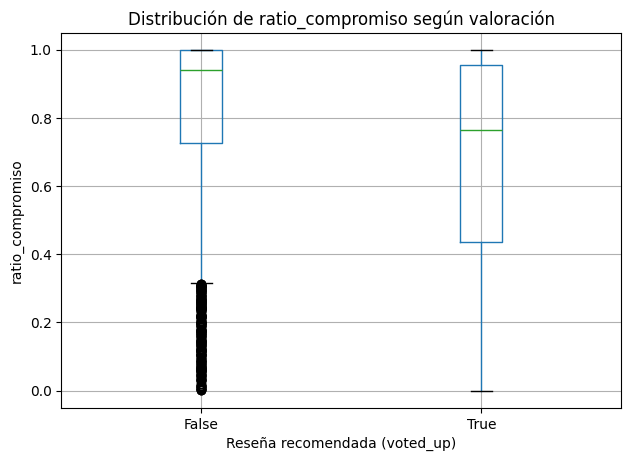

Promedio de ratio_compromiso por grupo:
             mean    median       std  count
voted_up                                    
False     0.81840  0.939128  0.247108   4166
True      0.67409  0.763577  0.303819  52330


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
df.boxplot(column="ratio_compromiso", by="voted_up", ax=ax)
ax.set_xlabel("Reseña recomendada (voted_up)")
ax.set_ylabel("ratio_compromiso")
ax.set_title("Distribución de ratio_compromiso según valoración")
plt.suptitle("")
plt.show()

print("Promedio de ratio_compromiso por grupo:")
print(df.groupby("voted_up")["ratio_compromiso"].agg(["mean", "median", "std", "count"]))


#### 3.2.3 Distribución de `ratio_compromiso` por género

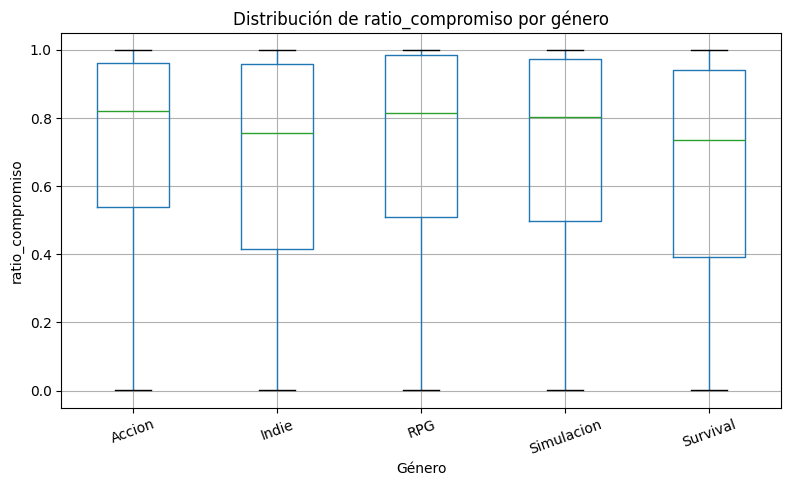

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
df.boxplot(column="ratio_compromiso", by="genero", ax=ax)
ax.set_xlabel("Género")
ax.set_ylabel("ratio_compromiso")
ax.set_title("Distribución de ratio_compromiso por género")
plt.suptitle("")
plt.xticks(rotation=20)
plt.show()


## 4 · Lectura preliminar con un modelo de sentimiento

### 4.1 Cargar datos e instalar dependencias

In [ ]:
!pip install pysentimiento -q

import pandas as pd
import numpy as np
import os

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)
df = df.dropna(subset=["review"])  # reseñas sin texto no sirven para esta parte
df = df[df["review"].str.strip().str.len() > 0]
print(f"Filas con texto utilizable: {len(df)} de {df['juego'].nunique()} juegos")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 33.8 MB/s eta 0:00:00
Mounted at /content/drive
Filas con texto utilizable: 56361 de 20 juegos


### 4.2 Análisis de sentimiento con `pysentimiento` (RoBERTuito)

Se utiliza el analizador de sentimiento en español ya entrenado, sin ajuste propio: en
esta instancia el objetivo es solamente obtener una lectura preliminar del contenido de
las reseñas. El ajuste fino del modelo se realiza más adelante, en la sección 6, sobre
las reseñas clasificadas a mano.

Esta sección es la que alimenta el trabajo final: las proporciones que se observan acá
son las que la sección 5 emplea para estimar la composición de la muestra a clasificar.

**Guardado de avance:** este paso es el más lento del notebook. El resultado se guarda en
`dataset_con_sentimiento_completo.csv` apenas termina, de modo que una segunda ejecución
lo carga directamente en lugar de volver a correr el modelo.

In [ ]:
from pysentimiento import create_analyzer
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Corriendo el modelo de sentimiento en: {device}")

analizador = create_analyzer(task="sentiment", lang="es")

def analizar_lote(textos, batch_size=64):
    resultados = []
    for i in range(0, len(textos), batch_size):
        lote = textos[i:i+batch_size]
        preds = analizador.predict(lote)
        resultados.extend(preds)
        if i % (batch_size * 20) == 0:
            print(f"  Procesadas {i}/{len(textos)} reseñas...")
    return resultados

textos = df["review"].astype(str).str.slice(0, 512).tolist()  # se trunca a 512 caracteres por eficiencia
predicciones = analizar_lote(textos)

df["sentimiento_pln"] = [p.output for p in predicciones]
# probas: diccionario con probabilidad de POS/NEU/NEG. Nos quedamos con la de POS
# como medida continua de polaridad (0 a 1).
df["polaridad_pln"] = [p.probas.get("POS", 0.0) for p in predicciones]

print(df[["voted_up", "sentimiento_pln", "polaridad_pln"]].head(10))
print("\nDistribución de sentimiento_pln:")
print(df["sentimiento_pln"].value_counts())


Corriendo el modelo de sentimiento en: cuda


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Map:   0%|          | 0/41 [00:00<?, ? examples/s]

  Procesadas 56320/56361 reseñas...
   voted_up sentimiento_pln  polaridad_pln
0      True             NEG       0.204671
1     False             NEG       0.008129
2      True             NEG       0.006813
3      True             NEG       0.095778
4      True             POS       0.959347
5     False             NEG       0.002478
6      True             NEU       0.225475
7     False             NEG       0.022724
8      True             NEU       0.189184
9      True             POS       0.432687

Distribución de sentimiento_pln:
sentimiento_pln
POS    27918
NEU    18597
NEG     9846
Name: count, dtype: int64


### 4.3 Chequeo rápido: ¿el sentimiento del texto coincide con la etiqueta binaria de Steam?

Antes de seguir, vale la pena confirmar que el modelo de sentimiento tiene sentido:
¿las reseñas que Steam etiqueta como recomendadas (`voted_up=True`) tienden a salir
POS, y las no recomendadas tienden a salir NEG?

In [ ]:
tabla_coincidencia = pd.crosstab(df["voted_up"], df["sentimiento_pln"], normalize="index") * 100
print("% de cada sentimiento de texto, según voted_up:")
display(tabla_coincidencia.round(1))

coincidencia_simple = (
    ((df["voted_up"]) & (df["sentimiento_pln"] == "POS")) |
    ((~df["voted_up"]) & (df["sentimiento_pln"] == "NEG"))
).mean() * 100
print(f"\n% de reseñas donde el sentimiento del texto 'coincide' con la etiqueta binaria: {coincidencia_simple:.1f}%")
print("(No se espera 100%: el texto y la etiqueta binaria capturan matices distintos, eso es justamente lo interesante.)")


% de cada sentimiento de texto, según voted_up:


sentimiento_pln,NEG,NEU,POS
voted_up,,,
False,80.1,16.9,3.0
True,12.5,34.3,53.2



% de reseñas donde el sentimiento del texto 'coincide' con la etiqueta binaria: 55.2%
(No se espera 100%: el texto y la etiqueta binaria capturan matices distintos, eso es justamente lo interesante.)


## 5 · Muestra para la clasificación manual

Genera el archivo `muestra_para_anotar.csv` que se carga en la aplicación de clasificación.

**Por qué estratificar.** El conjunto de datos tiene alrededor de un 92,6 % de reseñas con
voto positivo. Si se tomaran 800 al azar, saldrían unas 60 con voto negativo: muy pocas para
describir ese grupo con alguna precisión. Se definen entonces 10 estratos, cinco géneros por
dos opciones de voto, con 80 reseñas cada uno.

**Importante:** al sobrerrepresentar las negativas a propósito, cualquier valor que se
proyecte al conjunto completo necesita después una corrección. En el trabajo final esa
corrección es la post-estratificación por voto que aplica la sección 9: combina la
valoración media de cada grupo de voto según la proporción que ese grupo tiene realmente en
el videojuego. El peso por estrato que esta sección calcula y guarda corresponde a una
alternativa que finalmente no se utilizó.

### 5.1 Cargar el conjunto de datos

In [ ]:
import pandas as pd
import numpy as np
import os

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)

# Solo reseñas con texto utilizable: la anotación se hace sobre el texto.
df = df.dropna(subset=["review"])
df = df[df["review"].astype(str).str.strip().str.len() >= 3]

print(f"Corpus disponible para anotar: {len(df)} reseñas | {df['juego'].nunique()} juegos")
print(f"Proporción de positivas en el corpus: {df['voted_up'].mean()*100:.1f}%")


Mounted at /content/drive
Corpus disponible para anotar: 53059 reseñas | 20 juegos
Proporción de positivas en el corpus: 92.4%


### 5.2 Parámetros del muestreo

In [ ]:
POR_ESTRATO = 80     # reseñas a anotar por cada estrato (género × valoración)
SEMILLA = 42         # semilla fija: el muestreo es reproducible

# Longitud mínima: textos de 1-2 caracteres (".", "a") no aportan nada al
# entrenamiento y solo consumen tiempo de anotación. Se documenta como criterio.
LARGO_MINIMO = 10

df_elegible = df[df["review"].astype(str).str.strip().str.len() >= LARGO_MINIMO].copy()
print(f"Elegibles tras filtro de longitud mínima ({LARGO_MINIMO} caracteres): {len(df_elegible)}")

print("\nDisponibles por estrato:")
disponibles = df_elegible.groupby(["genero", "voted_up"]).size().unstack(fill_value=0)
disponibles.columns = ["No recomendada", "Recomendada"]
display(disponibles)


Elegibles tras filtro de longitud mínima (10 caracteres): 42180

Disponibles por estrato:


,No recomendada,Recomendada
genero,,
Accion,1608,5973
Indie,261,12918
RPG,249,8173
Simulacion,263,1869
Survival,1407,9459


### 5.3 Muestreo estratificado

Si algún estrato tuviera menos reseñas que `POR_ESTRATO`, se toman todas las disponibles y
se deja constancia, en lugar de continuar sin aviso.

In [ ]:
muestras = []
registro_estratos = []

for (genero, voted_up), grupo in df_elegible.groupby(["genero", "voted_up"]):
    n_disponible = len(grupo)
    n_tomar = min(POR_ESTRATO, n_disponible)

    if n_tomar < POR_ESTRATO:
        print(f"  [AVISO] Estrato ({genero}, voted_up={voted_up}): solo {n_disponible} disponibles, "
              f"se toman todas en lugar de {POR_ESTRATO}.")

    seleccion = grupo.sample(n=n_tomar, random_state=SEMILLA)
    seleccion = seleccion.copy()
    seleccion["estrato"] = f"{genero}|{voted_up}"
    muestras.append(seleccion)

    registro_estratos.append({
        "estrato": f"{genero}|{voted_up}",
        "genero": genero,
        "voted_up": voted_up,
        "n_poblacion": n_disponible,
        "n_muestra": n_tomar,
        # Peso de expansión: cuántas reseñas del corpus representa cada reseña anotada.
        "peso_expansion": n_disponible / n_tomar,
    })

muestra = pd.concat(muestras, ignore_index=True)
tabla_estratos = pd.DataFrame(registro_estratos)

print(f"\nTotal a anotar: {len(muestra)} reseñas")
display(tabla_estratos)



Total a anotar: 800 reseñas


,estrato,genero,voted_up,n_poblacion,n_muestra,peso_expansion
0,Accion|False,Accion,False,1608,80,20.1000
1,Accion|True,Accion,True,5973,80,74.6625
2,Indie|False,Indie,False,261,80,3.2625
3,Indie|True,Indie,True,12918,80,161.4750
4,RPG|False,RPG,False,249,80,3.1125
5,RPG|True,RPG,True,8173,80,102.1625
6,Simulacion|False,Simulacion,False,263,80,3.2875
7,Simulacion|True,Simulacion,True,1869,80,23.3625
8,Survival|False,Survival,False,1407,80,17.5875
9,Survival|True,Survival,True,9459,80,118.2375


### 5.4 Mezclar el orden

El orden de presentación se aleatoriza para que no queden bloques largos del mismo estrato
seguidos. Si aparecieran ochenta reseñas negativas al hilo, el criterio de quien clasifica
podría desplazarse por efecto del contexto.

In [ ]:
muestra = muestra.sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
muestra["orden_presentacion"] = range(1, len(muestra) + 1)

# Chequeo: los primeros 50 (prueba piloto) deberían mezclar varios estratos.
print("Composición de las primeras 50 (prueba piloto):")
print(muestra.head(50)["estrato"].value_counts())


Composición de las primeras 50 (prueba piloto):
estrato
Simulacion|True     10
Accion|False         8
RPG|False            8
Simulacion|False     6
Survival|True        5
Survival|False       4
Indie|True           4
RPG|True             2
Indie|False          2
Accion|True          1
Name: count, dtype: int64


### 5.5 Guardar los archivos

Se generan dos archivos separados, y esto es deliberado:

- `muestra_para_anotar.csv` — **solo** `recommendationid` y `review`. Es el que se carga en
  la aplicación. No contiene el voto de Steam ni el nombre del videojuego, de modo que la
  clasificación a ciegas queda garantizada por el archivo mismo y no por la voluntad de
  quien clasifica.
- `muestra_clave.csv` — la clave completa: voto, videojuego, género, variables derivadas,
  estrato y peso. Se usa recién **después** de terminar la clasificación, para cruzarla
  contra las etiquetas asignadas.

In [ ]:
ANOTAR_PATH = os.path.join(CHECKPOINT_DIR, "muestra_para_anotar.csv")
CLAVE_PATH  = os.path.join(CHECKPOINT_DIR, "muestra_clave.csv")
ESTRATOS_PATH = os.path.join(CHECKPOINT_DIR, "pesos_estratos.csv")

# Archivo para la herramienta: solo id y texto.
muestra[["recommendationid", "review"]].to_csv(ANOTAR_PATH, index=False)

# Clave completa, para usar después de anotar.
columnas_clave = [
    "recommendationid", "estrato", "orden_presentacion", "appid", "juego", "genero",
    "voted_up", "review", "ratio_compromiso", "nivel_compromiso",
    "playtime_at_review", "playtime_forever",
    "dias_desde_lanzamiento", "dias_desde_resena_hasta_extraccion",
]
columnas_clave = [c for c in columnas_clave if c in muestra.columns]
muestra[columnas_clave].to_csv(CLAVE_PATH, index=False)

tabla_estratos.to_csv(ESTRATOS_PATH, index=False)

print(f"Para anotar : {ANOTAR_PATH}  ({len(muestra)} filas, 2 columnas)")
print(f"Clave       : {CLAVE_PATH}")
print(f"Pesos       : {ESTRATOS_PATH}")

print("\nAsí ve la herramienta las primeras filas (sin valoración ni juego):")
display(muestra[["recommendationid", "review"]].head(3))


Para anotar : /content/drive/MyDrive/tesina_steam/checkpoints/muestra_para_anotar.csv  (800 filas, 2 columnas)
Clave       : /content/drive/MyDrive/tesina_steam/checkpoints/muestra_clave.csv
Pesos       : /content/drive/MyDrive/tesina_steam/checkpoints/pesos_estratos.csv

Así ve la herramienta las primeras filas (sin valoración ni juego):


,recommendationid,review
0,206970784,"Por favor sal de aqui lo antes posible, te que..."
1,225100397,"OSTIA PUTA QUE COSA MÁS CUTRE, POR FAVOR HACED..."
2,231092123,Espero que algun dia decidan hacer algo contra...


### 5.6 Estimación de la composición esperada

A partir de las proporciones observadas con el modelo de sentimiento sin ajuste, en la sección 4, se puede anticipar de manera aproximada cómo quedará repartida la
clasificación. Sirve para verificar que ninguna categoría quede demasiado chica antes de
invertir horas de lectura.

In [ ]:
# Proporciones observadas en la fase diagnóstica (sección 4), por valoración.
proporciones = {
    True:  {"POSITIVO": 0.532, "NEUTRAL": 0.343, "NEGATIVO": 0.125},
    False: {"POSITIVO": 0.030, "NEUTRAL": 0.169, "NEGATIVO": 0.801},
}

estimacion = {"POSITIVO": 0, "NEUTRAL": 0, "NEGATIVO": 0}
for _, fila in tabla_estratos.iterrows():
    for cat, prop in proporciones[fila["voted_up"]].items():
        estimacion[cat] += fila["n_muestra"] * prop

print("Composición estimada de la anotación (según el modelo sin ajuste):")
for cat, n in estimacion.items():
    print(f"  {cat:<10} ~{n:.0f}  ({n/len(muestra)*100:.1f}%)")

print("\nEs una estimación, no una predicción firme: la anotación humana no tiene por qué")
print("coincidir con el modelo sin ajustar. De hecho, medir esa diferencia es parte del trabajo.")


Composición estimada de la anotación (según el modelo sin ajuste):
  POSITIVO   ~225  (28.1%)
  NEUTRAL    ~205  (25.6%)
  NEGATIVO   ~370  (46.3%)

Es una estimación, no una predicción firme: la anotación humana no tiene por qué
coincidir con el modelo sin ajustar. De hecho, medir esa diferencia es parte del trabajo.


### 5.7 Cómo se llevó adelante la clasificación

Con los archivos generados, el procedimiento manual fue el siguiente:

1. Se descargó `muestra_para_anotar.csv` y se cargó en la aplicación de clasificación.
2. Se clasificaron las primeras cincuenta como prueba piloto, anotando los casos dudosos,
   y con eso se ajustó el criterio escrito antes de continuar con el resto.
3. Las 800 se clasificaron entre el 5 y el 10 de agosto de 2026, en cinco jornadas.
4. El archivo de etiquetas resultante es la entrada de la sección siguiente, donde se
   ajusta RoBERTuito y se evalúa su desempeño.

## 6 · Ajuste del modelo de clasificación

Ajusta RoBERTuito para clasificar reseñas en tres categorías y evalúa su desempeño frente
al mismo modelo sin ajuste al dominio. El modelo resulta necesario para una pregunta
secundaria del trabajo: si un esquema de tres categorías, aplicado de manera automática a
todas las reseñas, se aproxima más a la valoración de referencia que el voto binario. La
comprobación de la hipótesis no utiliza el modelo.


- **Datos:** las 682 reseñas clasificadas a mano con contenido evaluable (POSITIVO /
  NEUTRAL / NEGATIVO). Las 118 descartadas quedan fuera: el modelo base solo devuelve esas
  tres categorías, de modo que incluirlas volvería desigual la comparación. Es el mismo
  recorte sobre el que se calculó el coeficiente kappa de 0,920.
- **Validación cruzada estratificada de 5 particiones**, en lugar de una partición única.
  Con solo 64 neutrales, una partición única dejaría alrededor de once casos para evaluar y
  un solo acierto o desacierto movería la medición varios puntos. Con validación cruzada,
  las 682 pasan por evaluación exactamente una vez.
- **Ponderación de clases** en la función de pérdida, para que el modelo no aprenda a
  ignorar la categoría minoritaria.
- **Medidas por categoría** además del F1 macro, con intervalos estimados por remuestreo.

> **Activar GPU antes de correr:** Entorno de ejecución → Cambiar tipo de entorno de
> ejecución → T4 GPU. En CPU tarda muchísimo.

### 6.1 Instalación y carga

In [ ]:
!pip install -q transformers datasets pysentimiento accelerate

import pandas as pd, numpy as np, torch, os, json
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)
if DEVICE == "cpu":
    print("  [AVISO] Sin GPU esto va a tardar muchísimo. Activá T4 antes de seguir.")


Mounted at /content/drive
Dispositivo: cuda


### 6.2 Armar el conjunto de trabajo

Se cruzan las etiquetas manuales con el texto de las reseñas y se descartan las que no
tienen contenido evaluable.

In [ ]:
etiquetas = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"), encoding="utf-8-sig")
clave     = pd.read_csv(os.path.join(CHECKPOINT_DIR, "muestra_clave.csv"))

df = etiquetas.merge(clave, on="recommendationid", how="inner")
print(f"Anotadas totales: {len(df)}")

# Solo las que tienen contenido evaluable
df = df[df["etiqueta_manual"] != "DESCARTAR"].reset_index(drop=True)
print(f"Con contenido evaluable: {len(df)}")
print(df["etiqueta_manual"].value_counts())

CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]
CLASE_A_ID = {c: i for i, c in enumerate(CLASES)}
df["y"] = df["etiqueta_manual"].map(CLASE_A_ID)

textos = df["review"].astype(str).tolist()
y = df["y"].values
print("\nDistribución de clases:", {c: int((y == i).sum()) for i, c in enumerate(CLASES)})


Anotadas totales: 800
Con contenido evaluable: 682
etiqueta_manual
POSITIVO    337
NEGATIVO    281
NEUTRAL      64
Name: count, dtype: int64

Distribución de clases: {'NEGATIVO': 281, 'NEUTRAL': 64, 'POSITIVO': 337}


### 6.3 Línea base — RoBERTuito sin ajuste de dominio

Es el punto de comparación: el modelo tal como viene, sin haber visto nunca una reseña de
videojuegos. Se evalúa sobre las mismas 682 reseñas.

In [ ]:
from pysentimiento import create_analyzer

analizador_base = create_analyzer(task="sentiment", lang="es")

def predecir_base(textos, batch=64):
    salidas = []
    for i in range(0, len(textos), batch):
        preds = analizador_base.predict([t[:512] for t in textos[i:i+batch]])
        salidas.extend([p.output for p in preds])
        if i % (batch*4) == 0:
            print(f"  {i}/{len(textos)}...")
    return salidas

etiquetas_base = predecir_base(textos)

# pysentimiento devuelve POS / NEU / NEG -> se mapea a nuestros índices
MAPEO_BASE = {"POS": CLASE_A_ID["POSITIVO"], "NEU": CLASE_A_ID["NEUTRAL"], "NEG": CLASE_A_ID["NEGATIVO"]}
y_base = np.array([MAPEO_BASE[e] for e in etiquetas_base])

f1_base = f1_score(y, y_base, average="macro")
print(f"\nLÍNEA BASE — F1 macro: {f1_base:.4f}")
print(classification_report(y, y_base, target_names=CLASES, digits=3))


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

...

Map:   0%|          | 0/64 [00:00<?, ? examples/s]

  512/682...


Map:   0%|          | 0/64 [00:00<?, ? examples/s]

Map:   0%|          | 0/42 [00:00<?, ? examples/s]


LÍNEA BASE — F1 macro: 0.5866
              precision    recall  f1-score   support

    NEGATIVO      0.737     0.907     0.813       281
     NEUTRAL      0.133     0.172     0.150        64
    POSITIVO      0.929     0.697     0.797       337

    accuracy                          0.735       682
   macro avg      0.599     0.592     0.587       682
weighted avg      0.775     0.735     0.743       682



### 6.4 Ajuste fino con validación cruzada de 5 particiones

Cada partición entrena sobre el 80 % y predice sobre el 20 % restante. Al terminar las cinco,
cada una de las 682 reseñas tiene una predicción hecha por un modelo que nunca la vio
durante su entrenamiento (predicciones *out-of-fold*).

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)
from pysentimiento.preprocessing import preprocess_tweet

MODELO = "pysentimiento/robertuito-base-uncased"
MAX_LEN = 128        # las reseñas son cortas; 128 tokens cubre la enorme mayoría
EPOCAS = 4
LR = 2e-5
BATCH = 16
SEMILLA = 42

tokenizador = AutoTokenizer.from_pretrained(MODELO)

# RoBERTuito espera el mismo preprocesamiento con el que fue preentrenado
textos_prep = [preprocess_tweet(t, lang="es") for t in textos]

class DatasetResenas(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizador(textos, truncation=True, padding="max_length", max_length=MAX_LEN)
        self.etiquetas = etiquetas
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(int(self.etiquetas[i]))
        return item


config.json:   0%|          | 0.00/677 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/323 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/858k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

#### 6.4.1 Entrenador con ponderación de clases

La clase neutral es minoritaria. Sin ponderar, el modelo minimiza la pérdida ignorándola:
acierta el 90 % simplemente no prediciendo nunca «neutral». La ponderación hace que
equivocarse en una neutral cueste más.

In [ ]:
class TrainerPonderado(Trainer):
    def __init__(self, pesos_clase=None, **kwargs):
        super().__init__(**kwargs)
        self.pesos_clase = pesos_clase
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        fn = torch.nn.CrossEntropyLoss(
            weight=self.pesos_clase.to(logits.device) if self.pesos_clase is not None else None)
        loss = fn(logits.view(-1, len(CLASES)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def metricas(eval_pred):
    logits, labels = eval_pred
    pred = np.argmax(logits, axis=-1)
    return {"f1_macro": f1_score(labels, pred, average="macro")}


#### 6.4.2 Bucle de validación cruzada

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
y_ajustado = np.zeros(len(y), dtype=int)   # predicciones out-of-fold
f1_por_particion = []

for n, (idx_train, idx_test) in enumerate(skf.split(textos_prep, y), start=1):
    print(f"\n{'='*60}\nPARTICIÓN {n}/5  —  entrena {len(idx_train)} | evalúa {len(idx_test)}\n{'='*60}")

    tr_txt = [textos_prep[i] for i in idx_train]
    te_txt = [textos_prep[i] for i in idx_test]
    ds_tr = DatasetResenas(tr_txt, y[idx_train])
    ds_te = DatasetResenas(te_txt, y[idx_test])

    # Los pesos se calculan SOLO con el conjunto de entrenamiento de esta partición
    pesos = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y[idx_train])
    pesos_t = torch.tensor(pesos, dtype=torch.float)
    print("  pesos por clase:", {c: round(float(p), 2) for c, p in zip(CLASES, pesos)})

    modelo = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=len(CLASES))

    args = TrainingArguments(
        output_dir=f"/content/ft_particion_{n}",
        num_train_epochs=EPOCAS,
        learning_rate=LR,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=64,
        warmup_ratio=0.1,
        weight_decay=0.01,
        logging_steps=50,
        save_strategy="no",
        report_to="none",
        seed=SEMILLA,
        fp16=(DEVICE == "cuda"),
    )

    trainer = TrainerPonderado(
        pesos_clase=pesos_t, model=modelo, args=args,
        train_dataset=ds_tr, eval_dataset=ds_te, compute_metrics=metricas,
    )
    trainer.train()

    pred = np.argmax(trainer.predict(ds_te).predictions, axis=-1)
    y_ajustado[idx_test] = pred
    f1_p = f1_score(y[idx_test], pred, average="macro")
    f1_por_particion.append(f1_p)
    print(f"  F1 macro de la partición: {f1_p:.4f}")

    del modelo, trainer
    torch.cuda.empty_cache()

print(f"\nF1 por partición: {[round(f,4) for f in f1_por_particion]}")
print(f"F1 macro promedio: {np.mean(f1_por_particion):.4f} (desvío {np.std(f1_por_particion):.4f})")



PARTICIÓN 1/5  —  entrena 545 | evalúa 137
  pesos por clase: {'NEGATIVO': 0.81, 'NEUTRAL': 3.56, 'POSITIVO': 0.68}


model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.018', 'grad_norm': '5.844', 'learning_rate': '1.444e-05', 'epoch': '1.429'}
{'loss': '0.7639', 'grad_norm': '6.532', 'learning_rate': '6.508e-06', 'epoch': '2.857'}
{'train_runtime': '16.77', 'train_samples_per_second': '130', 'train_steps_per_second': '8.348', 'train_loss': '0.8114', 'epoch': '4'}
  F1 macro de la partición: 0.6671

PARTICIÓN 2/5  —  entrena 545 | evalúa 137
  pesos por clase: {'NEGATIVO': 0.81, 'NEUTRAL': 3.56, 'POSITIVO': 0.68}


...

{'loss': '1.035', 'grad_norm': '5.896', 'learning_rate': '1.444e-05', 'epoch': '1.429'}
{'loss': '0.7945', 'grad_norm': '5.303', 'learning_rate': '6.508e-06', 'epoch': '2.857'}
{'train_runtime': '14.61', 'train_samples_per_second': '149.5', 'train_steps_per_second': '9.585', 'train_loss': '0.8324', 'epoch': '4'}
  F1 macro de la partición: 0.6389

PARTICIÓN 4/5  —  entrena 546 | evalúa 136
  pesos por clase: {'NEGATIVO': 0.81, 'NEUTRAL': 3.57, 'POSITIVO': 0.67}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.042', 'grad_norm': '7.428', 'learning_rate': '1.444e-05', 'epoch': '1.429'}
{'loss': '0.7873', 'grad_norm': '4.733', 'learning_rate': '6.508e-06', 'epoch': '2.857'}
{'train_runtime': '16.15', 'train_samples_per_second': '135.2', 'train_steps_per_second': '8.668', 'train_loss': '0.83', 'epoch': '4'}
  F1 macro de la partición: 0.6012

PARTICIÓN 5/5  —  entrena 546 | evalúa 136
  pesos por clase: {'NEGATIVO': 0.81, 'NEUTRAL': 3.57, 'POSITIVO': 0.67}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.044', 'grad_norm': '5.811', 'learning_rate': '1.444e-05', 'epoch': '1.429'}
{'loss': '0.7652', 'grad_norm': '7.214', 'learning_rate': '6.508e-06', 'epoch': '2.857'}
{'train_runtime': '15.11', 'train_samples_per_second': '144.5', 'train_steps_per_second': '9.264', 'train_loss': '0.8181', 'epoch': '4'}
  F1 macro de la partición: 0.6713

F1 por partición: [0.6671, 0.7084, 0.6389, 0.6012, 0.6713]
F1 macro promedio: 0.6574 (desvío 0.0358)


### 6.5 Comparación entre la línea base y el modelo ajustado

Ambos se evalúan sobre las mismas 682 reseñas, así que la comparación es directa.

In [ ]:
f1_ajustado = f1_score(y, y_ajustado, average="macro")

print(f"LÍNEA BASE (sin ajuste) — F1 macro: {f1_base:.4f}")
print(f"AJUSTADO   (fine-tuned) — F1 macro: {f1_ajustado:.4f}")
print(f"Diferencia: {f1_ajustado - f1_base:+.4f}")

print("\n--- Línea base ---")
print(classification_report(y, y_base, target_names=CLASES, digits=3))
print("--- Ajustado ---")
print(classification_report(y, y_ajustado, target_names=CLASES, digits=3))


LÍNEA BASE (sin ajuste) — F1 macro: 0.5866
AJUSTADO   (fine-tuned) — F1 macro: 0.6585
Diferencia: +0.0720

--- Línea base ---
              precision    recall  f1-score   support

    NEGATIVO      0.737     0.907     0.813       281
     NEUTRAL      0.133     0.172     0.150        64
    POSITIVO      0.929     0.697     0.797       337

    accuracy                          0.735       682
   macro avg      0.599     0.592     0.587       682
weighted avg      0.775     0.735     0.743       682

--- Ajustado ---
              precision    recall  f1-score   support

    NEGATIVO      0.783     0.836     0.809       281
     NEUTRAL      0.314     0.344     0.328        64
    POSITIVO      0.872     0.807     0.838       337

    accuracy                          0.776       682
   macro avg      0.656     0.662     0.659       682
weighted avg      0.783     0.776     0.778       682



#### 6.5.1 ¿La mejora es estadísticamente significativa?

Se remuestrea el conjunto 2.000 veces y se recalcula la diferencia de F1 en cada remuestreo.
Si el intervalo no incluye el 0, la diferencia es significativa.

In [ ]:
rng = np.random.default_rng(SEMILLA)
diferencias = []
n = len(y)
for _ in range(2000):
    idx = rng.choice(n, n, replace=True)
    if len(np.unique(y[idx])) < len(CLASES):
        continue
    diferencias.append(f1_score(y[idx], y_ajustado[idx], average="macro")
                       - f1_score(y[idx], y_base[idx], average="macro"))
diferencias = np.array(diferencias)
ic_inf, ic_sup = np.percentile(diferencias, [2.5, 97.5])

print(f"Diferencia observada: {f1_ajustado - f1_base:+.4f}")
print(f"IC 95% (bootstrap):   [{ic_inf:+.4f} ; {ic_sup:+.4f}]")
if ic_inf > 0:
    print("\n-> El intervalo está por encima de 0: el ajuste de dominio mejora SIGNIFICATIVAMENTE.")
elif ic_sup < 0:
    print("\n-> El intervalo está por debajo de 0: el ajuste EMPEORA el desempeño.")
else:
    print("\n-> El intervalo incluye el 0: no hay diferencia significativa.")

# McNemar como contraste complementario
from statsmodels.stats.contingency_tables import mcnemar
ok_base = (y_base == y); ok_ft = (y_ajustado == y)
tabla = [[int((ok_base & ok_ft).sum()),  int((ok_base & ~ok_ft).sum())],
         [int((~ok_base & ok_ft).sum()), int((~ok_base & ~ok_ft).sum())]]
res = mcnemar(tabla, exact=False, correction=True)
print(f"\nMcNemar: estadístico = {res.statistic:.3f} | p = {res.pvalue:.6f}")
print(f"  solo acierta la base: {tabla[0][1]} | solo acierta el ajustado: {tabla[1][0]}")


Diferencia observada: +0.0720
IC 95% (bootstrap):   [+0.0218 ; +0.1187]

-> El intervalo está por encima de 0: el ajuste de dominio mejora SIGNIFICATIVAMENTE.

McNemar: estadístico = 5.695 | p = 0.017010
  solo acierta la base: 50 | solo acierta el ajustado: 78


#### 6.5.2 Dónde se equivoca cada uno

La matriz de confusión muestra si el modelo base efectivamente usa «neutral» como cajón de
descarte, tal como sugería la fase diagnóstica.

In [ ]:
for nombre, pred in [("LÍNEA BASE", y_base), ("AJUSTADO", y_ajustado)]:
    print(f"\n=== {nombre} ===")
    cm = pd.DataFrame(confusion_matrix(y, pred), index=[f"real {c}" for c in CLASES],
                      columns=[f"pred {c}" for c in CLASES])
    display(cm)
    reparto = pd.Series(pred).value_counts(normalize=True).sort_index()
    print("Reparto de predicciones:",
          {CLASES[i]: f"{v*100:.1f}%" for i, v in reparto.items()})

print(f"\nReparto REAL (anotación humana):",
      {CLASES[i]: f"{(y==i).mean()*100:.1f}%" for i in range(len(CLASES))})



=== LÍNEA BASE ===


,pred NEGATIVO,pred NEUTRAL,pred POSITIVO
real NEGATIVO,255,16,10
real NEUTRAL,45,11,8
real POSITIVO,46,56,235


Reparto de predicciones: {'NEGATIVO': '50.7%', 'NEUTRAL': '12.2%', 'POSITIVO': '37.1%'}

=== AJUSTADO ===


,pred NEGATIVO,pred NEUTRAL,pred POSITIVO
real NEGATIVO,235,23,23
real NEUTRAL,25,22,17
real POSITIVO,40,25,272


Reparto de predicciones: {'NEGATIVO': '44.0%', 'NEUTRAL': '10.3%', 'POSITIVO': '45.7%'}

Reparto REAL (anotación humana): {'NEGATIVO': '41.2%', 'NEUTRAL': '9.4%', 'POSITIVO': '49.4%'}


#### 6.5.3 Qué reseñas corrigió el ajuste

Casos donde el modelo base se equivocaba y el ajustado acierta. Suele concentrarse en ironía
y jerga del dominio, que es justamente lo que motivó el ajuste.

In [ ]:
corregidas = df[(y_base != y) & (y_ajustado == y)].copy()
corregidas["base_dijo"] = [CLASES[i] for i in y_base[(y_base != y) & (y_ajustado == y)]]
corregidas["correcto"]  = corregidas["etiqueta_manual"]

print(f"Corregidas por el ajuste: {len(corregidas)}\n")
pd.set_option("display.max_colwidth", 130)
display(corregidas[["review", "base_dijo", "correcto"]].head(15))

rotas = df[(y_base == y) & (y_ajustado != y)].copy()
print(f"\nEmpeoradas por el ajuste: {len(rotas)}")
if len(rotas):
    rotas["ajustado_dijo"] = [CLASES[i] for i in y_ajustado[(y_base == y) & (y_ajustado != y)]]
    display(rotas[["review", "etiqueta_manual", "ajustado_dijo"]].head(10))


Corregidas por el ajuste: 78



,review,base_dijo,correcto
2,Espero que algun dia decidan hacer algo contra los hackers. Algo que le haria muy bien a toda la comunidad y NADIE estaria en ...,POSITIVO,NEGATIVO
6,"El juego en si esta muy bueno, lo tiene todo! Lo que pasa es que se tilda muy seguido y no es problema de la pc, tengo una que...",POSITIVO,NEUTRAL
11,"con las esperanzas de que sea superior al 1, lo fue, pero en mi opinion sigue repitiendo la misma formula de que sea novedoso ...",POSITIVO,NEUTRAL
16,"los packs d expansión son carisimos, cueeeeeeeeeeeeeeck",POSITIVO,NEGATIVO
41,Es verdad que el juego base es un poco aburrido pero con mods se hace mas divertido.,POSITIVO,NEUTRAL
48,es como ir a pinar del río,NEUTRAL,POSITIVO
54,este juego te absorbe la vida,NEGATIVO,POSITIVO
58,lo reembolse porque necesitaba la plata pero recomendadisimo,NEUTRAL,POSITIVO
76,Subestimado,NEUTRAL,POSITIVO
94,"soy mucho de mmorpgs, quize salir de mi zona de comfort y probar algo nuevo, el combate por turnos no es lo mio, pese a tener ...",NEGATIVO,NEUTRAL



Empeoradas por el ajuste: 50


,review,etiqueta_manual,ajustado_dijo
19,HASTA EL ACTO 2 ES UN 9 /10\r\nCON EL ACTO 3 ES UN 6/10\r\n\r\nINFUMABLE SE QUEDA CORTO,NEGATIVO,POSITIVO
29,HAY CHEETAHS SALVAJES,NEGATIVO,POSITIVO
38,me gusta jugarlo es entretenido pero no me gusta porque no me carga al principio y aveces ni me lo abre\n,NEUTRAL,NEGATIVO
53,"el juego por si solo es bueno, pero te aburre muyyyyyyyyyyy rápido, en serio, se queda muy corto de contenido y comprar los dl...",NEGATIVO,NEUTRAL
56,no hay secso -10/10 y muy zzz,NEGATIVO,NEUTRAL
67,"mi alma esta conectada a los sims 4. los quiero, los necesito, son lo mejor que me paso en la vida.",POSITIVO,NEUTRAL
73,Aún que el juego es bastante entretenido se siente vacío sin los dlcs hasta un punto que la economia de tu ciudad se desploma ...,NEGATIVO,NEUTRAL
77,"en lo personal no me gusto es un juego que me llevo de vuelta al play uno, su mecanica, graficos, patrones de boss es muy anti...",NEGATIVO,NEUTRAL
123,"Para ser sincero, los Metroidvanias nunca me llamaron la atención; pensaba que la progresión iba a ser lenta y súper pesada. Q...",POSITIVO,NEUTRAL
133,muy de gordo vivido,NEGATIVO,POSITIVO


### 6.6 Guardar resultados y entrenar el modelo final

El modelo final se entrena con las 682 reseñas completas, sin dejar ninguna partición
afuera, porque ya no hace falta evaluarlo: la estimación de su desempeño es la que dio la
validación cruzada. Este modelo es el que se aplica a la totalidad de las reseñas en la
sección 9.

Conviene señalar que este modelo fue reemplazado más adelante. La sección 8 lo
reentrena incorporando las 121 reseñas utilizables de la ampliación por incertidumbre, y
es esa versión, entrenada sobre 803 reseñas, la que finalmente se aplicó al conjunto
completo.

In [ ]:
resultados = {
    "n_evaluadas": int(len(y)),
    "f1_base": float(f1_base),
    "f1_ajustado": float(f1_ajustado),
    "diferencia": float(f1_ajustado - f1_base),
    "ic95_inferior": float(ic_inf),
    "ic95_superior": float(ic_sup),
    "f1_por_particion": [float(f) for f in f1_por_particion],
    "mcnemar_p": float(res.pvalue),
}
with open(os.path.join(CHECKPOINT_DIR, "resultado_objetivo_3.json"), "w") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)

pd.DataFrame({
    "recommendationid": df["recommendationid"],
    "etiqueta_manual": df["etiqueta_manual"],
    "pred_base": [CLASES[i] for i in y_base],
    "pred_ajustado": [CLASES[i] for i in y_ajustado],
}).to_csv(os.path.join(CHECKPOINT_DIR, "predicciones_oof.csv"), index=False)

print(json.dumps(resultados, indent=2, ensure_ascii=False))


{
  "n_evaluadas": 682,
  "f1_base": 0.5865557208745688,
  "f1_ajustado": 0.6585069766121826,
  "diferencia": 0.07195125573761385,
  "ic95_inferior": 0.02175515229084759,
  "ic95_superior": 0.11871005232081579,
  "f1_por_particion": [
    0.6671387277226692,
    0.7084197562872699,
    0.6389341590612777,
    0.6011878900002647,
    0.6712583750657428
  ],
  "mcnemar_p": 0.017010283398021995
}


In [ ]:
# Modelo final sobre las 682 completas
pesos_full = torch.tensor(
    compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y), dtype=torch.float)

modelo_final = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=len(CLASES))
args_final = TrainingArguments(
    output_dir="/content/ft_final", num_train_epochs=EPOCAS, learning_rate=LR,
    per_device_train_batch_size=BATCH, warmup_ratio=0.1, weight_decay=0.01,
    logging_steps=50, save_strategy="no", report_to="none", seed=SEMILLA,
    fp16=(DEVICE == "cuda"),
)
trainer_final = TrainerPonderado(
    pesos_clase=pesos_full, model=modelo_final, args=args_final,
    train_dataset=DatasetResenas(textos_prep, y),
)
trainer_final.train()

RUTA_MODELO = os.path.join(CHECKPOINT_DIR, "modelo_robertuito_ajustado")
trainer_final.save_model(RUTA_MODELO)
tokenizador.save_pretrained(RUTA_MODELO)
print(f"\nModelo final guardado en {RUTA_MODELO}")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.048', 'grad_norm': '5.54', 'learning_rate': '1.597e-05', 'epoch': '1.163'}
{'loss': '0.8144', 'grad_norm': '7.038', 'learning_rate': '9.481e-06', 'epoch': '2.326'}
{'loss': '0.6006', 'grad_norm': '4.168', 'learning_rate': '2.987e-06', 'epoch': '3.488'}
{'train_runtime': '19', 'train_samples_per_second': '143.6', 'train_steps_per_second': '9.054', 'train_loss': '0.7815', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modelo final guardado en /content/drive/MyDrive/tesina_steam/checkpoints/modelo_robertuito_ajustado


### 6.7 Qué mirar de estos resultados

Dos cosas de lo que acaba de salir:

1. **El reparto de predicciones del modelo sin ajuste**, en la sección 6.5.2. Confirma con
   números la lectura preliminar de la sección 4: asigna la categoría negativa a más
   reseñas de las que corresponden.
2. **El F1 de la categoría neutral en el modelo ajustado.** Quedó en 0,328, lo bastante
   bajo como para justificar clasificar reseñas adicionales elegidas entre aquellas sobre
   las que el modelo se muestra indeciso, para usarlas solo en el entrenamiento y nunca en
   la evaluación. Eso es lo que hacen las dos secciones siguientes.

## 7 · Ampliación por muestreo por incertidumbre

La categoría NEUTRAL alcanzó un F1 de 0,328 en el modelo ajustado, con solo 64 casos de
entrenamiento. Esta sección selecciona 150 reseñas adicionales para clasificar, orientadas
a reforzar precisamente esa categoría.


Seleccionar las reseñas que el modelo etiqueta como neutrales reforzaría lo que el modelo
*ya cree*, sin corregir aquello en lo que falla. El **muestreo por incertidumbre**, descrito
por Lewis y Gale (1994), elige en cambio aquellas sobre las que el modelo se muestra
indeciso entre dos categorías.

### 7.1 Carga del modelo ajustado y del conjunto de datos

In [ ]:
!pip install -q transformers pysentimiento

import pandas as pd, numpy as np, torch, os
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from pysentimiento.preprocessing import preprocess_tweet

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

RUTA_MODELO = os.path.join(CHECKPOINT_DIR, "modelo_robertuito_ajustado")
CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]   # mismo orden que en la sección 6

tokenizador = AutoTokenizer.from_pretrained(RUTA_MODELO)
modelo = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO).to(DEVICE).eval()
print("Modelo ajustado cargado.")


Mounted at /content/drive
Dispositivo: cuda


Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

Modelo ajustado cargado.


### 7.2 Preparar el conjunto de candidatas

Se excluyen las 800 ya anotadas y se aplican dos filtros de longitud:

- **Mínimo 40 caracteres.** Los textos muy cortos también generan incertidumbre, pero por
  falta de información, no por ser mixtos. Sin este filtro las 150 se llenarían de «si»,
  «pollo» y similares, que ya sabemos que van a DESCARTAR.
- **Máximo 1.500 caracteres**, para que la anotación siga siendo abordable en tiempo razonable.

In [ ]:
corpus = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
ya_anotadas = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"),
                          encoding="utf-8-sig")["recommendationid"].tolist()

print(f"Corpus completo: {len(corpus)}")

cand = corpus[~corpus["recommendationid"].isin(ya_anotadas)].copy()
cand["review"] = cand["review"].astype(str)
cand["largo"] = cand["review"].str.strip().str.len()

LARGO_MIN, LARGO_MAX = 40, 1500
cand = cand[(cand["largo"] >= LARGO_MIN) & (cand["largo"] <= LARGO_MAX)].reset_index(drop=True)

print(f"Candidatas tras excluir las anotadas y filtrar por longitud: {len(cand)}")
print(cand["genero"].value_counts().to_dict())


Corpus completo: 56496
Candidatas tras excluir las anotadas y filtrar por longitud: 23487
{'Indie': 7406, 'Survival': 6318, 'RPG': 4889, 'Accion': 3692, 'Simulacion': 1182}


### 7.3 Predecir y medir la incertidumbre

Para cada reseña se calcula el **margen** = probabilidad de la clase más votada menos la de la
segunda. Cuanto más cerca de 0, más indeciso está el modelo.

In [ ]:
@torch.no_grad()
def probabilidades(textos, batch=64, max_len=128):
    salidas = []
    for i in range(0, len(textos), batch):
        lote = [preprocess_tweet(t, lang="es") for t in textos[i:i+batch]]
        enc = tokenizador(lote, truncation=True, padding=True,
                          max_length=max_len, return_tensors="pt").to(DEVICE)
        logits = modelo(**enc).logits
        salidas.append(torch.softmax(logits, dim=-1).cpu().numpy())
        if i % (batch * 20) == 0:
            print(f"  {i}/{len(textos)}...")
    return np.vstack(salidas)

probs = probabilidades(cand["review"].tolist())

orden = np.sort(probs, axis=1)
cand["margen"] = orden[:, -1] - orden[:, -2]          # incertidumbre: chico = indeciso
cand["pred"] = [CLASES[i] for i in probs.argmax(axis=1)]
cand["p_neutral"] = probs[:, CLASES.index("NEUTRAL")]

print("\nDistribución de predicciones sobre las candidatas:")
print(cand["pred"].value_counts(normalize=True).mul(100).round(1).to_dict())
print(f"\nMargen — mediana: {cand['margen'].median():.3f} | percentil 10: {cand['margen'].quantile(.10):.3f}")


  0/23487...
  1280/23487...
  2560/23487...
  3840/23487...
  5120/23487...
  6400/23487...
  7680/23487...
  8960/23487...
  10240/23487...
  11520/23487...
  12800/23487...
  14080/23487...
  15360/23487...
  16640/23487...
  17920/23487...
  19200/23487...
  20480/23487...
  21760/23487...
  23040/23487...

Distribución de predicciones sobre las candidatas:
{'POSITIVO': 71.1, 'NEGATIVO': 20.3, 'NEUTRAL': 8.6}

Margen — mediana: 0.535 | percentil 10: 0.094


### 7.4 Seleccionar 150, estratificando por género

Se toman las 30 de menor margen dentro de cada género. Sin estratificar, la selección podría
concentrarse en un solo tipo de juego y el refuerzo quedaría sesgado hacia ese dominio.

In [ ]:
POR_GENERO = 30
SEMILLA = 42

seleccion = (cand.sort_values("margen")
                 .groupby("genero", group_keys=False)
                 .head(POR_GENERO)
                 .copy())

print(f"Seleccionadas: {len(seleccion)}")
print(seleccion["genero"].value_counts().to_dict())
print(f"\nMargen de las seleccionadas — máximo: {seleccion['margen'].max():.3f} "
      f"| mediana: {seleccion['margen'].median():.3f}")

# Control: ¿estamos pescando en el lugar correcto?
top2_incluye_neutral = ((seleccion["pred"] == "NEUTRAL") |
                        (seleccion["p_neutral"] >= np.sort(probs, axis=1)[:, -2].min())).mean()
print(f"\nPredicción del modelo sobre las seleccionadas:")
print(seleccion["pred"].value_counts().to_dict())
print(f"Probabilidad media asignada a NEUTRAL: {seleccion['p_neutral'].mean():.3f} "
      f"(contra {cand['p_neutral'].mean():.3f} en el conjunto general)")


Seleccionadas: 150
{'Indie': 30, 'Accion': 30, 'RPG': 30, 'Survival': 30, 'Simulacion': 30}

Margen de las seleccionadas — máximo: 0.020 | mediana: 0.003

Predicción del modelo sobre las seleccionadas:
{'NEUTRAL': 56, 'POSITIVO': 48, 'NEGATIVO': 46}
Probabilidad media asignada a NEUTRAL: 0.344 (contra 0.199 en el conjunto general)


### 7.5 Exportar los archivos

Igual que con las 800: un archivo para anotar con lo mínimo indispensable, y una clave
aparte que no se abre hasta terminar.

In [ ]:
rng = np.random.default_rng(SEMILLA)
seleccion = seleccion.iloc[rng.permutation(len(seleccion))].reset_index(drop=True)

RUTA_ANOTAR = os.path.join(CHECKPOINT_DIR, "muestra_ampliacion.csv")
RUTA_CLAVE  = os.path.join(CHECKPOINT_DIR, "ampliacion_clave.csv")

seleccion[["recommendationid", "review"]].to_csv(RUTA_ANOTAR, index=False)

seleccion[["recommendationid", "juego", "genero", "voted_up", "review",
           "margen", "pred", "p_neutral", "ratio_compromiso"]].to_csv(RUTA_CLAVE, index=False)

print(f"Para anotar : {RUTA_ANOTAR}  ({len(seleccion)} filas, 2 columnas)")
print(f"Clave       : {RUTA_CLAVE}   (no abrir hasta terminar)")
print("\nPrimeras filas del archivo a anotar:")
pd.set_option("display.max_colwidth", 110)
display(seleccion[["recommendationid", "review"]].head(5))


Para anotar : /content/drive/MyDrive/tesina_steam/checkpoints/muestra_ampliacion.csv  (150 filas, 2 columnas)
Clave       : /content/drive/MyDrive/tesina_steam/checkpoints/ampliacion_clave.csv   (no abrir hasta terminar)

Primeras filas del archivo a anotar:


,recommendationid,review
0,230181039,"No, no es divertido... Te trae traumas hasta que ves a la zoologa ZAMN"
1,216357424,"la verdad que no se que sucede, pero intento jugar una partida de doom y no me permite ingresar. a alguien..."
2,207332327,"juego todo pinche hermoso, no como esa mamada de sucesor que sacaron"
3,231620618,Nada simplemente me gusto el juego y tambien me gustaron sus mecanicas
4,201379526,"Siempre han sido muy buenos, ojala agregaran modo Online"


### 7.6 Después de anotar: cómo se integran

Una vez anotadas, estas 150 se **suman al conjunto de entrenamiento** de cada partición de la
sección 6, pero **nunca al de evaluación**. En términos de código, la validación cruzada
sigue partiendo únicamente las 682 originales, y las 150 nuevas se concatenan al bloque de
entrenamiento de cada partición.

La celda siguiente deja armada esa lógica para cuando tengas las etiquetas.

In [ ]:
# Ejecutar recién cuando exista etiquetas_ampliacion.csv
RUTA_ETIQ_AMP = os.path.join(CHECKPOINT_DIR, "etiquetas_ampliacion.csv")

if os.path.exists(RUTA_ETIQ_AMP):
    amp = pd.read_csv(RUTA_ETIQ_AMP, encoding="utf-8-sig")
    clave_amp = pd.read_csv(RUTA_CLAVE)
    amp = amp.merge(clave_amp[["recommendationid", "review"]], on="recommendationid")
    amp = amp[amp["etiqueta_manual"] != "DESCARTAR"]

    print(f"Ampliación anotada: {len(amp)} utilizables")
    print(amp["etiqueta_manual"].value_counts().to_dict())

    base = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"),
                       encoding="utf-8-sig")
    n_neu_antes = (base["etiqueta_manual"] == "NEUTRAL").sum()
    n_neu_ahora = n_neu_antes + (amp["etiqueta_manual"] == "NEUTRAL").sum()
    print(f"\nNeutrales: {n_neu_antes} -> {n_neu_ahora} "
          f"(+{(n_neu_ahora/n_neu_antes - 1)*100:.0f}%)")

    amp[["recommendationid", "etiqueta_manual", "review"]].to_csv(
        os.path.join(CHECKPOINT_DIR, "ampliacion_para_entrenar.csv"), index=False)
    print("\nGuardado: ampliacion_para_entrenar.csv (SOLO para entrenamiento)")
else:
    print("Todavía no existe etiquetas_ampliacion.csv.")
    print("Anotá muestra_ampliacion.csv en la herramienta y volvé a correr esta celda.")


Todavía no existe etiquetas_ampliacion.csv.
Anotá muestra_ampliacion.csv en la herramienta y volvé a correr esta celda.


### 7.7 Qué se esperaba y qué ocurrió

Si el muestreo por incertidumbre funcionaba, de estas 150 debía salir una proporción de
neutrales bastante más alta que el 9,4 % del conjunto general. Si salía parecida, habría
significado que la indecisión del modelo no capta la ambigüedad de la valoración sino otra
cosa, como la longitud o un vocabulario poco frecuente.

**Funcionó.** De las 150, resultaron utilizables 121 y de ellas 45 fueron neutrales: un
37 % del material aprovechable, frente al 9,4 % del conjunto general. El refuerzo se
incorpora en la sección 8, donde se reentrena el modelo y se compara el F1 de la
categoría neutral contra el 0,328 anterior.

## 8 · Reentrenamiento con el conjunto ampliado

La sección 6 dejó la categoría NEUTRAL en un F1 de 0,328, entrenando con 64 casos. La
ampliación por muestreo por incertidumbre de la sección 7 aportó 45 neutrales adicionales,
con lo que el total pasa a 109.


**Las 150 de la ampliación entran solo al entrenamiento. La evaluación sigue siendo
exactamente la misma que en la sección 6.**

Esto no es un detalle: las 150 se eligieron porque el modelo dudaba de ellas, de modo que no
representan la distribución de las reseñas en general. Si entraran a la evaluación, el
desempeño informado no tendría sustento.

### 8.1 Carga

In [ ]:
!pip install -q transformers datasets pysentimiento accelerate

import pandas as pd, numpy as np, torch, os, json
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)
from pysentimiento.preprocessing import preprocess_tweet

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)
if DEVICE == "cpu":
    print("  [AVISO] Sin GPU esto tarda muchísimo.")

CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]
CLASE_A_ID = {c: i for i, c in enumerate(CLASES)}
MODELO = "pysentimiento/robertuito-base-uncased"
MAX_LEN, EPOCAS, LR, BATCH, SEMILLA = 128, 4, 2e-5, 16, 42


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 39.4 MB/s eta 0:00:00
Mounted at /content/drive
Dispositivo: cuda


### 8.2 Conjunto de evaluación (las 682 de siempre)

Idéntico al de la sección 6: mismas reseñas, mismo orden, misma semilla en el particionado.
Es lo que permite comparar los resultados directamente.

In [ ]:
etiquetas = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"), encoding="utf-8-sig")
clave     = pd.read_csv(os.path.join(CHECKPOINT_DIR, "muestra_clave.csv"))

df = etiquetas.merge(clave, on="recommendationid", how="inner")
df = df[df["etiqueta_manual"] != "DESCARTAR"].reset_index(drop=True)
df["y"] = df["etiqueta_manual"].map(CLASE_A_ID)

textos = df["review"].astype(str).tolist()
y = df["y"].values

print(f"Conjunto de evaluación: {len(df)} reseñas")
print({c: int((y == i).sum()) for i, c in enumerate(CLASES)})


Conjunto de evaluación: 682 reseñas
{'NEGATIVO': 281, 'NEUTRAL': 64, 'POSITIVO': 337}


### 8.3 Ampliación (solo entrenamiento)

Se cargan las 150 anotadas por incertidumbre y se descartan las que no tienen contenido
evaluable. Se verifica además que no haya solapamiento con el conjunto de evaluación: si una
reseña estuviera en ambos, el modelo la vería al entrenar y la evaluación quedaría contaminada.

In [ ]:
amp = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_150.csv"), encoding="utf-8-sig")
clave_amp = pd.read_csv(os.path.join(CHECKPOINT_DIR, "ampliacion_clave.csv"))
amp = amp.merge(clave_amp[["recommendationid", "review"]], on="recommendationid", how="inner")
amp = amp[amp["etiqueta_manual"] != "DESCARTAR"].reset_index(drop=True)
amp["y"] = amp["etiqueta_manual"].map(CLASE_A_ID)

# Control de fuga: ninguna reseña puede estar en ambos conjuntos
solapamiento = set(amp["recommendationid"]) & set(df["recommendationid"])
assert not solapamiento, f"FUGA: {len(solapamiento)} reseñas en ambos conjuntos"
print(f"Sin solapamiento con el conjunto de evaluación. Correcto.")

textos_amp = amp["review"].astype(str).tolist()
y_amp = amp["y"].values

print(f"\nAmpliación utilizable: {len(amp)}")
print({c: int((y_amp == i).sum()) for i, c in enumerate(CLASES)})
print(f"\nNeutrales totales para entrenar: {int((y==1).sum())} + {int((y_amp==1).sum())} = "
      f"{int((y==1).sum()) + int((y_amp==1).sum())}")


Sin solapamiento con el conjunto de evaluación. Correcto.

Ampliación utilizable: 121
{'NEGATIVO': 9, 'NEUTRAL': 45, 'POSITIVO': 67}

Neutrales totales para entrenar: 64 + 45 = 109


### 8.4 Infraestructura de entrenamiento

In [ ]:
tokenizador = AutoTokenizer.from_pretrained(MODELO)
textos_prep = [preprocess_tweet(t, lang="es") for t in textos]
textos_amp_prep = [preprocess_tweet(t, lang="es") for t in textos_amp]

class DatasetResenas(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizador(textos, truncation=True, padding="max_length", max_length=MAX_LEN)
        self.etiquetas = etiquetas
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(int(self.etiquetas[i]))
        return item

class TrainerPonderado(Trainer):
    def __init__(self, pesos_clase=None, **kwargs):
        super().__init__(**kwargs)
        self.pesos_clase = pesos_clase
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        fn = torch.nn.CrossEntropyLoss(
            weight=self.pesos_clase.to(logits.device) if self.pesos_clase is not None else None)
        loss = fn(logits.view(-1, len(CLASES)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


config.json:   0%|          | 0.00/677 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/323 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/858k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

### 8.5 Validación cruzada con el conjunto ampliado

La partición se hace **solo sobre las 682**. Dentro de cada iteración, las 150 se agregan al
bloque de entrenamiento. El bloque de evaluación queda intacto.

In [ ]:
def correr_cv(usar_ampliacion, etiqueta_corrida):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    oof = np.zeros(len(y), dtype=int)
    f1_particiones = []

    for n, (idx_train, idx_test) in enumerate(skf.split(textos_prep, y), start=1):
        tr_txt = [textos_prep[i] for i in idx_train]
        tr_y = list(y[idx_train])

        if usar_ampliacion:
            tr_txt = tr_txt + textos_amp_prep
            tr_y = tr_y + list(y_amp)

        tr_y = np.array(tr_y)
        te_txt = [textos_prep[i] for i in idx_test]

        print(f"  [{etiqueta_corrida}] partición {n}/5 — entrena {len(tr_txt)} | evalúa {len(idx_test)}")

        pesos = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=tr_y)
        modelo = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=len(CLASES))

        args = TrainingArguments(
            output_dir=f"/content/{etiqueta_corrida}_p{n}",
            num_train_epochs=EPOCAS, learning_rate=LR,
            per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
            warmup_ratio=0.1, weight_decay=0.01, logging_steps=1000,
            save_strategy="no", report_to="none", seed=SEMILLA,
            fp16=(DEVICE == "cuda"), disable_tqdm=True,
        )
        trainer = TrainerPonderado(
            pesos_clase=torch.tensor(pesos, dtype=torch.float),
            model=modelo, args=args,
            train_dataset=DatasetResenas(tr_txt, tr_y),
        )
        trainer.train()

        pred = np.argmax(trainer.predict(DatasetResenas(te_txt, y[idx_test])).predictions, axis=-1)
        oof[idx_test] = pred
        f1_p = f1_score(y[idx_test], pred, average="macro")
        f1_particiones.append(f1_p)
        print(f"      F1 macro: {f1_p:.4f}")

        del modelo, trainer
        torch.cuda.empty_cache()

    return oof, f1_particiones

print("=== v2: entrenando con las 682 + ampliación ===")
y_v2, f1_v2_particiones = correr_cv(True, "v2")
f1_v2 = f1_score(y, y_v2, average="macro")
print(f"\nF1 por partición: {[round(f,4) for f in f1_v2_particiones]}")
print(f"F1 macro (out-of-fold): {f1_v2:.4f}")


=== v2: entrenando con las 682 + ampliación ===
  [v2] partición 1/5 — entrena 666 | evalúa 137


model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '25.23', 'train_samples_per_second': '105.6', 'train_steps_per_second': '6.659', 'train_loss': '0.7702', 'epoch': '4'}
      F1 macro: 0.7383
  [v2] partición 2/5 — entrena 666 | evalúa 137


...

{'train_runtime': '17.29', 'train_samples_per_second': '154.3', 'train_steps_per_second': '9.718', 'train_loss': '0.8095', 'epoch': '4'}
      F1 macro: 0.6912
  [v2] partición 4/5 — entrena 667 | evalúa 136


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '17.53', 'train_samples_per_second': '152.2', 'train_steps_per_second': '9.584', 'train_loss': '0.8098', 'epoch': '4'}
      F1 macro: 0.6546
  [v2] partición 5/5 — entrena 667 | evalúa 136


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '17.87', 'train_samples_per_second': '149.3', 'train_steps_per_second': '9.4', 'train_loss': '0.7819', 'epoch': '4'}
      F1 macro: 0.6401

F1 por partición: [0.7383, 0.7422, 0.6912, 0.6546, 0.6401]
F1 macro (out-of-fold): 0.6938


### 8.6 Comparación de los tres escenarios

Se recuperan las predicciones de la sección 6 desde el archivo guardado, para no reentrenar
lo que ya está hecho.

In [ ]:
oof_previo = pd.read_csv(os.path.join(CHECKPOINT_DIR, "predicciones_oof.csv"))
oof_previo = df[["recommendationid"]].merge(oof_previo, on="recommendationid", how="left")
assert oof_previo["pred_base"].notna().all(), "Faltan predicciones de la sección 6"

y_base = oof_previo["pred_base"].map(CLASE_A_ID).values
y_v1   = oof_previo["pred_ajustado"].map(CLASE_A_ID).values

f1_base = f1_score(y, y_base, average="macro")
f1_v1   = f1_score(y, y_v1, average="macro")

resumen = pd.DataFrame([
    {"escenario": "Línea base (sin ajuste)", "F1 macro": round(f1_base, 4)},
    {"escenario": "Ajustado v1 (682)",       "F1 macro": round(f1_v1, 4)},
    {"escenario": "Ajustado v2 (682 + 150)", "F1 macro": round(f1_v2, 4)},
])
display(resumen)

print("\n=== F1 POR CLASE ===")
filas = []
for nom, pred in [("base", y_base), ("v1", y_v1), ("v2", y_v2)]:
    f1c = f1_score(y, pred, average=None, labels=range(len(CLASES)))
    filas.append({"modelo": nom, **{c: round(v, 3) for c, v in zip(CLASES, f1c)}})
display(pd.DataFrame(filas).set_index("modelo"))

print("\n--- Reporte v2 ---")
print(classification_report(y, y_v2, target_names=CLASES, digits=3))


,escenario,F1 macro
0,Línea base (sin ajuste),0.5866
1,Ajustado v1 (682),0.6585
2,Ajustado v2 (682 + 150),0.6938



=== F1 POR CLASE ===


,NEGATIVO,NEUTRAL,POSITIVO
modelo,,,
base,0.813,0.150,0.797
v1,0.809,0.328,0.838
v2,0.817,0.407,0.858



--- Reporte v2 ---
              precision    recall  f1-score   support

    NEGATIVO      0.825     0.808     0.817       281
     NEUTRAL      0.337     0.516     0.407        64
    POSITIVO      0.896     0.822     0.858       337

    accuracy                          0.787       682
   macro avg      0.686     0.715     0.694       682
weighted avg      0.815     0.787     0.798       682



#### 8.6.1 ¿La ampliación mejoró de forma significativa?

Se contrasta v2 contra v1 con bootstrap y McNemar. Es la pregunta que justifica (o no) el
esfuerzo de anotar las 150 adicionales.

In [ ]:
def comparar(pred_a, pred_b, nombre_a, nombre_b, n_boot=2000):
    rng = np.random.default_rng(SEMILLA)
    difs = []
    for _ in range(n_boot):
        idx = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[idx])) < len(CLASES):
            continue
        difs.append(f1_score(y[idx], pred_b[idx], average="macro")
                    - f1_score(y[idx], pred_a[idx], average="macro"))
    difs = np.array(difs)
    inf, sup = np.percentile(difs, [2.5, 97.5])
    obs = f1_score(y, pred_b, average="macro") - f1_score(y, pred_a, average="macro")
    print(f"{nombre_b} vs {nombre_a}: diferencia {obs:+.4f} | IC95 [{inf:+.4f} ; {sup:+.4f}]", end="  ")
    print("-> SIGNIFICATIVA" if (inf > 0 or sup < 0) else "-> no significativa")
    return obs, inf, sup

print("=== F1 macro global ===")
d_v1, i_v1, s_v1 = comparar(y_base, y_v1, "base", "v1")
d_v2, i_v2, s_v2 = comparar(y_base, y_v2, "base", "v2")
d_amp, i_amp, s_amp = comparar(y_v1, y_v2, "v1", "v2")

print("\n=== Solo la clase NEUTRAL ===")
rng = np.random.default_rng(SEMILLA)
difs_neu = []
for _ in range(2000):
    idx = rng.choice(len(y), len(y), replace=True)
    if (y[idx] == 1).sum() < 5:
        continue
    difs_neu.append(f1_score(y[idx], y_v2[idx], average=None, labels=[1])[0]
                    - f1_score(y[idx], y_v1[idx], average=None, labels=[1])[0])
difs_neu = np.array(difs_neu)
neu_v1 = f1_score(y, y_v1, average=None, labels=[1])[0]
neu_v2 = f1_score(y, y_v2, average=None, labels=[1])[0]
print(f"F1 NEUTRAL: {neu_v1:.3f} -> {neu_v2:.3f} ({neu_v2-neu_v1:+.3f})")
print(f"IC95 de la diferencia: [{np.percentile(difs_neu,2.5):+.3f} ; {np.percentile(difs_neu,97.5):+.3f}]")

from statsmodels.stats.contingency_tables import mcnemar
ok1, ok2 = (y_v1 == y), (y_v2 == y)
tabla = [[int((ok1&ok2).sum()), int((ok1&~ok2).sum())],
         [int((~ok1&ok2).sum()), int((~ok1&~ok2).sum())]]
res = mcnemar(tabla, exact=False, correction=True)
print(f"\nMcNemar v1 vs v2: p = {res.pvalue:.6f}")
print(f"  solo acierta v1: {tabla[0][1]} | solo acierta v2: {tabla[1][0]}")


=== F1 macro global ===
v1 vs base: diferencia +0.0720 | IC95 [+0.0218 ; +0.1187]  -> SIGNIFICATIVA
v2 vs base: diferencia +0.1073 | IC95 [+0.0622 ; +0.1507]  -> SIGNIFICATIVA
v2 vs v1: diferencia +0.0353 | IC95 [+0.0036 ; +0.0678]  -> SIGNIFICATIVA

=== Solo la clase NEUTRAL ===
F1 NEUTRAL: 0.328 -> 0.407 (+0.079)
IC95 de la diferencia: [+0.004 ; +0.161]

McNemar v1 vs v2: p = 0.312321
  solo acierta v1: 20 | solo acierta v2: 28


#### 8.6.2 Matriz de confusión y reparto de predicciones

In [ ]:
for nom, pred in [("v1 (682)", y_v1), ("v2 (682+150)", y_v2)]:
    print(f"\n=== {nom} ===")
    display(pd.DataFrame(confusion_matrix(y, pred),
                         index=[f"real {c}" for c in CLASES],
                         columns=[f"pred {c}" for c in CLASES]))
    rep = pd.Series(pred).value_counts(normalize=True).sort_index()
    print("Reparto:", {CLASES[i]: f"{v*100:.1f}%" for i, v in rep.items()})

print("\nReparto REAL:", {CLASES[i]: f"{(y==i).mean()*100:.1f}%" for i in range(len(CLASES))})



=== v1 (682) ===


,pred NEGATIVO,pred NEUTRAL,pred POSITIVO
real NEGATIVO,235,23,23
real NEUTRAL,25,22,17
real POSITIVO,40,25,272


Reparto: {'NEGATIVO': '44.0%', 'NEUTRAL': '10.3%', 'POSITIVO': '45.7%'}

=== v2 (682+150) ===


,pred NEGATIVO,pred NEUTRAL,pred POSITIVO
real NEGATIVO,227,34,20
real NEUTRAL,19,33,12
real POSITIVO,29,31,277


Reparto: {'NEGATIVO': '40.3%', 'NEUTRAL': '14.4%', 'POSITIVO': '45.3%'}

Reparto REAL: {'NEGATIVO': '41.2%', 'NEUTRAL': '9.4%', 'POSITIVO': '49.4%'}


### 8.7 Guardar resultados y modelo final

El modelo final se entrena con todo el material disponible: las 682 de la muestra
estratificada más las 121 utilizables de la ampliación, 803 reseñas en total. Es el que se
aplica a la totalidad de las reseñas en la sección 9.

Conviene señalar que este conjunto de entrenamiento no coincide con el conjunto de
referencia. La referencia se construye con las 682 más las 119 utilizables de la ampliación
de cobertura de la sección 10, que son 801 reseñas distintas. Las dos cifras se parecen por
casualidad.

In [ ]:
resultados = {
    "n_evaluacion": int(len(y)),
    "n_ampliacion": int(len(amp)),
    "neutrales_entrenamiento": int((y==1).sum() + (y_amp==1).sum()),
    "f1_base": float(f1_base),
    "f1_v1": float(f1_v1),
    "f1_v2": float(f1_v2),
    "f1_por_clase_v2": {c: float(v) for c, v in
                        zip(CLASES, f1_score(y, y_v2, average=None, labels=range(len(CLASES))))},
    "f1_particiones_v2": [float(f) for f in f1_v2_particiones],
    "v2_vs_v1": {"diferencia": float(d_amp), "ic95": [float(i_amp), float(s_amp)],
                 "mcnemar_p": float(res.pvalue)},
    "v2_vs_base": {"diferencia": float(d_v2), "ic95": [float(i_v2), float(s_v2)]},
}
with open(os.path.join(CHECKPOINT_DIR, "resultado_objetivo_3_ampliado.json"), "w") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)

pd.DataFrame({
    "recommendationid": df["recommendationid"],
    "etiqueta_manual": df["etiqueta_manual"],
    "pred_base": [CLASES[i] for i in y_base],
    "pred_v1": [CLASES[i] for i in y_v1],
    "pred_v2": [CLASES[i] for i in y_v2],
}).to_csv(os.path.join(CHECKPOINT_DIR, "predicciones_oof_v2.csv"), index=False)

print(json.dumps(resultados, indent=2, ensure_ascii=False))


{
  "n_evaluacion": 682,
  "n_ampliacion": 121,
  "neutrales_entrenamiento": 109,
  "f1_base": 0.5865557208745688,
  "f1_v1": 0.6585069766121826,
  "f1_v2": 0.6938464364387403,
  "f1_por_clase_v2": {
    "NEGATIVO": 0.8165467625899281,
    "NEUTRAL": 0.4074074074074074,
    "POSITIVO": 0.8575851393188855
  },
  "f1_particiones_v2": [
    0.7383004926108375,
    0.7422058928444032,
    0.6912069864731404,
    0.6546168288103772,
    0.6400813692480359
  ],
  "v2_vs_v1": {
    "diferencia": 0.03533945982655773,
    "ic95": [
      0.0035701972707916723,
      0.06778951159584995
    ],
    "mcnemar_p": 0.31232142167621324
  },
  "v2_vs_base": {
    "diferencia": 0.10729071556417158,
    "ic95": [
      0.0621670221372039,
      0.15070478623394035
    ]
  }
}


In [ ]:
# Modelo final: todo el material anotado disponible
txt_full = textos_prep + textos_amp_prep
y_full = np.concatenate([y, y_amp])
pesos_full = compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_full)
print(f"Entrenando modelo final con {len(txt_full)} reseñas")
print("Pesos:", {c: round(float(p),2) for c,p in zip(CLASES, pesos_full)})

modelo_final = AutoModelForSequenceClassification.from_pretrained(MODELO, num_labels=len(CLASES))
args_final = TrainingArguments(
    output_dir="/content/ft_final_v2", num_train_epochs=EPOCAS, learning_rate=LR,
    per_device_train_batch_size=BATCH, warmup_ratio=0.1, weight_decay=0.01,
    logging_steps=1000, save_strategy="no", report_to="none", seed=SEMILLA,
    fp16=(DEVICE=="cuda"), disable_tqdm=True,
)
trainer_final = TrainerPonderado(
    pesos_clase=torch.tensor(pesos_full, dtype=torch.float),
    model=modelo_final, args=args_final,
    train_dataset=DatasetResenas(txt_full, y_full),
)
trainer_final.train()

RUTA = os.path.join(CHECKPOINT_DIR, "modelo_robertuito_ajustado_v2")
trainer_final.save_model(RUTA); tokenizador.save_pretrained(RUTA)
print(f"\nModelo final guardado en {RUTA}")


Entrenando modelo final con 803 reseñas
Pesos: {'NEGATIVO': 0.92, 'NEUTRAL': 2.46, 'POSITIVO': 0.66}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'train_runtime': '23.74', 'train_samples_per_second': '135.3', 'train_steps_per_second': '8.594', 'train_loss': '0.7497', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Modelo final guardado en /content/drive/MyDrive/tesina_steam/checkpoints/modelo_robertuito_ajustado_v2


### 8.8 Cómo leer los resultados

Se habían previsto tres situaciones. Si el F1 de NEUTRAL subía con un intervalo que no
incluyera el cero, la ampliación habría funcionado y quedaría demostrado que el muestreo por
incertidumbre sirve para reforzar categorías minoritarias en este dominio. Si subía pero el
intervalo incluía el cero, la mejora existiría sin poder afirmarse con confianza. Y si no
subía, la dificultad de la categoría neutral no sería de cantidad de datos sino propia de la
categoría.

**Ocurrió la primera, aunque por poco.** El F1 de la categoría neutral pasó de 0,328 a 0,407
y el F1 macro de 0,659 a 0,694, con un intervalo del 95 % para esa mejora que va de 0,004 a
0,068 y excluye el cero por un margen estrecho. La ampliación se adopta porque mejora la
categoría intermedia sin deteriorar las otras dos, aunque la magnitud de esa mejora queda
estimada con poca precisión.

## 9 · Esquemas de medición alternativos

Responde al último objetivo del trabajo: comparar el grado de correspondencia con la
valoración de referencia entre el voto binario vigente y un esquema de tres categorías,
con y sin ponderación por tiempo de juego.

La hipótesis del trabajo se pone a prueba en la sección 11 y no utiliza ningún modelo.
Lo que se compara acá es otra cosa: si una medición alternativa queda más cerca de la
referencia.


Si se midiera reseña por reseña, el esquema de tres categorías compararía las etiquetas
manuales contra sí mismas y daría una correspondencia perfecta por construcción. No
probaría nada.

La comparación se hace entonces **por videojuego**. Para cada uno de los veinte títulos se
estima su valoración de referencia a partir de las reseñas clasificadas a mano, y se la
confronta con el valor que produce cada sistema de medición sobre la totalidad de sus
reseñas.

### 9.1 Carga

In [ ]:
!pip install -q transformers pysentimiento

import pandas as pd, numpy as np, torch, os, json
from scipy import stats
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from pysentimiento.preprocessing import preprocess_tweet

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]
print("Dispositivo:", DEVICE)

conjunto = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
conjunto["review"] = conjunto["review"].astype(str)
etiq_800 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"), encoding="utf-8-sig")
clave_800 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "muestra_clave.csv"))

print(f"conjunto: {len(conjunto)} | Anotadas estratificadas: {len(etiq_800)}")


Mounted at /content/drive
Dispositivo: cpu
Corpus: 56496 | Anotadas estratificadas: 800


### 9.2 Definir la escala de opinión

Las tres categorías se llevan a una escala numérica para poder promediarlas:

| Categoría | Valor |
|---|---|
| NEGATIVO | 0 |
| NEUTRAL | 0,5 |
| POSITIVO | 1 |

El sistema binario de Steam opera sobre la misma escala pero solo puede tomar 0 o 1: ahí está,
precisamente, la información que se pierde y que este trabajo busca cuantificar.

#### 9.2.1 Qué reseñas componen la referencia

Se combinan dos conjuntos anotados:

- **Las 800** de muestreo estratificado por género y voto.
- **Las 132** de muestreo aleatorio simple dentro de cada juego, incorporadas para elevar el
  piso de anotaciones de los títulos con menor cobertura.

Queda **excluido** el conjunto de 150 seleccionado por incertidumbre del modelo: al haber sido
elegido en función de la dificultad de clasificación, sobrerrepresenta los casos ambiguos y no
constituye una muestra representativa. Ese conjunto se utilizó exclusivamente para
entrenamiento.

In [ ]:
VALOR = {"NEGATIVO": 0.0, "NEUTRAL": 0.5, "POSITIVO": 1.0}
COLS = ["recommendationid", "juego", "genero", "voted_up", "valor_humano", "origen"]

# --- Conjunto 1: las 800 estratificadas ---
r1 = etiq_800.merge(clave_800[["recommendationid", "juego", "genero", "voted_up"]],
                    on="recommendationid", how="inner")
r1 = r1[r1["etiqueta_manual"] != "DESCARTAR"].copy()
r1["valor_humano"] = r1["etiqueta_manual"].map(VALOR)
r1["origen"] = "estratificada"

# --- Conjunto 2: las 132 aleatorias por juego ---
ruta_132 = os.path.join(CHECKPOINT_DIR, "etiquetas_referencia_ampliada.csv")
if os.path.exists(ruta_132):
    e132 = pd.read_csv(ruta_132, encoding="utf-8-sig")
    c132 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "referencia_ampliada_clave.csv"))
    r2 = e132.merge(c132[["recommendationid", "juego", "genero", "voted_up"]],
                    on="recommendationid", how="inner")
    r2 = r2[r2["etiqueta_manual"] != "DESCARTAR"].copy()
    r2["valor_humano"] = r2["etiqueta_manual"].map(VALOR)
    r2["origen"] = "aleatoria_por_juego"
    print(f"Ampliación de referencia incorporada: {len(r2)} útiles de {len(e132)} anotadas")
else:
    r2 = pd.DataFrame(columns=COLS)
    print("[AVISO] No se encontró etiquetas_referencia_ampliada.csv — se usa solo el conjunto de 800")

ref = pd.concat([r1[COLS], r2[COLS]], ignore_index=True)

# Control: ninguna reseña puede estar duplicada entre conjuntos
assert not ref["recommendationid"].duplicated().any(), "Hay reseñas repetidas entre conjuntos"

print(f"\nReferencia total: {len(ref)} reseñas en {ref['juego'].nunique()} juegos")
print(ref["origen"].value_counts().to_dict())
print("\nAnotadas por juego:")
print(ref.groupby("juego").size().describe()[["min", "50%", "max"]].astype(int).to_dict())


Ampliación de referencia incorporada: 119 útiles de 132 anotadas

Referencia total: 801 reseñas en 20 juegos
{'estratificada': 682, 'aleatoria_por_juego': 119}

Anotadas por juego:
{'min': 30, '50%': 33, 'max': 99}


### 9.3 Valor de referencia por juego

Los dos conjuntos se construyeron con diseños muestrales distintos: el de 800 sobrerrepresenta
deliberadamente las reseñas con voto negativo, mientras que el de 132 es aleatorio simple. No
pueden promediarse juntos sin corrección, porque el resultado quedaría sesgado hacia lo
negativo.

La corrección se realiza mediante **post-estratificación por voto**: se calcula la opinión
media de las reseñas con voto positivo y la de las negativas por separado, y ambas se combinan
según la proporción real de votos positivos que ese juego presenta en el conjunto completo.

$$\text{referencia}_j = p_j \cdot \bar{v}_j^{+} + (1 - p_j) \cdot \bar{v}_j^{-}$$

donde $p_j$ es la proporción de votos positivos del juego $j$ en el conjunto, y $\bar{v}_j^{+}$
y $\bar{v}_j^{-}$ son los promedios de opinión humana en cada grupo. Este procedimiento es
válido para ambos conjuntos simultáneamente, ya que condiciona sobre el voto en lugar de
depender del diseño de origen.


In [ ]:
# Proporción real de votos positivos por juego, calculada sobre el conjunto completo
p_pos = conjunto.groupby("juego")["voted_up"].mean().rename("p_pos").reset_index()

filas = []
for juego, g in ref.groupby("juego"):
    pos, neg = g[g["voted_up"]], g[~g["voted_up"]]
    p = float(p_pos.loc[p_pos["juego"] == juego, "p_pos"].iloc[0])

    if len(pos) == 0 or len(neg) == 0:
        # Sin alguno de los dos grupos no se puede post-estratificar: se promedia directo
        media = g["valor_humano"].mean()
        ee = g["valor_humano"].std(ddof=1) / np.sqrt(len(g)) if len(g) > 1 else np.nan
        filas.append({"juego": juego, "referencia": media, "ee_referencia": ee,
                      "n_anotadas": len(g), "n_pos": len(pos), "n_neg": len(neg)})
        continue

    m_pos, m_neg = pos["valor_humano"].mean(), neg["valor_humano"].mean()
    media = p * m_pos + (1 - p) * m_neg

    # Error estándar de la combinación de dos medias independientes
    v_pos = pos["valor_humano"].var(ddof=1) / len(pos) if len(pos) > 1 else 0.0
    v_neg = neg["valor_humano"].var(ddof=1) / len(neg) if len(neg) > 1 else 0.0
    ee = np.sqrt(p**2 * v_pos + (1 - p)**2 * v_neg)

    filas.append({"juego": juego, "referencia": media, "ee_referencia": ee,
                  "n_anotadas": len(g), "n_pos": len(pos), "n_neg": len(neg)})

referencia = pd.DataFrame(filas).merge(
    conjunto.groupby("juego")["genero"].first().reset_index(), on="juego", how="left")

display(referencia.sort_values("n_anotadas")[
    ["juego", "genero", "n_anotadas", "n_pos", "n_neg", "referencia", "ee_referencia"]].round(4))

ee_medio = referencia["ee_referencia"].mean()
print(f"\nError estándar medio de la referencia: {ee_medio:.4f}")
print(f"Mínimo de anotadas por juego: {int(referencia['n_anotadas'].min())}")


,juego,genero,n_anotadas,n_pos,n_neg,referencia,ee_referencia
10,No Man's Sky,Survival,30,26,4,0.8561,0.0488
17,The Elder Scrolls V: Skyrim Special Edition,RPG,30,18,12,0.9033,0.0596
19,The Witcher 3: Wild Hunt,RPG,30,20,10,0.9816,0.0025
2,Cities: Skylines,Simulacion,31,23,8,0.8628,0.0484
12,Phasmophobia,Survival,31,18,13,0.8351,0.0244
15,Stardew Valley,Indie,31,25,6,0.9949,0.0018
8,Hades,Indie,31,26,5,0.9751,0.0191
7,Farming Simulator 22,Simulacion,32,32,0,0.9688,0.0217
13,Planet Zoo,Simulacion,33,26,7,0.8150,0.0465
0,Apex Legends,Accion,33,16,17,0.6596,0.0468



Error estándar medio de la referencia: 0.0385
Mínimo de anotadas por juego: 30


### 9.4 Aplicar el modelo v2 al conjunto completo

El sistema ponderado necesita una etiqueta de tres categorías para **todas** las reseñas, no
solo para las 800 anotadas. Ahí es donde se usa el modelo ajustado.


In [ ]:
RUTA_MODELO = os.path.join(CHECKPOINT_DIR, "modelo_robertuito_ajustado_v2")
tokenizador = AutoTokenizer.from_pretrained(RUTA_MODELO)
modelo = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO).to(DEVICE).eval()

CACHE = os.path.join(CHECKPOINT_DIR, "conjunto_clasificado_v2.csv")

if os.path.exists(CACHE):
    print("Usando clasificación ya calculada.")
    conjunto = pd.read_csv(CACHE)
else:
    @torch.no_grad()
    def clasificar(textos, batch=128, max_len=128):
        salida = []
        for i in range(0, len(textos), batch):
            lote = [preprocess_tweet(t, lang="es") for t in textos[i:i+batch]]
            enc = tokenizador(lote, truncation=True, padding=True,
                              max_length=max_len, return_tensors="pt").to(DEVICE)
            salida.append(modelo(**enc).logits.argmax(-1).cpu().numpy())
            if i % (batch * 40) == 0:
                print(f"  {i}/{len(textos)}...")
        return np.concatenate(salida)

    conjunto["clase_pred"] = [CLASES[i] for i in clasificar(conjunto["review"].tolist())]
    conjunto.to_csv(CACHE, index=False)
    print("Clasificación guardada.")

conjunto["valor_pred"] = conjunto["clase_pred"].map(VALOR)
print("\nDistribución en el conjunto completo:")
print((conjunto["clase_pred"].value_counts(normalize=True)*100).round(1).to_dict())


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Usando clasificación ya calculada.

Distribución en el corpus completo:
{'POSITIVO': 80.7, 'NEGATIVO': 13.4, 'NEUTRAL': 5.9}


### 9.5 Los esquemas de agregación

Se comparan seis formas de resumir la opinión de un juego:

| Esquema | Cómo pondera | Qué usa |
|---|---|---|
| **binario** | todos igual | voto de Steam (0 o 1) |
| **tres_uniforme** | todos igual | clase predicha (0 / 0,5 / 1) |
| **tres_horas_creciente** | log(1 + horas) | clase predicha |
| **tres_horas_decreciente** | 1 / log(1 + horas) | clase predicha |
| **tres_compromiso** | ratio de compromiso | clase predicha |
| **binario_horas_creciente** | log(1 + horas) | voto de Steam |

La transformación logarítmica evita que un jugador con 5.000 horas domine el promedio de todo
un juego. El último esquema se incluye como control: permite separar cuánto aporta la tercera
categoría de cuánto aporta la ponderación por sí sola.

In [ ]:
conjunto["horas"] = conjunto["playtime_forever"] / 60.0

def agregar(g, valor, peso=None):
    v = g[valor].values
    if peso is None:
        return v.mean()
    w = g[peso].values
    return np.average(v, weights=w) if w.sum() > 0 else v.mean()

conjunto["w_creciente"]    = np.log1p(conjunto["horas"])
conjunto["w_decreciente"]  = 1.0 / np.log1p(conjunto["horas"] + 1)
conjunto["w_compromiso"]   = conjunto["ratio_compromiso"].clip(lower=0.01)
conjunto["valor_binario"]  = conjunto["voted_up"].astype(int).astype(float)

ESQUEMAS = {
    "binario":                 ("valor_binario", None),
    "tres_uniforme":           ("valor_pred",    None),
    "tres_horas_creciente":    ("valor_pred",    "w_creciente"),
    "tres_horas_decreciente":  ("valor_pred",    "w_decreciente"),
    "tres_compromiso":         ("valor_pred",    "w_compromiso"),
    "binario_horas_creciente": ("valor_binario", "w_creciente"),
}

filas = []
for juego, g in conjunto.groupby("juego"):
    fila = {"juego": juego}
    for nombre, (col, w) in ESQUEMAS.items():
        fila[nombre] = agregar(g, col, w)
    filas.append(fila)

sistemas = pd.DataFrame(filas)
comparacion = referencia.merge(sistemas, on="juego", how="inner")
print(f"Juegos comparados: {len(comparacion)}")
display(comparacion[["juego", "referencia"] + list(ESQUEMAS)].round(3))


Juegos comparados: 20


,juego,referencia,binario,tres_uniforme,tres_horas_creciente,tres_horas_decreciente,tres_compromiso,binario_horas_creciente
0,Apex Legends,0.660,0.765,0.679,0.700,0.626,0.653,0.804
1,Baldur's Gate 3,0.967,0.983,0.933,0.935,0.926,0.934,0.987
2,Cities: Skylines,0.863,0.945,0.845,0.856,0.822,0.830,0.956
3,Counter-Strike 2,0.526,0.833,0.664,0.644,0.685,0.640,0.816
4,DOOM Eternal,0.982,0.982,0.888,0.895,0.871,0.881,0.987
5,Dead by Daylight,0.763,0.868,0.737,0.723,0.746,0.704,0.862
6,Elden Ring,0.948,0.964,0.888,0.891,0.882,0.888,0.966
7,Farming Simulator 22,0.969,0.993,0.970,0.962,0.978,0.973,0.994
8,Hades,0.975,0.992,0.930,0.931,0.930,0.928,0.993
9,Hollow Knight,0.897,0.982,0.921,0.924,0.915,0.914,0.986


### 9.6 Qué tan lejos queda cada sistema de la referencia

Se informa la **distancia promedio** sobre los 20 videojuegos: cuánto se aparta en promedio
cada sistema del valor de referencia, tomando las diferencias en valor absoluto. Menor es
mejor.

In [ ]:
errores = pd.DataFrame({
    nombre: (comparacion[nombre] - comparacion["referencia"]).abs()
    for nombre in ESQUEMAS
})
errores.index = comparacion["juego"]

resumen = pd.DataFrame({
    "MAE": errores.mean(),
    "desvio": errores.std(),
    "peor_juego": errores.idxmax(),
    "peor_error": errores.max(),
    "sesgo_medio": pd.Series({n: (comparacion[n]-comparacion["referencia"]).mean() for n in ESQUEMAS}),
}).sort_values("MAE")

display(resumen.round(4))

mejor = resumen.index[0]
print(f"\nMenor error: {mejor} (MAE = {resumen.loc[mejor,'MAE']:.4f})")
print(f"Sistema binario: MAE = {resumen.loc['binario','MAE']:.4f}")
print(f"\nEl sesgo medio indica la dirección: negativo = el sistema subestima la opinión real.")


,MAE,desvio,peor_juego,peor_error,sesgo_medio
tres_uniforme,0.0432,0.0349,Counter-Strike 2,0.1382,-0.0165
tres_horas_creciente,0.0464,0.0319,Counter-Strike 2,0.1184,-0.0119
tres_compromiso,0.0470,0.0359,Phasmophobia,0.1253,-0.0301
tres_horas_decreciente,0.0530,0.0381,Counter-Strike 2,0.1594,-0.0314
binario,0.0676,0.0694,Counter-Strike 2,0.3066,0.0667
binario_horas_creciente,0.0748,0.0712,Counter-Strike 2,0.2897,0.0747



Menor error: tres_uniforme (MAE = 0.0432)
Sistema binario: MAE = 0.0676

El sesgo medio indica la dirección: negativo = el sistema subestima la opinión real.


#### 9.6.1 Comparación entre los dos sistemas

Los 20 videojuegos están medidos con ambos sistemas, de modo que corresponde una prueba de
muestras apareadas. Se informa la prueba de rangos con signo de Wilcoxon, apropiada con
veinte casos, y la prueba t apareada como referencia.

Conviene precisar qué se compara acá. La hipótesis del trabajo —que el sistema binario se
ubica por encima de la valoración de referencia— se pone a prueba en la sección 11 y no
utiliza ningún modelo. Lo que se compara en esta sección es otra cosa: si un esquema de tres
categorías queda más cerca de la referencia que el voto binario.

In [ ]:
def contrastar(sistema_a, sistema_b):
    ea, eb = errores[sistema_a].values, errores[sistema_b].values
    dif = ea - eb   # positivo => b tiene menos error => b es mejor
    w_stat, p_w = stats.wilcoxon(ea, eb)
    t_stat, p_t = stats.ttest_rel(ea, eb)
    print(f"\n{sistema_b}  vs  {sistema_a}")
    print(f"  MAE: {ea.mean():.4f} -> {eb.mean():.4f}  (diferencia {dif.mean():+.4f})")
    print(f"  Wilcoxon: W = {w_stat:.1f} | p = {p_w:.4f}")
    print(f"  t apareada: t = {t_stat:.3f} | p = {p_t:.4f}")
    print(f"  Mejora en {int((dif>0).sum())} de {len(dif)} juegos")
    if p_w < 0.05:
        print(f"  -> Se RECHAZA H0: la diferencia es significativa")
    else:
        print(f"  -> NO se rechaza H0")
    return {"mae_a": float(ea.mean()), "mae_b": float(eb.mean()),
            "p_wilcoxon": float(p_w), "p_t": float(p_t),
            "juegos_mejorados": int((dif>0).sum())}

print("=== CONTRASTE PRINCIPAL ===")
resultados_contraste = {}
for esquema in ESQUEMAS:
    if esquema == "binario":
        continue
    resultados_contraste[esquema] = contrastar("binario", esquema)


=== CONTRASTE PRINCIPAL ===

tres_uniforme  vs  binario
  MAE: 0.0676 -> 0.0432  (diferencia +0.0243)
  Wilcoxon: W = 61.0 | p = 0.1054
  t apareada: t = 1.556 | p = 0.1362
  Mejora en 12 de 20 juegos
  -> NO se rechaza H0

tres_horas_creciente  vs  binario
  MAE: 0.0676 -> 0.0464  (diferencia +0.0212)
  Wilcoxon: W = 69.0 | p = 0.1893
  t apareada: t = 1.374 | p = 0.1854
  Mejora en 12 de 20 juegos
  -> NO se rechaza H0

tres_horas_decreciente  vs  binario
  MAE: 0.0676 -> 0.0530  (diferencia +0.0146)
  Wilcoxon: W = 81.0 | p = 0.3884
  t apareada: t = 0.936 | p = 0.3609
  Mejora en 12 de 20 juegos
  -> NO se rechaza H0

tres_compromiso  vs  binario
  MAE: 0.0676 -> 0.0470  (diferencia +0.0206)
  Wilcoxon: W = 75.0 | p = 0.2774
  t apareada: t = 1.211 | p = 0.2409
  Mejora en 12 de 20 juegos
  -> NO se rechaza H0

binario_horas_creciente  vs  binario
  MAE: 0.0676 -> 0.0748  (diferencia -0.0073)
  Wilcoxon: W = 46.0 | p = 0.0266
  t apareada: t = -2.017 | p = 0.0580
  Mejora en 4 de 2

#### 9.6.2 Separar los dos efectos

Los esquemas alternativos combinan dos cambios: agregar una categoría intermedia y ponderar
según el tiempo de juego. Conviene saber cuánto aporta cada uno por separado.

In [ ]:
print("=== Solo la tercera categoría (sin ponderar) ===")
contrastar("binario", "tres_uniforme")

print("\n=== Solo la ponderación (sin tercera categoría) ===")
contrastar("binario", "binario_horas_creciente")

print("\n=== La ponderación, ya teniendo la tercera categoría ===")
contrastar("tres_uniforme", "tres_horas_creciente")


=== Solo la tercera categoría (sin ponderar) ===

tres_uniforme  vs  binario
  MAE: 0.0676 -> 0.0432  (diferencia +0.0243)
  Wilcoxon: W = 61.0 | p = 0.1054
  t apareada: t = 1.556 | p = 0.1362
  Mejora en 12 de 20 juegos
  -> NO se rechaza H0

=== Solo la ponderación (sin tercera categoría) ===

binario_horas_creciente  vs  binario
  MAE: 0.0676 -> 0.0748  (diferencia -0.0073)
  Wilcoxon: W = 46.0 | p = 0.0266
  t apareada: t = -2.017 | p = 0.0580
  Mejora en 4 de 20 juegos
  -> Se RECHAZA H0: la diferencia es significativa

=== La ponderación, ya teniendo la tercera categoría ===

tres_horas_creciente  vs  tres_uniforme
  MAE: 0.0432 -> 0.0464  (diferencia -0.0031)
  Wilcoxon: W = 92.0 | p = 0.6477
  t apareada: t = -0.941 | p = 0.3585
  Mejora en 10 de 20 juegos
  -> NO se rechaza H0


{'mae_a': 0.043247281274289964,
 'mae_b': 0.04636538792931991,
 'p_wilcoxon': 0.6476554870605469,
 'p_t': 0.3584519721945618,
 'juegos_mejorados': 10}

#### 9.6.3 Una predicción anticipada que no se sostiene

Al definir estos esquemas se anticipó que, dado que en la línea previa las reseñas con mayor
`ratio_compromiso` resultaban más críticas, ponderar por horas jugadas debía bajar la
calificación de los videojuegos.

**Esa inferencia no es válida.** `ratio_compromiso` es la proporción del tiempo total que el
usuario llevaba jugado al momento de escribir, mientras que la ponderación de estos esquemas
utiliza las horas absolutas acumuladas. Son dos variables distintas y prácticamente
independientes entre sí: su correlación de rangos sobre las 56.496 reseñas es de 0,02. Un
resultado sobre la primera no permite anticipar nada sobre la segunda.

El cálculo que sigue es correcto y se conserva; lo que no se sostiene es la predicción que lo
motivaba.

In [ ]:
dif_pond = comparacion["tres_horas_creciente"] - comparacion["tres_uniforme"]
print(f"Cambio al ponderar por horas: {dif_pond.mean():+.4f} en promedio")
print(f"Baja la nota en {int((dif_pond<0).sum())} de {len(dif_pond)} juegos")
w, p = stats.wilcoxon(comparacion["tres_horas_creciente"], comparacion["tres_uniforme"])
print(f"Wilcoxon: p = {p:.4f}")
print("\n-> Predicción CONFIRMADA" if (dif_pond.mean() < 0 and p < 0.05)
      else "\n-> La predicción no se verifica con estos datos")

print("\nJuegos donde más cambia la nota al ponderar:")
tmp = comparacion[["juego", "tres_uniforme", "tres_horas_creciente"]].copy()
tmp["cambio"] = dif_pond
display(tmp.reindex(tmp["cambio"].abs().sort_values(ascending=False).index).head(8).round(3))


Cambio al ponderar por horas: +0.0046 en promedio
Baja la nota en 5 de 20 juegos
Wilcoxon: p = 0.1231

-> La predicción no se verifica con estos datos

Juegos donde más cambia la nota al ponderar:


,juego,tres_uniforme,tres_horas_creciente,cambio
13,Planet Zoo,0.845,0.894,0.049
0,Apex Legends,0.679,0.700,0.021
3,Counter-Strike 2,0.664,0.644,-0.020
11,PUBG: BATTLEGROUNDS,0.746,0.764,0.017
5,Dead by Daylight,0.737,0.723,-0.014
19,The Witcher 3: Wild Hunt,0.926,0.938,0.012
2,Cities: Skylines,0.845,0.856,0.011
12,Phasmophobia,0.739,0.729,-0.010


### 9.7 Cuánto se aleja el sistema binario, en términos concretos

In [ ]:
tabla_final = comparacion[["juego", "referencia", "binario", "tres_uniforme",
                           "tres_horas_creciente"]].copy()
tabla_final["error_binario"] = (tabla_final["binario"] - tabla_final["referencia"]).abs()
tabla_final["error_tres_pond"] = (tabla_final["tres_horas_creciente"] - tabla_final["referencia"]).abs()
tabla_final = tabla_final.sort_values("error_binario", ascending=False)
display(tabla_final.round(3))

print(f"\nEn puntos porcentuales sobre 100:")
print(f"  Error medio del sistema binario: {errores['binario'].mean()*100:.1f} pp")
print(f"  Error medio del mejor esquema:   {errores[mejor].mean()*100:.1f} pp")
print(f"  Reducción: {(errores['binario'].mean()-errores[mejor].mean())*100:.1f} pp")


,juego,referencia,binario,tres_uniforme,tres_horas_creciente,error_binario,error_tres_pond
3,Counter-Strike 2,0.526,0.833,0.664,0.644,0.307,0.118
10,No Man's Sky,0.856,0.968,0.902,0.910,0.112,0.054
0,Apex Legends,0.660,0.765,0.679,0.700,0.106,0.040
5,Dead by Daylight,0.763,0.868,0.737,0.723,0.105,0.040
14,Rust,0.786,0.882,0.756,0.765,0.096,0.021
11,PUBG: BATTLEGROUNDS,0.743,0.836,0.746,0.764,0.093,0.021
13,Planet Zoo,0.815,0.906,0.845,0.894,0.091,0.079
9,Hollow Knight,0.897,0.982,0.921,0.924,0.085,0.027
2,Cities: Skylines,0.863,0.945,0.845,0.856,0.082,0.007
17,The Elder Scrolls V: Skyrim Special Edition,0.903,0.982,0.909,0.909,0.079,0.006



En puntos porcentuales sobre 100:
  Error medio del sistema binario: 6.8 pp
  Error medio del mejor esquema:   4.3 pp
  Reducción: 2.4 pp


### 9.8 Guardar resultados

In [ ]:
salida = {
    "n_juegos": int(len(comparacion)),
    "n_referencia": int(len(ref)),
    "ee_medio_referencia": float(referencia["ee_referencia"].mean()),
    "mae_por_esquema": {k: float(v) for k, v in resumen["MAE"].items()},
    "mejor_esquema": mejor,
    "contrastes_vs_binario": resultados_contraste,
}
with open(os.path.join(CHECKPOINT_DIR, "resultado_objetivo_4.json"), "w") as f:
    json.dump(salida, f, indent=2, ensure_ascii=False)

comparacion.to_csv(os.path.join(CHECKPOINT_DIR, "comparacion_sistemas_por_juego.csv"), index=False)
errores.to_csv(os.path.join(CHECKPOINT_DIR, "errores_por_juego.csv"))
print(json.dumps(salida, indent=2, ensure_ascii=False))


{
  "n_juegos": 20,
  "n_referencia": 801,
  "ee_medio_referencia": 0.038503966446783895,
  "mae_por_esquema": {
    "tres_uniforme": 0.043247281274289964,
    "tres_horas_creciente": 0.04636538792931991,
    "tres_compromiso": 0.04701754076360977,
    "tres_horas_decreciente": 0.052985053811766145,
    "binario": 0.0675684585704418,
    "binario_horas_creciente": 0.07483615442455596
  },
  "mejor_esquema": "tres_uniforme",
  "contrastes_vs_binario": {
    "tres_uniforme": {
      "mae_a": 0.0675684585704418,
      "mae_b": 0.043247281274289964,
      "p_wilcoxon": 0.10539817810058594,
      "p_t": 0.13620286544853405,
      "juegos_mejorados": 12
    },
    "tres_horas_creciente": {
      "mae_a": 0.0675684585704418,
      "mae_b": 0.04636538792931991,
      "p_wilcoxon": 0.1893482208251953,
      "p_t": 0.18544276195753995,
      "juegos_mejorados": 12
    },
    "tres_horas_decreciente": {
      "mae_a": 0.0675684585704418,
      "mae_b": 0.052985053811766145,
      "p_wilcoxon": 0.

### 9.9 Cómo leer estos resultados

La comparación de esta sección responde al último objetivo del trabajo: si una medición que
admita una categoría intermedia queda más cerca de la valoración de referencia que el voto
binario.

**El resultado fue el siguiente.** El esquema de tres categorías queda más cerca en promedio,
con una distancia de 4,32 puntos porcentuales frente a los 6,76 del voto binario, y mejora en
12 de los 20 videojuegos. Pero esa diferencia no alcanza significación estadística, con
p = 0,105. Con veinte videojuegos y la cantidad de reseñas clasificadas disponible, la
comparación no permite afirmar que un sistema mida más cerca que el otro, aunque la dirección
sea la esperada.

La separación de efectos de la sección 9.6.2 permite decir algo más fino: el aporte proviene de
la categoría intermedia y no de la ponderación por tiempo de juego. Aplicada sobre el voto
binario, esa ponderación lo aleja todavía más de la referencia, de 6,76 a 7,48 puntos.

## 10 · Ampliación del conjunto de referencia

En esa instancia la sección 9 arrojaba una diferencia entre sistemas de 0,030 —una distancia
promedio de 0,079 para el binario frente a 0,048 para el esquema de tres categorías— con
p = 0,076: la dirección es la esperada y no se alcanza significación.

La causa está identificada. El error estándar medio del valor de referencia es **0,059**, casi
el doble que la diferencia que se busca medir, de modo que la imprecisión de la estimación
tapa aquello que se intenta detectar. El origen del problema es de diseño: la muestra se
estratificó por género y voto, no por videojuego, y hay títulos cuyo valor de referencia se
calcula sobre muy pocas reseñas.

### 10.1 Carga y diagnóstico

In [ ]:
import pandas as pd, numpy as np, os

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

conjunto = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
conjunto["review"] = conjunto["review"].astype(str)

etiq_800 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_final.csv"), encoding="utf-8-sig")
clave_800 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "muestra_clave.csv"))
etiq_150 = pd.read_csv(os.path.join(CHECKPOINT_DIR, "etiquetas_manuales_150.csv"), encoding="utf-8-sig")

# Todas las ya anotadas, para no repetirlas
ya_anotadas = set(etiq_800["recommendationid"]) | set(etiq_150["recommendationid"])
print(f"Ya anotadas (800 + ampliación): {len(ya_anotadas)}")

# Estado actual de la referencia: solo cuentan las 800, que son las de muestreo aleatorio
ref_actual = etiq_800.merge(clave_800[["recommendationid", "juego", "genero"]], on="recommendationid")
ref_actual = ref_actual[ref_actual["etiqueta_manual"] != "DESCARTAR"]
conteo = ref_actual.groupby("juego").size().rename("anotadas_utiles").reset_index()
conteo = conteo.merge(conjunto.groupby("juego")["genero"].first().reset_index(), on="juego")
print(f"\nReseñas útiles por juego — mínimo {conteo['anotadas_utiles'].min()}, "
      f"mediana {int(conteo['anotadas_utiles'].median())}, máximo {conteo['anotadas_utiles'].max()}")
display(conteo.sort_values("anotadas_utiles"))


Mounted at /content/drive
Ya anotadas (800 + ampliación): 950

Reseñas útiles por juego — mínimo 5, mediana 32, máximo 99


,juego,anotadas_utiles,genero
7,Farming Simulator 22,5,Simulacion
4,DOOM Eternal,12,Accion
13,Planet Zoo,14,Simulacion
8,Hades,14,Indie
12,Phasmophobia,17,Survival
10,No Man's Sky,21,Survival
19,The Witcher 3: Wild Hunt,24,RPG
2,Cities: Skylines,26,Simulacion
17,The Elder Scrolls V: Skyrim Special Edition,29,RPG
15,Stardew Valley,31,Indie


### 10.2 Cuántas faltan por juego

Se apunta a un piso de **30 reseñas útiles por juego**. Este valor no busca alcanzar
significación estadística —el análisis de potencia de la sección 10.5 muestra que eso requeriría
un orden de magnitud más de anotación— sino corregir un problema de credibilidad: estimar el
valor de referencia de un título con 5 o 12 reseñas no resulta defendible, con independencia
del resultado de la prueba.

Como una parte de lo que se anote resultará DESCARTAR, se pide de más para compensar: con una
tasa histórica de descarte del 14,8 %, hace falta pedir aproximadamente un 17 % adicional.

In [ ]:
OBJETIVO = 30
TASA_DESCARTE = 0.148

conteo["faltan_utiles"] = (OBJETIVO - conteo["anotadas_utiles"]).clip(lower=0)
conteo["a_anotar"] = np.ceil(conteo["faltan_utiles"] / (1 - TASA_DESCARTE)).astype(int)

total = int(conteo["a_anotar"].sum())
print(f"Total a anotar: {total} reseñas")
print(f"Tiempo estimado: {total*40/3600:.1f} h a {total*30/3600:.1f} h")
display(conteo.sort_values("a_anotar", ascending=False)[
    ["juego", "genero", "anotadas_utiles", "faltan_utiles", "a_anotar"]])


Total a anotar: 132 reseñas
Tiempo estimado: 1.5 h a 1.1 h


,juego,genero,anotadas_utiles,faltan_utiles,a_anotar
7,Farming Simulator 22,Simulacion,5,25,30
4,DOOM Eternal,Accion,12,18,22
13,Planet Zoo,Simulacion,14,16,19
8,Hades,Indie,14,16,19
12,Phasmophobia,Survival,17,13,16
10,No Man's Sky,Survival,21,9,11
19,The Witcher 3: Wild Hunt,RPG,24,6,8
2,Cities: Skylines,Simulacion,26,4,5
17,The Elder Scrolls V: Skyrim Special Edition,RPG,29,1,2
3,Counter-Strike 2,Accion,66,0,0


### 10.3 Selección aleatoria dentro de cada juego

Muestreo aleatorio simple, sin filtro por sentimiento ni por incertidumbre del modelo. Solo se
aplica un mínimo de longitud, para no gastar tiempo de anotación en textos que ya se sabe que
van a DESCARTAR.

In [ ]:
SEMILLA = 2024
LARGO_MIN = 10   # más laxo que en la ampliación por incertidumbre: acá interesa representatividad

disponibles = conjunto[~conjunto["recommendationid"].isin(ya_anotadas)].copy()
disponibles = disponibles[disponibles["review"].str.strip().str.len() >= LARGO_MIN]
print(f"Reseñas disponibles: {len(disponibles)}")

rng = np.random.default_rng(SEMILLA)
seleccion = []

for _, fila in conteo.iterrows():
    n = int(fila["a_anotar"])
    if n == 0:
        continue
    pool = disponibles[disponibles["juego"] == fila["juego"]]
    if len(pool) < n:
        print(f"  [AVISO] {fila['juego']}: solo {len(pool)} disponibles, se piden {n}")
        n = len(pool)
    seleccion.append(pool.sample(n=n, random_state=SEMILLA))

seleccion = pd.concat(seleccion, ignore_index=True)
print(f"\nSeleccionadas: {len(seleccion)}")
display(seleccion.groupby("juego").size().rename("seleccionadas").reset_index()
        .sort_values("seleccionadas", ascending=False))


Reseñas disponibles: 41230

Seleccionadas: 132


,juego,seleccionadas
2,Farming Simulator 22,30
1,DOOM Eternal,22
3,Hades,19
6,Planet Zoo,19
5,Phasmophobia,16
4,No Man's Sky,11
8,The Witcher 3: Wild Hunt,8
0,Cities: Skylines,5
7,The Elder Scrolls V: Skyrim Special Edition,2


#### 10.3.1 Control de representatividad

El muestreo aleatorio dentro de cada juego debe reproducir aproximadamente la proporción de
votos positivos de ese juego. Si se apartara mucho, la referencia quedaría sesgada.

In [ ]:
control = seleccion.groupby("juego")["voted_up"].mean().rename("pct_pos_muestra").reset_index()
control = control.merge(
    conjunto.groupby("juego")["voted_up"].mean().rename("pct_pos_conjunto").reset_index(), on="juego")
control["diferencia"] = (control["pct_pos_muestra"] - control["pct_pos_conjunto"])
display(control.sort_values("diferencia", key=abs, ascending=False).round(3))
print(f"\nDesviación media absoluta: {control['diferencia'].abs().mean():.4f}")
print("Valores bajos indican que la muestra reproduce bien la composición de cada juego.")


,juego,pct_pos_muestra,pct_pos_corpus,diferencia
5,Phasmophobia,0.688,0.853,-0.166
0,Cities: Skylines,1.000,0.945,0.055
6,Planet Zoo,0.947,0.906,0.041
4,No Man's Sky,1.000,0.968,0.032
1,DOOM Eternal,0.955,0.982,-0.027
8,The Witcher 3: Wild Hunt,1.000,0.977,0.023
7,The Elder Scrolls V: Skyrim Special Edition,1.000,0.982,0.018
3,Hades,1.000,0.992,0.008
2,Farming Simulator 22,1.000,0.993,0.007



Desviación media absoluta: 0.0419
Valores bajos indican que la muestra reproduce bien la composición de cada juego.


### 10.4 Exportar

Mismo esquema de siempre: un archivo para anotar sin voto ni nombre de juego, y una clave
aparte que se abre recién al terminar.

In [ ]:
rng2 = np.random.default_rng(SEMILLA)
seleccion = seleccion.iloc[rng2.permutation(len(seleccion))].reset_index(drop=True)

RUTA_ANOTAR = os.path.join(CHECKPOINT_DIR, "muestra_referencia_ampliada.csv")
RUTA_CLAVE  = os.path.join(CHECKPOINT_DIR, "referencia_ampliada_clave.csv")

seleccion[["recommendationid", "review"]].to_csv(RUTA_ANOTAR, index=False)
seleccion[["recommendationid", "juego", "genero", "voted_up", "review",
           "playtime_at_review", "playtime_forever", "ratio_compromiso"]].to_csv(RUTA_CLAVE, index=False)

print(f"Para anotar : {RUTA_ANOTAR}  ({len(seleccion)} filas)")
print(f"Clave       : {RUTA_CLAVE}   (no abrir hasta terminar)")
pd.set_option("display.max_colwidth", 100)
display(seleccion[["recommendationid", "review"]].head(5))


Para anotar : /content/drive/MyDrive/tesina_steam/checkpoints/muestra_referencia_ampliada.csv  (132 filas)
Clave       : /content/drive/MyDrive/tesina_steam/checkpoints/referencia_ampliada_clave.csv   (no abrir hasta terminar)


,recommendationid,review
0,208497006,Un juego de gestión bastante complejo. Has de tener paciencia y leer muy bien. Experiencia genial.
1,229076101,"Relajante, entretenido, y encima aprendes. Sin duda un juego que merece la pena tener."
2,225464790,La crème de la crème
3,209347085,muy buen juego :)
4,209642339,"La historia, jugabilidad, diseño, personajes, etc."


### 10.5 Análisis de potencia: hasta dónde llega la anotación

El error estándar de un promedio decrece con la raíz cuadrada del tamaño muestral, lo que
implica rendimientos rápidamente decrecientes. Esta sección cuantifica ese límite y sustenta
la decisión de no perseguir la significación por la vía de anotar más.

In [ ]:
ee_actual = 0.0588        # medido en la sección 9
DIFERENCIA = 0.0303       # diferencia observada entre el binario y el mejor esquema
n_actual = conteo["anotadas_utiles"].values

print(f"{'objetivo':>9} {'a anotar':>10} {'horas':>7} {'ee proy':>9} {'señal/ruido':>12}")
print("-" * 52)
for obj in [30, 60, 100, 120, 150, 200]:
    faltan = np.clip(obj - n_actual, 0, None)
    n_anotar = int(np.ceil(faltan / (1 - TASA_DESCARTE)).sum())
    n_fut = np.maximum(n_actual, obj)
    ee_proy = ee_actual * np.mean(np.sqrt(n_actual / n_fut))
    marca = "  <- elegido" if obj == OBJETIVO else ""
    print(f"{obj:>9} {n_anotar:>10} {n_anotar*35/3600:>6.1f}h {ee_proy:>9.4f} "
          f"{DIFERENCIA/ee_proy:>12.2f}{marca}")

print()
print("La relación señal/ruido supera 1 recién alrededor de las 2.000 anotaciones adicionales,")
print("unas 20 horas de trabajo, y aun así no garantiza cruzar el umbral de significación.")
print()
print("El factor limitante no es la cantidad de reseñas por juego sino el número de juegos:")
print("el contraste es apareado sobre 20 pares. Ampliar la muestra de títulos incrementaría")
print("la potencia con mucha mayor eficiencia, y se plantea como línea de trabajo futuro.")


 objetivo   a anotar   horas   ee proy  señal/ruido
----------------------------------------------------
       30        132    1.3h    0.0523         0.58  <- elegido
       60        669    6.5h    0.0414         0.73
      100       1556   15.1h    0.0328         0.92
      120       2025   19.7h    0.0300         1.01
      150       2729   26.5h    0.0268         1.13
      200       3905   38.0h    0.0232         1.31

La relación señal/ruido supera 1 recién alrededor de las 2.000 anotaciones adicionales,
unas 20 horas de trabajo, y aun así no garantiza cruzar el umbral de significación.

El factor limitante no es la cantidad de reseñas por juego sino el número de juegos:
el contraste es apareado sobre 20 pares. Ampliar la muestra de títulos incrementaría
la potencia con mucha mayor eficiencia, y se plantea como línea de trabajo futuro.


### 10.6 Después de clasificar

1. Descargar el archivo de etiquetas y subirlo al Drive como `etiquetas_referencia_ampliada.csv`.
2. Volver a correr la sección 9. La referencia se recalcula con las 800 originales más estas
   nuevas, y se repite la comparación.

#### 10.6.1 Qué se esperaba y qué ocurrió

Esta ampliación **probablemente no cambiaría el resultado de la comparación**, y no estaba
pensada para eso. Su propósito era que ningún videojuego quedara con un valor de referencia
estimado sobre cinco o doce reseñas, lo cual constituye una objeción legítima con
independencia del valor p.

**Así fue.** De las 132 reseñas incorporadas, trece resultaron no evaluables y las 119
restantes se sumaron al conjunto, que quedó en 801 reseñas con un mínimo de treinta por
videojuego. La comparación entre sistemas siguió sin alcanzar significación: el valor p pasó
de 0,076 a 0,105. El objetivo buscado sí se cumplió, y es el que se informa en el trabajo:
ningún valor de referencia se apoya ya en una cantidad de observaciones indefendible.

## 11 · Prueba de la hipótesis

**Qué hace esta sección.** Toma los 20 videojuegos del estudio y, para cada uno, compara dos
valoraciones:

- la que publica **Steam**, el porcentaje de votos positivos, y
- la **valoración de referencia**, construida leyendo las reseñas una por una sin mirar el voto.

Si Steam midiera bien, las diferencias entre ambas deberían repartirse para los dos lados, unas
veces para arriba y otras para abajo, sin un patrón. Lo que se verifica acá es si la diferencia
va **sistemáticamente hacia arriba**, y si eso puede atribuirse al azar.

En esta comparación no interviene ningún modelo: los dos valores salen de las mismas reseñas,
uno del voto registrado y el otro de la lectura del texto.

In [ ]:
# ---------------------------------------------------------------
# Configuración y carga
# ---------------------------------------------------------------
USE_DRIVE = True          # poné False si corrés con archivos locales

import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    CHECKPOINT_DIR = '/content/drive/MyDrive/tesina_steam/checkpoints'
else:
    CHECKPOINT_DIR = 'checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print('Carpeta de trabajo:', CHECKPOINT_DIR)

RUTA = os.path.join(CHECKPOINT_DIR, 'comparacion_sistemas_por_juego.csv')
comp = pd.read_csv(RUTA)

print('\nFilas:', len(comp))
print('Columnas disponibles:')
for c in comp.columns:
    print('  -', c)
comp.head(3)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de trabajo: /content/drive/MyDrive/tesina_steam/checkpoints

Filas: 20
Columnas disponibles:
  - juego
  - referencia
  - ee_referencia
  - n_anotadas
  - n_pos
  - n_neg
  - genero
  - binario
  - tres_uniforme
  - tres_horas_creciente
  - tres_horas_decreciente
  - tres_compromiso
  - binario_horas_creciente


,juego,referencia,ee_referencia,n_anotadas,n_pos,n_neg,genero,binario,tres_uniforme,tres_horas_creciente,tres_horas_decreciente,tres_compromiso,binario_horas_creciente
0,Apex Legends,0.659636,0.046767,33,16,17,Accion,0.765439,0.678516,0.69968,0.626288,0.653130,0.804227
1,Baldur's Gate 3,0.967168,0.021456,37,23,14,RPG,0.983111,0.932770,0.93500,0.925905,0.933845,0.987007
2,Cities: Skylines,0.862842,0.048378,31,23,8,Simulacion,0.945017,0.845361,0.85633,0.822327,0.830148,0.956063


### 11.1 Armamos la tabla de diferencias

Una fila por juego. La columna nueva, `diferencia`, es lo que Steam marca **menos** lo que
marca la referencia:

- **positiva** → Steam valora el juego más alto que las reseñas (sobreestima);
- **negativa** → Steam lo valora más bajo (subestima);
- **cero** → coinciden.

El signo es el dato central de todo el trabajo.

In [ ]:
# ---------------------------------------------------------------
# Detección de columnas y construcción de la diferencia con signo
# ---------------------------------------------------------------

# columna con el nombre del juego (lo que aparezca primero)
CAND_JUEGO = ['juego', 'nombre', 'app_name', 'game', 'titulo']
col_juego = next((c for c in CAND_JUEGO if c in comp.columns), None)
if col_juego is None:
    col_juego = comp.columns[0]

assert 'binario' in comp.columns, 'Falta la columna binario'
assert 'referencia' in comp.columns, 'Falta la columna referencia'

d = comp[[col_juego, 'binario', 'referencia']].copy()
d.columns = ['juego', 'steam', 'referencia']
d = d.dropna(subset=['steam', 'referencia']).reset_index(drop=True)

d['diferencia'] = d['steam'] - d['referencia']
d['direccion'] = np.where(d['diferencia'] > 0, 'Steam más alto',
                   np.where(d['diferencia'] < 0, 'Steam más bajo', 'empate'))

d = d.sort_values('diferencia', ascending=False).reset_index(drop=True)

pd.set_option('display.float_format', lambda x: f'{x:0.4f}')
print(f'Juegos analizados: {len(d)}\n')
d


Juegos analizados: 20



,juego,steam,referencia,diferencia,direccion
0,Counter-Strike 2,0.8326,0.5260,0.3066,Steam más alto
1,No Man's Sky,0.9678,0.8561,0.1117,Steam más alto
2,Apex Legends,0.7654,0.6596,0.1058,Steam más alto
3,Dead by Daylight,0.8678,0.7628,0.1050,Steam más alto
4,Rust,0.8822,0.7861,0.0961,Steam más alto
5,PUBG: BATTLEGROUNDS,0.8363,0.7429,0.0934,Steam más alto
6,Planet Zoo,0.9061,0.8150,0.0911,Steam más alto
7,Hollow Knight,0.9824,0.8973,0.0851,Steam más alto
8,Cities: Skylines,0.9450,0.8628,0.0822,Steam más alto
9,The Elder Scrolls V: Skyrim Special Edition,0.9822,0.9033,0.0789,Steam más alto


### 11.2 Los números descriptivos

Esto todavía no es una prueba: es la foto de lo que pasó en la muestra. Son los dos números
que ya veníamos usando, cuántos videojuegos caen para arriba y de cuánto es la diferencia
promedio, ahora calculados en un solo lugar para que el informe y el gráfico no puedan quedar
desacompasados.

In [ ]:
# ---------------------------------------------------------------
# Descriptivos
# ---------------------------------------------------------------
n_total   = len(d)
n_arriba  = int((d['diferencia'] > 0).sum())
n_abajo   = int((d['diferencia'] < 0).sum())
n_empate  = int((d['diferencia'] == 0).sum())

media_dif   = d['diferencia'].mean()
mediana_dif = d['diferencia'].median()
desvio_dif  = d['diferencia'].std(ddof=1)

print('CÓMO SE REPARTEN LOS JUEGOS')
print(f'  Steam más alto que la referencia : {n_arriba} de {n_total}  ({n_arriba/n_total:.1%})')
print(f'  Steam más bajo que la referencia : {n_abajo} de {n_total}  ({n_abajo/n_total:.1%})')
print(f'  Coinciden exactamente            : {n_empate}')
print()
print('DE CUÁNTO ES LA DIFERENCIA')
print(f'  Promedio  : {media_dif:+.4f}   ({media_dif*100:+.2f} puntos porcentuales)')
print(f'  Mediana   : {mediana_dif:+.4f}')
print(f'  Dispersión: {desvio_dif:.4f}')
print()
print('  Leído en criollo: en promedio Steam valora los juegos')
print(f'  {abs(media_dif)*100:.1f} puntos porcentuales más {"alto" if media_dif>0 else "bajo"} que lo que dicen las reseñas.')


CÓMO SE REPARTEN LOS JUEGOS
  Steam más alto que la referencia : 17 de 20  (85.0%)
  Steam más bajo que la referencia : 2 de 20  (10.0%)
  Coinciden exactamente            : 1

DE CUÁNTO ES LA DIFERENCIA
  Promedio  : +0.0667   (+6.67 puntos porcentuales)
  Mediana   : +0.0763
  Dispersión: 0.0703

  Leído en criollo: en promedio Steam valora los juegos
  6.7 puntos porcentuales más alto que lo que dicen las reseñas.


### 11.3 Primera prueba: la de los signos

Es la más simple de las tres y la más fácil de defender en voz alta.

**La idea.** Dejá de lado por un momento cuánto se aparta cada videojuego y quedate solo con
el lado: arriba o abajo. Si Steam midiera bien y las diferencias fueran puro azar, cada
videojuego sería como tirar una moneda: mitad de chance de caer para cada lado.

**La pregunta.** Si tirás 20 monedas, ¿cuán raro es sacar 17 caras o más?

La respuesta es el valor p. Si da menos de 0,05, ese resultado aparecería por pura casualidad
en menos de cinco de cada cien estudios equivalentes.

In [ ]:
# ---------------------------------------------------------------
# PRUEBA 1 - Prueba de signos (binomial exacta, una cola)
# ---------------------------------------------------------------
# Se reporta la version CONSERVADORA: el empate exacto se cuenta como
# NO favorable a la hipotesis. Asi el denominador es el mismo (20) que
# aparece en el grafico y en la presentacion, y no hay dos cifras distintas
# circulando. La version con el empate excluido se informa como referencia.

# --- principal: conservadora, 17 de 20 ---
sign_cons = stats.binomtest(k=n_arriba, n=n_total, p=0.5, alternative='greater')
p_signos = sign_cons.pvalue
ic_prop  = sign_cons.proportion_ci(confidence_level=0.95, method='exact')

# --- referencia: convencion habitual, empate excluido ---
n_efectivo = n_arriba + n_abajo
p_signos_sin_empate = stats.binomtest(k=n_arriba, n=n_efectivo, p=0.5,
                                      alternative='greater').pvalue

una_en = round(1 / p_signos)

print('PRUEBA DE SIGNOS  (version conservadora - la que se reporta)')
print(f'  Juegos con Steam mas alto : {n_arriba} de {n_total}')
print(f'  Lo esperable si fuera azar: {n_total/2:.0f} de {n_total}')
print(f'  p-valor (una cola)        : {p_signos:.5f}')
print()
print(f'  Proporcion sobreestimada  : {n_arriba/n_total:.1%}')
print(f'  IC 95 %                   : {ic_prop.low:.1%} a {ic_prop.high:.1%}')
print()
print(f'  -> Un resultado asi por casualidad aparece una vez cada {una_en} estudios.')
if p_signos < 0.05:
    print('  -> Es lo bastante raro como para descartar el azar.')
else:
    print('  -> No alcanza para descartar el azar.')
print()
print('REFERENCIA (empate excluido, convencion habitual)')
print(f'  {n_arriba} de {n_efectivo}  ->  p = {p_signos_sin_empate:.5f}')
print('  Es mas favorable a la hipotesis. Se menciona en el informe pero no')
print('  se usa como cifra principal, para que el denominador coincida con el grafico.')


PRUEBA DE SIGNOS  (version conservadora - la que se reporta)
  Juegos con Steam mas alto : 17 de 20
  Lo esperable si fuera azar: 10 de 20
  p-valor (una cola)        : 0.00129

  Proporcion sobreestimada  : 85.0%
  IC 95 %                   : 65.6% a 100.0%

  -> Un resultado asi por casualidad aparece una vez cada 776 estudios.
  -> Es lo bastante raro como para descartar el azar.

REFERENCIA (empate excluido, convencion habitual)
  17 de 19  ->  p = 0.00036
  Es mas favorable a la hipotesis. Se menciona en el informe pero no
  se usa como cifra principal, para que el denominador coincida con el grafico.


### 11.4 Segunda prueba: Wilcoxon

Misma pregunta, pero esta prueba sí mira **cuánto** se aparta cada videojuego, no solo para
qué lado.

**Por qué agregarla.** La prueba de signos trata igual a un videojuego que se aparta 0,001 y a
uno que se aparta 0,20. Wilcoxon ordena las diferencias de menor a mayor y le da más peso a
las grandes. Es más exigente con los datos, pero detecta patrones que la de signos puede dejar
pasar.

**Por qué las dos juntas.** Si ambas coinciden, el resultado no depende de qué prueba se
eligió, y eso es lo que lo vuelve difícil de discutir.

In [ ]:
# ---------------------------------------------------------------
# PRUEBA 2 — Wilcoxon de una muestra (una cola)
# ---------------------------------------------------------------
dif = d['diferencia'].values

w_stat, p_wilcoxon = stats.wilcoxon(dif, alternative='greater', zero_method='wilcox')

print('WILCOXON DE UNA MUESTRA')
print(f'  Estadístico W : {w_stat:.1f}')
print(f'  p-valor       : {p_wilcoxon:.5f}')
print()

# tamaño del efecto: r = Z / raiz(n). Reconstruimos Z desde el p-valor.
z_equiv = stats.norm.isf(p_wilcoxon)
r_efecto = z_equiv / np.sqrt(n_total)
print(f'  Tamaño del efecto (r) : {r_efecto:.3f}', end='  ')
if abs(r_efecto) >= 0.5:   print('→ grande')
elif abs(r_efecto) >= 0.3: print('→ moderado')
else:                      print('→ chico')
print()
print('  (El p-valor dice si el patrón es real; el tamaño del efecto dice si importa.)')
print()

coinciden = (p_signos < 0.05) == (p_wilcoxon < 0.05)
print('  Las dos pruebas', 'COINCIDEN.' if coinciden else 'NO coinciden — revisar antes de concluir.')


WILCOXON DE UNA MUESTRA
  Estadístico W : 187.0
  p-valor       : 0.00011

  Tamaño del efecto (r) : 0.828  → grande

  (El p-valor dice si el patrón es real; el tamaño del efecto dice si importa.)

  Las dos pruebas COINCIDEN.


### 11.5 El intervalo de confianza: de cuánto es la sobreestimación

Las dos pruebas anteriores contestan *si* Steam sobreestima. Esta cuenta contesta **de cuánto**.

Decir "+0,067" solo no alcanza, porque ese número viene de 20 juegos y con otros 20 daría algo
parecido pero no idéntico. El intervalo de confianza pone un piso y un techo: *"la sobreestimación
real está, con 95 % de confianza, entre tanto y tanto"*.

**Es el margen de error de las encuestas.** Cuando se dice "el candidato tiene 40 %, con un
margen de error de 3 puntos", nadie entrevistó a todo el país: entrevistaron a unos miles. El
margen avisa que el valor verdadero no es exactamente 40, pero anda entre 37 y 43. Acá es lo
mismo: no se leyeron las reseñas de todos los juegos de Steam, sino de 20. Con otros 20 el
resultado habría sido parecido pero no idéntico, y el intervalo es la forma honesta de decirlo.

**Cómo se calcula, con una bolsa de cartas.** Imaginemos los 20 juegos escritos en 20 cartas
dentro de una bolsa. Se saca una, se anota, **se devuelve a la bolsa**, y se repite 20 veces.
Queda una lista de 20 — algunos juegos repetidos, otros ausentes — y se calcula su promedio.
Se vuelve a empezar, 10.000 veces. Después se mira entre qué valores cae el 95 % central de
esos 10.000 promedios: ese es el intervalo. Es medir cuánto se bambolea el número cuando se lo
sacude. El nombre técnico del procedimiento es *bootstrap*, y no exige suponer ninguna forma
particular en los datos.

**El dato clave:** si el piso del intervalo queda por encima de cero, es otra manera de confirmar
la sobreestimación.

In [ ]:
# ---------------------------------------------------------------
# Intervalo de confianza por bootstrap
# ---------------------------------------------------------------
rng = np.random.default_rng(42)       # semilla fija = resultado reproducible
N_BOOT = 10000

medias_boot = np.array([
    rng.choice(dif, size=len(dif), replace=True).mean()
    for _ in range(N_BOOT)
])

ic_bajo, ic_alto = np.percentile(medias_boot, [2.5, 97.5])

print('SOBREESTIMACIÓN PROMEDIO')
print(f'  Estimación puntual : {media_dif:+.4f}   ({media_dif*100:+.2f} puntos porcentuales)')
print(f'  IC 95 % (bootstrap): {ic_bajo:+.4f} a {ic_alto:+.4f}')
print(f'                       ({ic_bajo*100:+.2f} a {ic_alto*100:+.2f} puntos porcentuales)')
print()
if ic_bajo > 0:
    print('  → El intervalo completo está por encima de cero.')
    print('  → Tercera confirmación independiente de la sobreestimación.')
elif ic_alto < 0:
    print('  -> El intervalo completo esta por debajo de cero: habria subestimacion.')
else:
    print('  -> El intervalo cruza el cero: no se puede descartar que no haya desvio.')

# --- la mediana, que no se mueve por un caso extremo ---
rng2 = np.random.default_rng(42)
medianas_boot = np.array([
    np.median(rng2.choice(dif, size=len(dif), replace=True))
    for _ in range(N_BOOT)
])
ic_med_bajo, ic_med_alto = np.percentile(medianas_boot, [2.5, 97.5])

print()
print('SOBREESTIMACION TIPICA (mediana)')
print(f'  Mediana            : {mediana_dif:+.4f}   ({mediana_dif*100:+.2f} puntos porcentuales)')
print(f'  IC 95 % (bootstrap): {ic_med_bajo:+.4f} a {ic_med_alto:+.4f}')
print()
print('  El promedio se corre si un juego es muy extremo; la mediana no.')
print('  Conviene reportar las dos: si coinciden, el resultado no depende del caso raro.')


SOBREESTIMACIÓN PROMEDIO
  Estimación puntual : +0.0667   (+6.67 puntos porcentuales)
  IC 95 % (bootstrap): +0.0401 a +0.0991
                       (+4.01 a +9.91 puntos porcentuales)

  → El intervalo completo está por encima de cero.
  → Tercera confirmación independiente de la sobreestimación.

SOBREESTIMACION TIPICA (mediana)
  Mediana            : +0.0763   (+7.63 puntos porcentuales)
  IC 95 % (bootstrap): +0.0173 a +0.0923

  El promedio se corre si un juego es muy extremo; la mediana no.
  Conviene reportar las dos: si coinciden, el resultado no depende del caso raro.


### 11.6 El gráfico que acompaña al número

El gráfico trae la estadística impresa en el propio título, de modo que no pueda quedar
desacompasado del texto del informe.

Cada barra es un videojuego. Hacia la derecha significa que Steam lo valora más alto que las
reseñas.

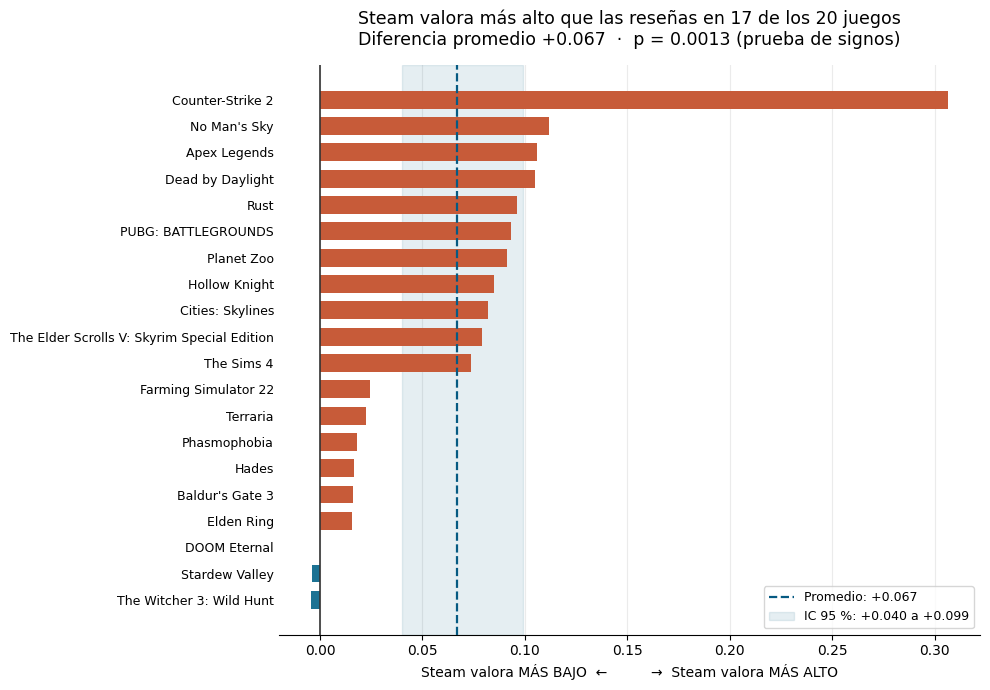

In [ ]:
# ---------------------------------------------------------------
# Figura
# ---------------------------------------------------------------
DEEP, TEAL, CORAL, GRIS = '#065A82', '#1C7293', '#C75B39', '#8A8A8A'

g = d.sort_values('diferencia').reset_index(drop=True)
colores = [CORAL if v > 0 else TEAL for v in g['diferencia']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(g['juego'], g['diferencia'], color=colores, height=0.68, zorder=3)

ax.axvline(0, color='#333333', lw=1.2, zorder=4)
ax.axvline(media_dif, color=DEEP, lw=1.6, ls='--', zorder=4,
           label=f'Promedio: {media_dif:+.3f}')
ax.axvspan(ic_bajo, ic_alto, color=DEEP, alpha=0.10, zorder=1,
           label=f'IC 95 %: {ic_bajo:+.3f} a {ic_alto:+.3f}')

ax.set_xlabel('Steam valora MÁS BAJO  ←          →  Steam valora MÁS ALTO', fontsize=10)
ax.set_title(
    f'Steam valora más alto que las reseñas en {n_arriba} de los {n_total} juegos\n'
    f'Diferencia promedio {media_dif:+.3f}  ·  p = {p_signos:.4f} (prueba de signos)',
    fontsize=12.5, pad=14)

ax.legend(loc='lower right', frameon=True, fontsize=9)
ax.grid(axis='x', alpha=0.25, zorder=0)
ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=9)

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'fig_sobreestimacion.png'), dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()


### 11.7 ¿Y si saco el caso más extremo?

Un videojuego se aparta mucho más que el resto. Eso tira el promedio para arriba, y en la
defensa alguien va a preguntar si todo el resultado depende de ese único caso. Conviene tener
la respuesta calculada de antemano en lugar de improvisarla.

La celda repite las tres pruebas **sacando el videojuego con la diferencia más grande** y
compara los resultados. Si la conclusión se sostiene sin él, el resultado no depende de un
caso aislado.

In [ ]:
# ---------------------------------------------------------------
# Analisis de sensibilidad: se quita el juego con el desvio mas grande
# ---------------------------------------------------------------
idx_extremo = d['diferencia'].abs().idxmax()
juego_extremo = d.loc[idx_extremo, 'juego']
dif_extremo = d.loc[idx_extremo, 'diferencia']

s = d.drop(index=idx_extremo)['diferencia'].values

s_total  = len(s)
s_arriba = int((s > 0).sum())
s_abajo  = int((s < 0).sum())
s_media  = s.mean()
s_mediana = float(np.median(s))

s_p_signos = stats.binomtest(k=s_arriba, n=s_total, p=0.5, alternative='greater').pvalue
_, s_p_wilcoxon = stats.wilcoxon(s, alternative='greater', zero_method='wilcox')

rng3 = np.random.default_rng(42)
s_boot = np.array([rng3.choice(s, size=len(s), replace=True).mean() for _ in range(N_BOOT)])
s_ic_bajo, s_ic_alto = np.percentile(s_boot, [2.5, 97.5])

print(f'Caso extremo: {juego_extremo}  (desvio {dif_extremo:+.4f})')
print(f'El siguiente mas grande se desvia {d["diferencia"].abs().nlargest(2).iloc[1]:.4f}')
print()
print(f'{"":<28}{"CON el caso":>14}{"SIN el caso":>14}')
print('-' * 56)
print(f'{"Juegos por encima":<28}{f"{n_arriba} de {n_total}":>14}{f"{s_arriba} de {s_total}":>14}')
print(f'{"Sobreestimacion media":<28}{media_dif:>+14.4f}{s_media:>+14.4f}')
print(f'{"Mediana":<28}{mediana_dif:>+14.4f}{s_mediana:>+14.4f}')
print(f'{"IC 95 % desde":<28}{ic_bajo:>+14.4f}{s_ic_bajo:>+14.4f}')
print(f'{"IC 95 % hasta":<28}{ic_alto:>+14.4f}{s_ic_alto:>+14.4f}')
print(f'{"p prueba de signos":<28}{p_signos:>14.5f}{s_p_signos:>14.5f}')
print(f'{"p Wilcoxon":<28}{p_wilcoxon:>14.5f}{s_p_wilcoxon:>14.5f}')
print('-' * 56)
print()

aguanta = (s_p_signos < 0.05) and (s_p_wilcoxon < 0.05) and (s_ic_bajo > 0)
if aguanta:
    print('  -> La conclusion se mantiene sin el caso extremo.')
    print('  -> El hallazgo no depende de un solo juego.')
else:
    print('  -> Sin el caso extremo la conclusion NO se mantiene.')
    print('  -> Hay que reportarlo explicitamente: el hallazgo depende de ese juego.')


Caso extremo: Counter-Strike 2  (desvio +0.3066)
El siguiente mas grande se desvia 0.1117

                               CON el caso   SIN el caso
--------------------------------------------------------
Juegos por encima                 17 de 20      16 de 19
Sobreestimacion media              +0.0667       +0.0541
Mediana                            +0.0763       +0.0737
IC 95 % desde                      +0.0401       +0.0352
IC 95 % hasta                      +0.0991       +0.0731
p prueba de signos                 0.00129       0.00221
p Wilcoxon                         0.00011       0.00016
--------------------------------------------------------

  -> La conclusion se mantiene sin el caso extremo.
  -> El hallazgo no depende de un solo juego.


### 11.8 El veredicto, en una frase

Esta celda junta todo y arma el párrafo que va al informe y la frase que se dice en la defensa.
Los números no están escritos a mano: salen de las cuentas de arriba, así que no pueden quedar
viejos si volvés a correr el notebook con más datos.

In [ ]:
# ---------------------------------------------------------------
# Conclusión redactada automáticamente
# ---------------------------------------------------------------
se_sostiene = (p_signos < 0.05) and (p_wilcoxon < 0.05) and (ic_bajo > 0)

print('=' * 72)
print('HIPÓTESIS')
print('  El sistema binario de Steam sobreestima sistemáticamente la valoración')
print('  expresada por los usuarios en sus reseñas.')
print()
print('EVIDENCIA')
print(f'  1. Reparto de los juegos : {n_arriba} de {n_total} por encima de la referencia')
print(f'  2. Prueba de signos      : p = {p_signos:.5f}')
print(f'  3. Wilcoxon              : p = {p_wilcoxon:.5f}   (efecto r = {r_efecto:.2f})')
print(f'  4. Sobreestimación media : {media_dif:+.4f}  [IC 95 %: {ic_bajo:+.4f}; {ic_alto:+.4f}]')
print(f'  5. Mediana               : {mediana_dif:+.4f}  [IC 95 %: {ic_med_bajo:+.4f}; {ic_med_alto:+.4f}]')
print(f'  6. Sin el caso extremo   : {s_arriba} de {s_total},  p = {s_p_signos:.5f},  media {s_media:+.4f}')
print()
print('VEREDICTO')
print('  LA HIPÓTESIS SE SOSTIENE.' if se_sostiene else '  LA HIPÓTESIS NO SE SOSTIENE CON ESTA EVIDENCIA.')
print('=' * 72)
print()

if se_sostiene:
    print('PÁRRAFO PARA EL INFORME')
    print('-' * 72)
    print(
f"""La comparación entre la valoración publicada por Steam y la valoración de
referencia construida por anotación manual muestra un desvío en una sola
dirección. En {n_arriba} de los {n_total} juegos analizados el porcentaje de Steam resulta
superior a la referencia. La prueba de signos rechaza la hipótesis de que
ambas direcciones sean igual de probables (p = {p_signos:.4f}), y la prueba de
Wilcoxon de una muestra, que además incorpora la magnitud de cada desvío,
llega a la misma conclusión (p = {p_wilcoxon:.4f}). La sobreestimación media es de
{media_dif:.4f} ({media_dif*100:.1f} puntos porcentuales), con un intervalo de confianza del
95 % de [{ic_bajo:.4f}; {ic_alto:.4f}] obtenido por bootstrap, enteramente por encima de
cero. La mediana, {mediana_dif:.4f}, confirma la magnitud sin verse afectada por el caso
más extremo, y al excluir ese caso el resultado se mantiene ({s_arriba} de {s_total} juegos,
p = {s_p_signos:.4f}). La evidencia sostiene la hipótesis planteada.""")
    print('-' * 72)
    print()
    print('FRASE PARA LA DEFENSA ORAL')
    print('-' * 72)
    print(
f"""Comparé el porcentaje que publica Steam contra la valoración que surge de
leer las reseñas. En {n_arriba} de {n_total} juegos Steam queda más alto. Si fuera
casualidad, eso pasaría una vez cada {una_en} estudios: es demasiado raro para
atribuirlo al azar. En promedio Steam infla la valoración {abs(media_dif)*100:.1f} puntos
porcentuales, con un margen que va de {ic_bajo*100:.0f} a {ic_alto*100:.0f} puntos. Y sacando el juego
más extremo el resultado se mantiene.""")
    print('-' * 72)


HIPÓTESIS
  El sistema binario de Steam sobreestima sistemáticamente la valoración
  expresada por los usuarios en sus reseñas.

EVIDENCIA
  1. Reparto de los juegos : 17 de 20 por encima de la referencia
  2. Prueba de signos      : p = 0.00129
  3. Wilcoxon              : p = 0.00011   (efecto r = 0.83)
  4. Sobreestimación media : +0.0667  [IC 95 %: +0.0401; +0.0991]
  5. Mediana               : +0.0763  [IC 95 %: +0.0173; +0.0923]
  6. Sin el caso extremo   : 16 de 19,  p = 0.00221,  media +0.0541

VEREDICTO
  LA HIPÓTESIS SE SOSTIENE.

PÁRRAFO PARA EL INFORME
------------------------------------------------------------------------
La comparación entre la valoración publicada por Steam y la valoración de
referencia construida por anotación manual muestra un desvío en una sola
dirección. En 17 de los 20 juegos analizados el porcentaje de Steam resulta
superior a la referencia. La prueba de signos rechaza la hipótesis de que
ambas direcciones sean igual de probables (p = 0.0013), y l

### 11.9 Guardamos los resultados

Un CSV con las diferencias juego por juego y otro con los números de las pruebas, para poder
citarlos en el informe sin tener que volver a correr nada.

In [ ]:
# ---------------------------------------------------------------
# Guardado
# ---------------------------------------------------------------
d.to_csv(os.path.join(CHECKPOINT_DIR, 'prueba_sobreestimacion.csv'), index=False)

resumen = pd.DataFrame([{
    'n_juegos': n_total,
    'n_steam_mas_alto': n_arriba,
    'n_steam_mas_bajo': n_abajo,
    'n_empates': n_empate,
    'diferencia_media': round(media_dif, 5),
    'diferencia_mediana': round(mediana_dif, 5),
    'ic95_bajo': round(ic_bajo, 5),
    'ic95_alto': round(ic_alto, 5),
    'ic95_mediana_bajo': round(ic_med_bajo, 5),
    'ic95_mediana_alto': round(ic_med_alto, 5),
    'p_prueba_signos': round(p_signos, 6),
    'p_signos_sin_empate': round(p_signos_sin_empate, 6),
    'p_wilcoxon': round(p_wilcoxon, 6),
    'tamano_efecto_r': round(r_efecto, 4),
    'caso_extremo': juego_extremo,
    'sens_n_arriba': s_arriba,
    'sens_n_total': s_total,
    'sens_media': round(s_media, 5),
    'sens_p_signos': round(s_p_signos, 6),
    'sens_p_wilcoxon': round(s_p_wilcoxon, 6),
    'sens_conclusion_aguanta': bool(aguanta),
    'hipotesis_sostenida': bool(se_sostiene),
}])
resumen.to_csv(os.path.join(CHECKPOINT_DIR, 'resumen_prueba_sobreestimacion.csv'), index=False)

print('Guardado en', CHECKPOINT_DIR)
print('  - prueba_sobreestimacion.csv          (una fila por juego)')
print('  - resumen_prueba_sobreestimacion.csv  (los números de las pruebas)')
print('  - fig_sobreestimacion.png             (el gráfico)')
resumen.T


Guardado en /content/drive/MyDrive/tesina_steam/checkpoints
  - prueba_sobreestimacion.csv          (una fila por juego)
  - resumen_prueba_sobreestimacion.csv  (los números de las pruebas)
  - fig_sobreestimacion.png             (el gráfico)


,0
n_juegos,20
n_steam_mas_alto,17
n_steam_mas_bajo,2
n_empates,1
diferencia_media,0.0667
diferencia_mediana,0.0763
ic95_bajo,0.0401
ic95_alto,0.0991
ic95_mediana_bajo,0.0173
ic95_mediana_alto,0.0923


## 12 · Efecto de la ponderación por tiempo de juego

**La pregunta.** La sección 9 mostró que ponderar según el tiempo de juego aleja la
medición de la valoración de referencia. Lo que ese resultado no dice es **hacia dónde** la
mueve, ni si el efecto aparece también cuando la ponderación se aplica sola, sin la categoría
intermedia.

**Por qué importa.** La respuesta cambia lo que puede afirmarse en el informe:

- Si la ponderación **sube** el número, entonces quienes más jugaron valoraron más alto, y
  darles más peso agranda la diferencia con la referencia.
- Si lo **baja**, entonces quienes más jugaron son más críticos, y la diferencia proviene de
  otro lado.

**El esquema que lo aísla.** En la sección 9 se calculó `binario_horas_creciente`: el voto
de Steam ponderado por horas, sin categoría intermedia. Comparado contra `binario`, deja a la
ponderación como única diferencia entre ambos.

In [ ]:
# ---------------------------------------------------------------
# Configuración y carga
# ---------------------------------------------------------------
USE_DRIVE = True

import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    CHECKPOINT_DIR = '/content/drive/MyDrive/tesina_steam/checkpoints'
else:
    CHECKPOINT_DIR = 'checkpoints'

comp = pd.read_csv(os.path.join(CHECKPOINT_DIR, 'comparacion_sistemas_por_juego.csv'))
print('Juegos:', len(comp))
print('Columnas:', list(comp.columns))


Mounted at /content/drive
Juegos: 20
Columnas: ['juego', 'referencia', 'ee_referencia', 'n_anotadas', 'n_pos', 'n_neg', 'genero', 'binario', 'tres_uniforme', 'tres_horas_creciente', 'tres_horas_decreciente', 'tres_compromiso', 'binario_horas_creciente']


### 12.1 ¿Hacia dónde mueve el número la ponderación?

Se comparan dos pares. En cada uno, lo único que cambia es si se pondera o no:

| Par | Sin ponderar | Ponderado | Qué aísla |
|---|---|---|---|
| A | `binario` | `binario_horas_creciente` | el efecto de la ponderación **sola** |
| B | `tres_uniforme` | `tres_horas_creciente` | el efecto dentro del esquema de tres |

Si el número sube, quienes más jugaron valoraron más alto.

In [ ]:
# ---------------------------------------------------------------
# Dirección del movimiento
# ---------------------------------------------------------------
col_juego = next((c for c in ['juego','nombre','app_name'] if c in comp.columns),
                 comp.columns[0])

PARES = [
    ('Ponderación SOLA (sobre el voto de Steam)', 'binario', 'binario_horas_creciente'),
    ('Ponderación dentro del esquema de tres',    'tres_uniforme', 'tres_horas_creciente'),
]

d = comp[[col_juego, 'referencia']].copy()
d.columns = ['juego', 'referencia']

resultados = {}
for nombre, sin_p, con_p in PARES:
    if sin_p not in comp.columns or con_p not in comp.columns:
        print(f'  (falta {sin_p} o {con_p}, se omite)')
        continue
    mov = comp[con_p] - comp[sin_p]
    d[f'mov_{sin_p}'] = mov.values
    resultados[nombre] = mov.values

    sube = int((mov > 0).sum()); baja = int((mov < 0).sum())
    print('=' * 70)
    print(nombre)
    print('=' * 70)
    print(f'  Sube el número en : {sube} de {len(mov)} juegos')
    print(f'  Baja el número en : {baja} de {len(mov)} juegos')
    print(f'  Movimiento promedio: {mov.mean():+.4f}')
    print(f'  Movimiento mediano : {mov.median():+.4f}')
    if sube > baja:
        print('  -> Quien más jugó valoró MÁS ALTO. Ponderar infla la valoración.')
    elif baja > sube:
        print('  -> Quien más jugó valoró MÁS BAJO. Ponderar baja la valoración.')
    print()


Ponderación SOLA (sobre el voto de Steam)
  Sube el número en : 17 de 20 juegos
  Baja el número en : 3 de 20 juegos
  Movimiento promedio: +0.0079
  Movimiento mediano : +0.0040
  -> Quien más jugó valoró MÁS ALTO. Ponderar infla la valoración.

Ponderación dentro del esquema de tres
  Sube el número en : 15 de 20 juegos
  Baja el número en : 5 de 20 juegos
  Movimiento promedio: +0.0046
  Movimiento mediano : +0.0031
  -> Quien más jugó valoró MÁS ALTO. Ponderar infla la valoración.



### 12.2 ¿La ponderación sola acerca o aleja de la referencia?

Se mide la distancia de cada esquema a la valoración de referencia, videojuego por
videojuego, y se comparan de a pares.

Si la ponderación aplicada **sola** sobre el voto de Steam también aleja, entonces el efecto
proviene de la ponderación misma y no de su combinación con la categoría intermedia.

In [ ]:
# ---------------------------------------------------------------
# Error contra la referencia, con y sin ponderación
# ---------------------------------------------------------------
ref = comp['referencia'].values

def err(col):
    return np.abs(comp[col].values - ref)

tabla = []
for nombre, sin_p, con_p in PARES:
    if sin_p not in comp.columns or con_p not in comp.columns:
        continue
    e_sin, e_con = err(sin_p), err(con_p)
    mejora = int((e_con < e_sin).sum())
    empeora = int((e_con > e_sin).sum())

    # prueba apareada: cada juego aporta su error con y sin ponderar
    _, p_wil = stats.wilcoxon(e_con, e_sin, alternative='greater')
    p_signos = stats.binomtest(empeora, len(e_sin), 0.5, alternative='greater').pvalue

    print('=' * 70)
    print(nombre)
    print('=' * 70)
    print(f'  Error promedio sin ponderar : {e_sin.mean():.4f}')
    print(f'  Error promedio ponderado    : {e_con.mean():.4f}')
    print(f'  Diferencia                  : {e_con.mean()-e_sin.mean():+.4f}')
    print()
    print(f'  Mejora  (se acerca) en : {mejora} de {len(e_sin)} juegos')
    print(f'  Empeora (se aleja)  en : {empeora} de {len(e_sin)} juegos')
    print()
    print(f'  Prueba de signos (empeora) : p = {p_signos:.5f}')
    print(f'  Wilcoxon apareado          : p = {p_wil:.5f}')
    print()
    veredicto = ('ALEJA de la referencia' if e_con.mean() > e_sin.mean()
                 else 'ACERCA a la referencia')
    sig = 'de forma significativa' if min(p_signos, p_wil) < 0.05 else 'sin significación'
    print(f'  -> La ponderación {veredicto}, {sig}.')
    print()

    tabla.append({
        'comparacion': nombre, 'sin_ponderar': sin_p, 'ponderado': con_p,
        'error_sin': round(float(e_sin.mean()), 5),
        'error_con': round(float(e_con.mean()), 5),
        'juegos_mejora': mejora, 'juegos_empeora': empeora,
        'p_signos': round(float(p_signos), 6), 'p_wilcoxon': round(float(p_wil), 6),
    })


Ponderación SOLA (sobre el voto de Steam)
  Error promedio sin ponderar : 0.0676
  Error promedio ponderado    : 0.0748
  Diferencia                  : +0.0073

  Mejora  (se acerca) en : 4 de 20 juegos
  Empeora (se aleja)  en : 16 de 20 juegos

  Prueba de signos (empeora) : p = 0.00591
  Wilcoxon apareado          : p = 0.01332

  -> La ponderación ALEJA de la referencia, de forma significativa.

Ponderación dentro del esquema de tres
  Error promedio sin ponderar : 0.0432
  Error promedio ponderado    : 0.0464
  Diferencia                  : +0.0031

  Mejora  (se acerca) en : 10 de 20 juegos
  Empeora (se aleja)  en : 10 de 20 juegos

  Prueba de signos (empeora) : p = 0.58810
  Wilcoxon apareado          : p = 0.32383

  -> La ponderación ALEJA de la referencia, sin significación.



### 12.3 El gráfico

Cada barra es un videojuego: cuánto mueve la ponderación el número respecto del mismo esquema
sin ponderar. Hacia la derecha significa que ponderar **sube** la valoración.

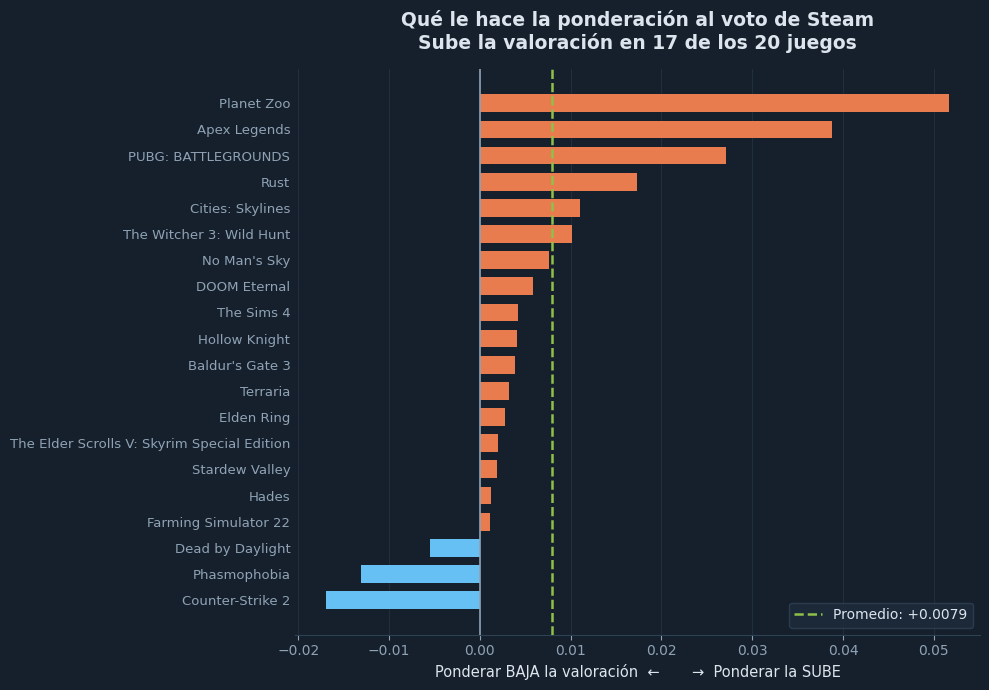

In [ ]:
# ---------------------------------------------------------------
# Figura (fondo oscuro, para que combine con la presentación)
# ---------------------------------------------------------------
FONDO, TEXTO, TENUE = '#16202C', '#DCE5ED', '#8FA3B5'
GRID, AZUL, CORAL, VERDE = '#2E4255', '#66C0F4', '#E87C4E', '#8FC04A'
plt.rcParams.update({'figure.facecolor': FONDO, 'axes.facecolor': FONDO,
                     'savefig.facecolor': FONDO, 'text.color': TEXTO,
                     'axes.labelcolor': TEXTO, 'xtick.color': TENUE,
                     'ytick.color': TENUE, 'axes.edgecolor': GRID,
                     'grid.color': GRID})

COL = 'mov_binario'
if COL in d.columns:
    g = d[['juego', COL]].sort_values(COL).reset_index(drop=True)
    colores = [CORAL if v > 0 else AZUL for v in g[COL]]

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(g['juego'], g[COL], color=colores, height=0.68, zorder=3)
    ax.axvline(0, color=TENUE, lw=1.2, zorder=4)
    prom = g[COL].mean()
    ax.axvline(prom, color=VERDE, lw=1.8, ls='--', zorder=4,
               label=f'Promedio: {prom:+.4f}')

    sube = int((g[COL] > 0).sum())
    ax.set_xlabel('Ponderar BAJA la valoración  ←       →  Ponderar la SUBE', fontsize=10.5)
    ax.set_title('Qué le hace la ponderación al voto de Steam\n'
                 f'Sube la valoración en {sube} de los {len(g)} juegos',
                 fontsize=13.5, fontweight='bold', pad=14, color=TEXTO)
    leg = ax.legend(loc='lower right', frameon=True, fontsize=10,
                    facecolor='#1E2C3C', edgecolor=GRID)
    for t in leg.get_texts(): t.set_color(TEXTO)
    ax.grid(axis='x', alpha=.45, zorder=0); ax.set_axisbelow(True)
    for sp in ('top', 'right', 'left'): ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0, labelsize=9.5)
    plt.tight_layout()
    plt.savefig(os.path.join(CHECKPOINT_DIR, 'fig_efecto_ponderacion.png'),
                dpi=190, facecolor=FONDO, bbox_inches='tight')
    plt.show()


### 12.4 La conclusión, redactada

Esta celda arma la frase que puede afirmarse en el informe a partir de los números, sin
escribirla de antemano.

In [ ]:
# ---------------------------------------------------------------
# Redacción automática
# ---------------------------------------------------------------
res = pd.DataFrame(tabla)
res.to_csv(os.path.join(CHECKPOINT_DIR, 'efecto_ponderacion.csv'), index=False)

print('=' * 72)
print('LO QUE SE PUEDE AFIRMAR')
print('=' * 72)
print()

if 'mov_binario' in d.columns:
    mov = d['mov_binario'].values
    sube, baja = int((mov > 0).sum()), int((mov < 0).sum())
    p_dir = stats.binomtest(max(sube, baja), len(mov), 0.5, alternative='greater').pvalue
    direccion = 'más alto' if sube > baja else 'más bajo'
    print(f'DIRECCIÓN')
    print(f'  Ponderar por horas sube la valoración en {sube} de {len(mov)} juegos')
    print(f'  (p = {p_dir:.5f}). Es decir: quien acumuló más horas votó {direccion}.')
    print()

fila = res[res['sin_ponderar'] == 'binario']
if len(fila):
    f = fila.iloc[0]
    print('EFECTO SOBRE LA FIDELIDAD, CON LA PONDERACIÓN SOLA')
    print(f'  Error del voto de Steam sin ponderar : {f["error_sin"]:.4f}')
    print(f'  Error del voto de Steam ponderado    : {f["error_con"]:.4f}')
    print(f'  Se aleja en {f["juegos_empeora"]} de 20 juegos, p = {f["p_signos"]:.4f}')
    print()
    if f['error_con'] > f['error_sin']:
        print('  PÁRRAFO PARA EL INFORME')
        print('  ' + '-' * 68)
        print(f"""  Ponderar las reseñas por horas de juego, aplicado directamente sobre el
  voto de la plataforma, no corrige la sobreestimación sino que la amplía:
  el error medio respecto de la referencia pasa de {f["error_sin"]:.4f} a {f["error_con"]:.4f}.
  El efecto tiene una dirección definida: la ponderación eleva la valoración
  del juego, lo que indica que los usuarios con más horas acumuladas emiten
  voto positivo con mayor frecuencia que el conjunto. En consecuencia,
  asignarles mayor peso desplaza la medición en el mismo sentido del sesgo
  que se buscaba corregir.""")
        print('  ' + '-' * 68)

print()
print('Guardado:')
print('  - efecto_ponderacion.csv')
print('  - fig_efecto_ponderacion.png')
res.T


LO QUE SE PUEDE AFIRMAR

DIRECCIÓN
  Ponderar por horas sube la valoración en 17 de 20 juegos
  (p = 0.00129). Es decir: quien acumuló más horas votó más alto.

EFECTO SOBRE LA FIDELIDAD, CON LA PONDERACIÓN SOLA
  Error del voto de Steam sin ponderar : 0.0676
  Error del voto de Steam ponderado    : 0.0748
  Se aleja en 16 de 20 juegos, p = 0.0059

  PÁRRAFO PARA EL INFORME
  --------------------------------------------------------------------
  Ponderar las reseñas por horas de juego, aplicado directamente sobre el
  voto de la plataforma, no corrige la sobreestimación sino que la amplía:
  el error medio respecto de la referencia pasa de 0.0676 a 0.0748.
  El efecto tiene una dirección definida: la ponderación eleva la valoración
  del juego, lo que indica que los usuarios con más horas acumuladas emiten
  voto positivo con mayor frecuencia que el conjunto. En consecuencia,
  asignarles mayor peso desplaza la medición en el mismo sentido del sesgo
  que se buscaba corregir.
  -------

,0,1
comparacion,Ponderación SOLA (sobre el voto de Steam),Ponderación dentro del esquema de tres
sin_ponderar,binario,tres_uniforme
ponderado,binario_horas_creciente,tres_horas_creciente
error_sin,0.06757,0.04325
error_con,0.07484,0.04637
juegos_mejora,4,10
juegos_empeora,16,10
p_signos,0.005909,0.588099
p_wilcoxon,0.013321,0.323828


### 12.5 Qué dieron los números

**La ponderación sube el número en los dos pares.** Sobre el voto binario, la diferencia con
la referencia pasa de +6,67 a +7,47 puntos porcentuales, y sube en 17 de los 20 videojuegos.
Sobre el esquema de tres categorías pasa de −1,65 a −1,19, y sube en 15 de 20.

**Y aleja de la referencia en los dos casos.** La distancia promedio pasa de 6,76 a 7,48
puntos en el sistema binario, y de 4,32 a 4,64 en el de tres categorías.

De ahí se sigue que quienes acumulan más horas valoran en promedio más alto, de modo que
darles más peso agranda la diferencia con la referencia en lugar de reducirla. El efecto
aparece con la ponderación aplicada sola, así que proviene de la ponderación misma y no de su
combinación con la categoría intermedia.

Conviene no confundir este resultado con el de la línea previa de la sección A.1, que señalaba
que las reseñas con mayor `ratio_compromiso` resultaban más críticas. Son variables distintas:
`ratio_compromiso` es la proporción del tiempo total jugada al momento de escribir, y acá se
pondera por horas absolutas. Su correlación de rangos es de 0,02, de modo que no hay
contradicción entre ambos resultados.

## 13 · Gráficos de resultados

Genera seis figuras a partir de los resultados de las secciones 8 y 9, que hasta acá solo
existían como tablas de números:

1. **Diferencia entre el voto binario y la valoración de referencia**, por videojuego.
2. **Distancia de cada esquema de agregación** respecto de la referencia.
3. **Desempeño de los tres modelos por categoría.**
4. **Matrices de comparación** entre la clasificación manual y la del modelo.
5. **Composición del conjunto clasificado a mano.**
6. **Rendimientos decrecientes** de seguir clasificando reseñas.

Las figuras que finalmente se incluyeron en el informe se generaron aparte, con el mismo
criterio visual del resto del documento. Las de esta sección se conservan como material de
trabajo y respaldo de los mismos resultados.

### 13.1 Configuración

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json, os
from matplotlib.patches import Patch

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

FIG_DIR = os.path.join(CHECKPOINT_DIR, "figuras_resultados")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 12, "figure.dpi": 130, "savefig.bbox": "tight",
})

TEAL   = "#1D9E75"   # esquema de tres categorías
CORAL  = "#D85A30"   # sistema binario
GRIS   = "#8B8880"
AZUL   = "#3D7EA6"
AMBAR  = "#C9A227"

def guardar(fig, nombre):
    ruta = os.path.join(FIG_DIR, nombre)
    fig.savefig(ruta)
    print(f"  guardada: {nombre}")

comparacion = pd.read_csv(os.path.join(CHECKPOINT_DIR, "comparacion_sistemas_por_juego.csv"))
errores = pd.read_csv(os.path.join(CHECKPOINT_DIR, "errores_por_juego.csv"), index_col=0)
print(f"Juegos: {len(comparacion)}")


Mounted at /content/drive
Juegos: 20


### 13.2 Figura 1 — La diferencia entre ambas mediciones

Cada videojuego aparece dos veces: la valoración de referencia, construida leyendo las
reseñas, y el porcentaje que publica Steam. La separación entre ambos puntos es la diferencia
que mide el trabajo, y su dirección muestra que no se reparte hacia ambos lados.

  guardada: fig1_sobreestimacion_binario.png


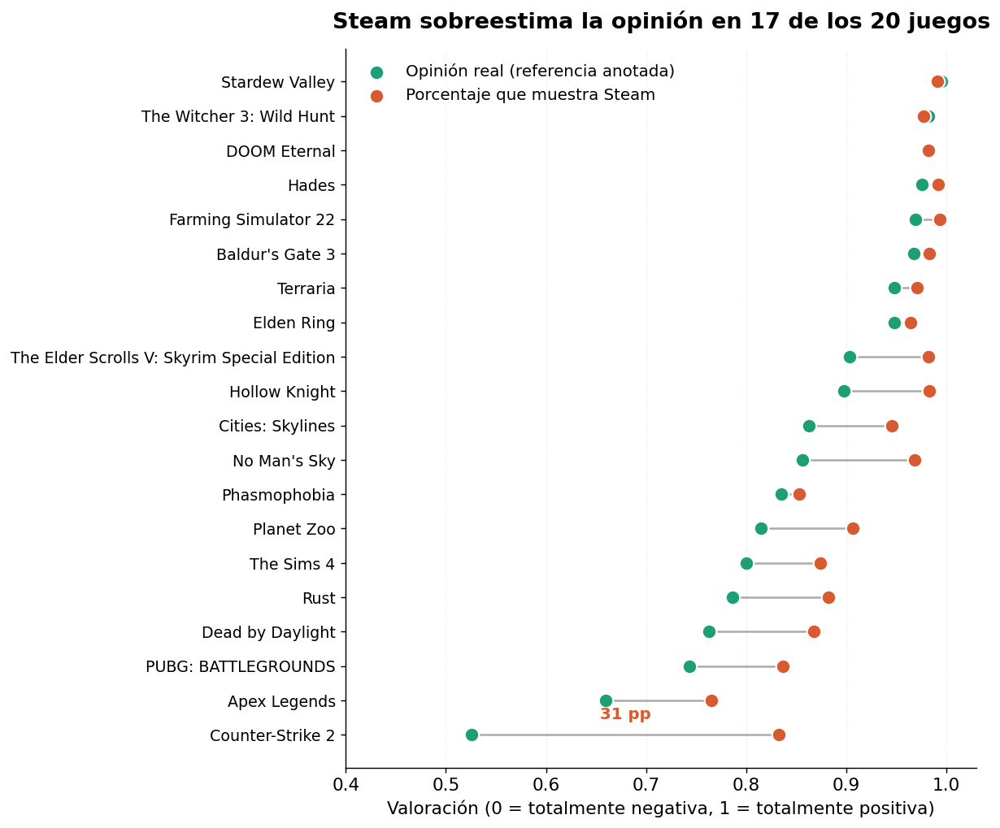


Sesgo medio: +0.0667
Sobreestima en 17 de 20 juegos


In [ ]:
d = comparacion.sort_values("referencia").reset_index(drop=True)
y = np.arange(len(d))

fig, ax = plt.subplots(figsize=(9.5, 8))

# línea que une ambos puntos
for i, fila in d.iterrows():
    ax.plot([fila["referencia"], fila["binario"]], [i, i],
            color=GRIS, lw=1.4, zorder=1, alpha=0.7)

ax.scatter(d["referencia"], y, s=95, color=TEAL, zorder=3,
           label="Opinión real (referencia anotada)", edgecolor="white", linewidth=1.2)
ax.scatter(d["binario"], y, s=95, color=CORAL, zorder=3,
           label="Porcentaje que muestra Steam", edgecolor="white", linewidth=1.2)

ax.set_yticks(y)
ax.set_yticklabels(d["juego"], fontsize=10.5)
ax.set_xlabel("Valoración (0 = totalmente negativa, 1 = totalmente positiva)")
n_sobre = int((d["binario"] > d["referencia"]).sum())
ax.set_title(f"Steam sobreestima la opinión en {n_sobre} de los {len(d)} juegos", pad=14)
ax.set_xlim(0.4, 1.03)
ax.grid(axis="x", alpha=0.25, linestyle=":")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=11)

# destacar el caso extremo
peor = d["binario"].sub(d["referencia"]).idxmax()
ax.annotate(f"{(d.loc[peor,'binario']-d.loc[peor,'referencia'])*100:.0f} pp",
            xy=((d.loc[peor,"referencia"]+d.loc[peor,"binario"])/2, peor),
            xytext=(0, 11), textcoords="offset points",
            ha="center", fontsize=11, fontweight="bold", color=CORAL)

plt.tight_layout()
guardar(fig, "fig1_sobreestimacion_binario.png")
plt.show()

print(f"\nSesgo medio: {(d['binario']-d['referencia']).mean():+.4f}")
print(f"Sobreestima en {int((d['binario']>d['referencia']).sum())} de {len(d)} juegos")


### 13.3 Figura 2 — Distancia de cada esquema de agregación

Cuánto se aparta cada sistema del valor de referencia, en valor absoluto. Se colorea según la
naturaleza del esquema, para que se lea de un vistazo que los de tres categorías ocupan las
primeras posiciones y los binarios las últimas.

  guardada: fig2_mae_esquemas.png


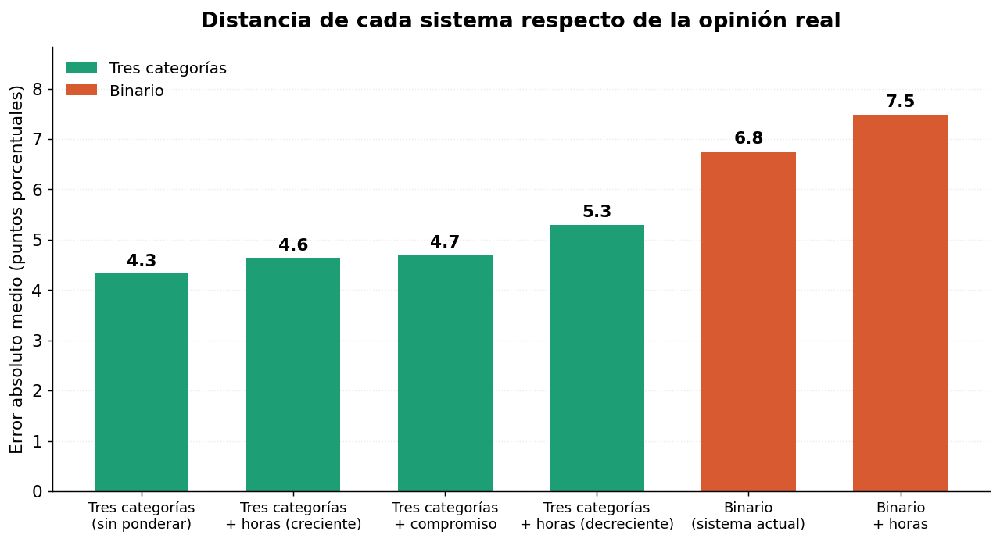

In [ ]:
mae = errores.mean().sort_values()

NOMBRES = {
    "tres_uniforme": "Tres categorías\n(sin ponderar)",
    "tres_horas_creciente": "Tres categorías\n+ horas (creciente)",
    "tres_compromiso": "Tres categorías\n+ compromiso",
    "tres_horas_decreciente": "Tres categorías\n+ horas (decreciente)",
    "binario": "Binario\n(sistema actual)",
    "binario_horas_creciente": "Binario\n+ horas",
}
colores = [TEAL if k.startswith("tres") else CORAL for k in mae.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(range(len(mae)), mae.values * 100, color=colores, width=0.62)

for i, v in enumerate(mae.values * 100):
    ax.text(i, v + 0.15, f"{v:.1f}", ha="center", fontsize=12, fontweight="bold")

ax.set_xticks(range(len(mae)))
ax.set_xticklabels([NOMBRES[k] for k in mae.index], fontsize=10)
ax.set_ylabel("Error absoluto medio (puntos porcentuales)")
ax.set_title("Distancia de cada sistema respecto de la opinión real", pad=14)
ax.set_ylim(0, max(mae.values * 100) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25, linestyle=":")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(facecolor=TEAL, label="Tres categorías"),
                   Patch(facecolor=CORAL, label="Binario")],
          frameon=False, loc="upper left", fontsize=11)

plt.tight_layout()
guardar(fig, "fig2_mae_esquemas.png")
plt.show()


### 13.4 Figura 3 — Desempeño de los modelos por categoría

Muestra dónde está la ganancia del ajuste al dominio: la categoría negativa prácticamente no
se mueve, mientras que la intermedia pasa de 0,150 a 0,407.

Datos cargados del archivo de resultados.
  guardada: fig3_f1_por_clase.png


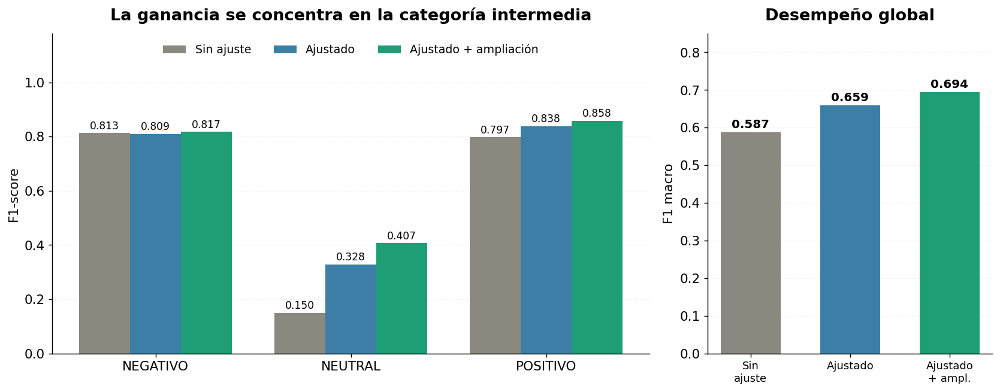

In [ ]:
ruta_json = os.path.join(CHECKPOINT_DIR, "resultado_objetivo_3_ampliado.json")
if os.path.exists(ruta_json):
    with open(ruta_json) as f:
        res3 = json.load(f)
    print("Datos cargados del archivo de resultados.")
else:
    res3 = None
    print("No se encontró el JSON; se usan los valores reportados.")

CLASES = ["NEGATIVO", "NEUTRAL", "POSITIVO"]
datos = {
    "Sin ajuste":            [0.813, 0.150, 0.797],
    "Ajustado":              [0.809, 0.328, 0.838],
    "Ajustado + ampliación": [0.817, 0.407, 0.858],
}
f1_macro = {"Sin ajuste": 0.587, "Ajustado": 0.659, "Ajustado + ampliación": 0.694}

x = np.arange(len(CLASES))
ancho = 0.26
tonos = [GRIS, AZUL, TEAL]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2),
                               gridspec_kw={"width_ratios": [2.1, 1]})

for i, (nombre, vals) in enumerate(datos.items()):
    pos = x + (i - 1) * ancho
    ax1.bar(pos, vals, ancho, label=nombre, color=tonos[i])
    for xp, v in zip(pos, vals):
        ax1.text(xp, v + 0.015, f"{v:.3f}", ha="center", fontsize=9.5)

ax1.set_xticks(x)
ax1.set_xticklabels(CLASES)
ax1.set_ylabel("F1-score")
ax1.set_title("La ganancia se concentra en la categoría intermedia", pad=12)
ax1.set_ylim(0, 1.18)
ax1.legend(frameon=False, fontsize=10.5, loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.0))
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.25, linestyle=":")
ax1.set_axisbelow(True)

nombres = list(f1_macro)
ax2.bar(range(3), [f1_macro[n] for n in nombres], color=tonos, width=0.6)
for i, n in enumerate(nombres):
    ax2.text(i, f1_macro[n] + 0.012, f"{f1_macro[n]:.3f}",
             ha="center", fontsize=11, fontweight="bold")
ax2.set_xticks(range(3))
ax2.set_xticklabels(["Sin\najuste", "Ajustado", "Ajustado\n+ ampl."], fontsize=10)
ax2.set_ylabel("F1 macro")
ax2.set_title("Desempeño global", pad=12)
ax2.set_ylim(0, 0.85)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.25, linestyle=":")
ax2.set_axisbelow(True)

plt.tight_layout()
guardar(fig, "fig3_f1_por_clase.png")
plt.show()


### 13.5 Figura 4 — Matrices de comparación

Muestra en qué se aparta cada modelo de la clasificación manual. Se normaliza por fila para
poder comparar entre categorías de tamaño muy distinto.

  guardada: fig4_matrices_confusion.png


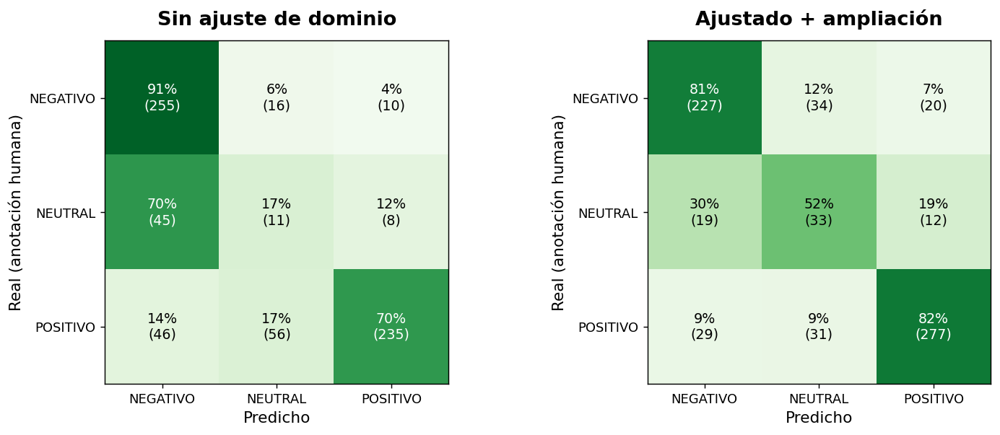

In [ ]:
ruta_oof = os.path.join(CHECKPOINT_DIR, "predicciones_oof_v2.csv")
if not os.path.exists(ruta_oof):
    print("Falta predicciones_oof_v2.csv — se omite esta figura.")
else:
    from sklearn.metrics import confusion_matrix
    oof = pd.read_csv(ruta_oof)
    y_real = oof["etiqueta_manual"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, (col, titulo) in zip(axes, [("pred_base", "Sin ajuste de dominio"),
                                        ("pred_v2", "Ajustado + ampliación")]):
        cm = confusion_matrix(y_real, oof[col], labels=CLASES)
        cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

        im = ax.imshow(cm_pct, cmap="Greens", vmin=0, vmax=100)
        ax.set_xticks(range(3)); ax.set_xticklabels(CLASES, fontsize=10)
        ax.set_yticks(range(3)); ax.set_yticklabels(CLASES, fontsize=10)
        ax.set_xlabel("Predicho"); ax.set_ylabel("Real (anotación humana)")
        ax.set_title(titulo, pad=12)

        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{cm_pct[i,j]:.0f}%\n({cm[i,j]})", ha="center", va="center",
                        fontsize=10.5, color="white" if cm_pct[i,j] > 55 else "black")

    plt.tight_layout()
    guardar(fig, "fig4_matrices_confusion.png")
    plt.show()


### 13.6 Figura 5 — Composición del conjunto clasificado a mano

Explica de dónde salen las reseñas clasificadas y por qué cada tanda cumple un papel distinto.
Sirve para responder de antemano por qué las seleccionadas por incertidumbre no entran en la
evaluación ni en la referencia.

  guardada: fig5_composicion_corpus.png


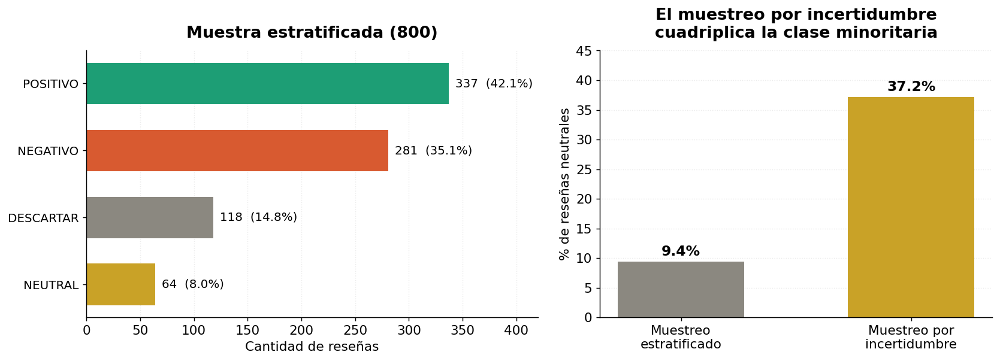

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8),
                               gridspec_kw={"width_ratios": [1.15, 1]})

# --- panel izquierdo: distribución de las 800 ---
cats = ["POSITIVO", "NEGATIVO", "DESCARTAR", "NEUTRAL"]
vals = [337, 281, 118, 64]
cols = [TEAL, CORAL, GRIS, AMBAR]

barras = ax1.barh(range(4), vals, color=cols, height=0.62)
for i, v in enumerate(vals):
    ax1.text(v + 6, i, f"{v}  ({v/800*100:.1f}%)", va="center", fontsize=11)
ax1.set_yticks(range(4)); ax1.set_yticklabels(cats, fontsize=11)
ax1.invert_yaxis()
ax1.set_xlabel("Cantidad de reseñas")
ax1.set_title("Muestra estratificada (800)", pad=12)
ax1.set_xlim(0, 420)
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="x", alpha=0.25, linestyle=":")
ax1.set_axisbelow(True)

# --- panel derecho: neutrales según método de selección ---
metodos = ["Muestreo\nestratificado", "Muestreo por\nincertidumbre"]
pct_neutral = [9.4, 37.2]
ax2.bar(metodos, pct_neutral, color=[GRIS, AMBAR], width=0.55)
for i, v in enumerate(pct_neutral):
    ax2.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=13, fontweight="bold")
ax2.set_ylabel("% de reseñas neutrales")
ax2.set_title("El muestreo por incertidumbre\ncuadriplica la clase minoritaria", pad=12)
ax2.set_ylim(0, 45)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.25, linestyle=":")
ax2.set_axisbelow(True)

plt.tight_layout()
guardar(fig, "fig5_composicion_conjunto.png")
plt.show()


### 13.7 Figura 6 — Rendimientos decrecientes de la clasificación

Justifica visualmente por qué no se persiguió la significación clasificando más reseñas.
Muestra cuánto se gana por cada tanda adicional y dónde estaría el umbral.

  guardada: fig6_analisis_potencia.png


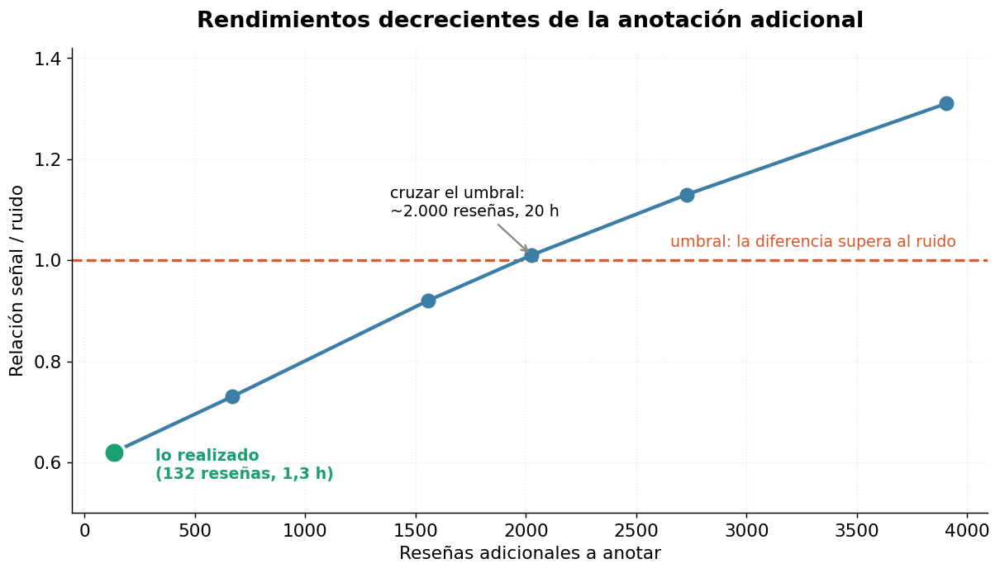


Todas las figuras quedaron en: /content/drive/MyDrive/tesina_steam/checkpoints/figuras_resultados


In [ ]:
objetivos = [30, 60, 100, 120, 150, 200]
a_anotar  = [132, 669, 1556, 2025, 2729, 3905]
senal_ruido = [0.62, 0.73, 0.92, 1.01, 1.13, 1.31]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(a_anotar, senal_ruido, marker="o", color=AZUL, lw=2.4, markersize=9, zorder=3)

ax.axhline(1.0, color=CORAL, ls="--", lw=1.8, zorder=2)
ax.text(3950, 1.02, "umbral: la diferencia supera al ruido",
        ha="right", va="bottom", fontsize=10.5, color=CORAL)

# marcar el punto alcanzado
ax.scatter([132], [0.62], s=200, color=TEAL, zorder=4, edgecolor="white", linewidth=2)
ax.annotate("lo realizado\n(132 reseñas, 1,3 h)", xy=(132, 0.62), xytext=(28, -18),
            textcoords="offset points", fontsize=10.5, color=TEAL, fontweight="bold")

ax.annotate("cruzar el umbral:\n~2.000 reseñas, 20 h", xy=(2025, 1.01), xytext=(-95, 26),
            textcoords="offset points", fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color=GRIS, lw=1.3))

ax.set_xlabel("Reseñas adicionales a anotar")
ax.set_ylabel("Relación señal / ruido")
ax.set_title("Rendimientos decrecientes de la anotación adicional", pad=14)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, linestyle=":")
ax.set_axisbelow(True)
ax.set_ylim(0.5, 1.42)

plt.tight_layout()
guardar(fig, "fig6_analisis_potencia.png")
plt.show()

print(f"\nTodas las figuras quedaron en: {FIG_DIR}")


### 13.8 Figura 7 — Holgura del voto positivo contra el reparto del voto

Es la figura que cierra la discusión del informe. Para cada videojuego se toman **solo las
reseñas con voto positivo** y se mide cuánto le falta al promedio de su valoración manual
para llegar a un positivo pleno. Esa distancia se confronta con el porcentaje de votos
positivos del videojuego: cuanto más unánime es el público, menos se aparta el voto
positivo de lo que dice el texto.

Resenas del conjunto de referencia: 801

Correlacion de Pearson : r = -0.6496   p = 0.0019
Sin Counter-Strike 2   : r = -0.6981   p = 0.0009

Holgura media          : 8.45 puntos
Maxima                 : 38.89  (Counter-Strike 2)
Minima                 : 0.00  (The Witcher 3: Wild Hunt)

  #  videojuego                        votos +    holgura
  1  Apex Legends                        76.5       15.6
  2  Counter-Strike 2                    83.3       38.9
  3  PUBG: BATTLEGROUNDS                 83.6       12.5
  4  Phasmophobia                        85.3        2.8
  5  Dead by Daylight                    86.8       14.0
  6  The Sims 4                          87.4       10.7
  7  Rust                                88.2       12.5
  8  Planet Zoo                          90.6       11.5
  9  Cities: Skylines                    94.5        8.7
 10  Elden Ring                          96.4        2.5
 11  No Man's Sky                        96.8       11.5
 12  Terraria             

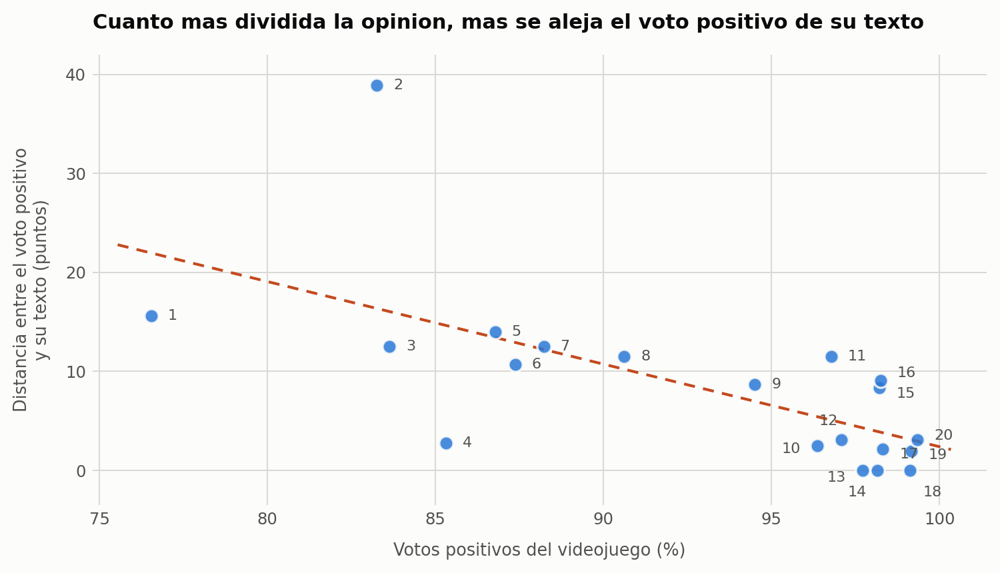

In [ ]:
# ---------------------------------------------------------------
# Holgura del voto positivo contra el reparto del voto
#
# Para cada videojuego se mide cuanto le falta al voto positivo para
# describir lo que dice el texto: se promedia la valoracion manual de
# las resenas que SI tienen voto positivo y se mira cuanto queda por
# debajo de 1. Esa distancia se confronta con el porcentaje de votos
# positivos del videojuego.
# ---------------------------------------------------------------
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

VALOR = {'POSITIVO': 1.0, 'NEUTRAL': 0.5, 'NEGATIVO': 0.0}

def _leer(nombre):
    return pd.read_csv(os.path.join(CHECKPOINT_DIR, nombre), encoding='utf-8-sig')

# clave: a que videojuego pertenece cada resena y que voto tenia
clave = pd.concat([
    _leer('muestra_clave.csv')[['recommendationid', 'juego', 'voted_up']],
    _leer('referencia_ampliada_clave.csv')[['recommendationid', 'juego', 'voted_up']],
], ignore_index=True)
clave['voted_up'] = clave['voted_up'].astype(str).str.lower().isin(['true', '1'])

# las 801 etiquetas que forman el conjunto de referencia
etiquetas = pd.concat([
    _leer('etiquetas_manuales_final.csv')[['recommendationid', 'etiqueta_manual']],
    _leer('etiquetas_referencia_ampliada.csv')[['recommendationid', 'etiqueta_manual']],
], ignore_index=True)
etiquetas = etiquetas[etiquetas['etiqueta_manual'] != 'DESCARTAR']

ref = etiquetas.merge(clave, on='recommendationid', how='inner')
ref['valor_humano'] = ref['etiqueta_manual'].map(VALOR)
print(f'Resenas del conjunto de referencia: {len(ref)}')

# y = cuanto le falta al voto positivo, en puntos
holgura = (ref[ref['voted_up']]
           .groupby('juego')['valor_humano']
           .mean()
           .rsub(1).mul(100)
           .rename('holgura')
           .reset_index())

# x = porcentaje de votos positivos, tomado del mismo archivo que el resto
comp = _leer('comparacion_sistemas_por_juego.csv')[['juego', 'binario']]
d = comp.merge(holgura, on='juego', how='inner').sort_values('binario')
d['binario'] = d['binario'] * 100

x, y, nombres = d['binario'].values, d['holgura'].values, d['juego'].tolist()

r, p = stats.pearsonr(x, y)
k = nombres.index('Counter-Strike 2')
r_sin, p_sin = stats.pearsonr(np.delete(x, k), np.delete(y, k))

print(f'\nCorrelacion de Pearson : r = {r:+.4f}   p = {p:.4f}')
print(f'Sin Counter-Strike 2   : r = {r_sin:+.4f}   p = {p_sin:.4f}')
print(f'\nHolgura media          : {y.mean():.2f} puntos')
print(f'Maxima                 : {y.max():.2f}  ({nombres[int(np.argmax(y))]})')
print(f'Minima                 : {y.min():.2f}  ({nombres[int(np.argmin(y))]})')

print('\n  #  videojuego                        votos +    holgura')
for i, (nm, xi, yi) in enumerate(zip(nombres, x, y), 1):
    print(f'{i:3d}  {nm:<32} {xi:7.1f} {yi:10.1f}')

# ─────────────────────────── figura ───────────────────────────
SURFACE, INK, INK2, GRID, AZUL = '#fcfcfb', '#0b0b0b', '#52514e', '#d9d8d3', '#2a78d6'

fig, ax = plt.subplots(figsize=(7.6, 4.4), dpi=200)
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.scatter(x, y, s=58, color=AZUL, alpha=0.85, zorder=3,
           edgecolor=SURFACE, linewidth=1.2)

m, b = np.polyfit(x, y, 1)
xs = np.linspace(x.min() - 1, x.max() + 1, 50)
ax.plot(xs, m * xs + b, color='#c44a1e', lw=1.5, ls=(0, (4, 3)), zorder=2)

# desplazamiento del rotulo para los casos apretados de la derecha
POS = {10: (-9, -2), 12: (-2, 10), 13: (-9, -4), 14: (-6, -12), 15: (9, -3),
       16: (9, 4), 17: (9, -3), 18: (7, -12), 19: (9, -2), 20: (9, 2)}
for num, (xi, yi) in enumerate(zip(x, y), 1):
    dx, dy = POS.get(num, (9, 0))
    ax.annotate(str(num), (xi, yi), textcoords='offset points', xytext=(dx, dy),
                fontsize=8.0, color=INK2,
                ha='right' if dx < 0 else ('center' if abs(dx) < 4 else 'left'),
                va='center')

ax.set_ylim(-3.5, 42); ax.set_xlim(74.8, 101.4)
ax.set_xlabel('Votos positivos del videojuego (%)', fontsize=9.2, color=INK2, labelpad=8)
ax.set_ylabel('Distancia entre el voto positivo\ny su texto (puntos)',
              fontsize=9.2, color=INK2, labelpad=8)
ax.tick_params(length=0, labelsize=8.8, colors=INK2)
ax.grid(color=GRID, linewidth=0.7, zorder=0); ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title('Cuanto mas dividida la opinion, mas se aleja el voto positivo de su texto',
             fontsize=11.0, color=INK, fontweight='bold', loc='left', pad=14)
plt.tight_layout()
plt.show()

### 13.9 Para qué sirve cada figura

| Figura | De qué habla |
|---|---|
| 1. Diferencia entre mediciones | El resultado principal del trabajo |
| 2. Distancia por esquema | La comparación entre sistemas de medición |
| 3. F1 por categoría | Qué aportó el ajuste del modelo |
| 4. Matrices de comparación | Dónde se aparta cada modelo |
| 5. Composición del conjunto | De dónde salen las reseñas clasificadas |
| 6. Rendimientos decrecientes | Por qué no se clasificaron más reseñas |
| 7. Holgura del voto positivo | Por qué el voto binario se aparta más en unos títulos que en otros |

Si hubiera que elegir una sola para la defensa, es la Figura 1: muestra el resultado principal
sin necesidad de explicar el procedimiento.

## 14 · Selección de ejemplos de reseñas

**Para qué sirve.** El informe incluye, en el Anexo B, un conjunto de reseñas reales en las
que el voto registrado y el contenido del texto no se corresponden. Son el caso concreto de
aquello que el trabajo mide. Esta sección busca esos casos entre las reseñas ya clasificadas
a mano.

No calcula nada nuevo ni modifica ningún archivo: solo lee y lista candidatos.

**Qué conviene buscar:**
- una reseña con voto positivo cuyo texto sea una **crítica clara**,
- una con voto positivo cuyo texto resulte **intermedio**, ni elogio ni crítica,
- una con voto positivo que **combine** elogio y crítica en el mismo texto,
- y el caso inverso, con voto negativo y texto favorable, que es menos frecuente.

In [ ]:
# ---------------------------------------------------------------
# Configuración
# ---------------------------------------------------------------
USE_DRIVE = True

import os, textwrap
import pandas as pd

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    CHECKPOINT_DIR = '/content/drive/MyDrive/tesina_steam/checkpoints'
else:
    CHECKPOINT_DIR = 'checkpoints'

print('Carpeta:', CHECKPOINT_DIR)
print()
print('Archivos disponibles:')
for f in sorted(os.listdir(CHECKPOINT_DIR)):
    if f.endswith('.csv'):
        print('  -', f)


Mounted at /content/drive
Carpeta: /content/drive/MyDrive/tesina_steam/checkpoints

Archivos disponibles:
  - 105600.csv
  - 1086940.csv
  - 1145350.csv
  - 1172470.csv
  - 1222670.csv
  - 1245620.csv
  - 1248130.csv
  - 252490.csv
  - 255710.csv
  - 275850.csv
  - 292030.csv
  - 367520.csv
  - 381210.csv
  - 413150.csv
  - 489830.csv
  - 578080.csv
  - 703080.csv
  - 730.csv
  - 739630.csv
  - 782330.csv
  - ampliacion_clave.csv
  - comparacion_oficial_vs_muestra.csv
  - comparacion_sistemas_por_juego.csv
  - corpus_clasificado_v2.csv
  - dataset_con_sentimiento.csv
  - dataset_consolidado.csv
  - dataset_variables.csv
  - errores_por_juego.csv
  - etiquetas_manuales_150.csv
  - etiquetas_manuales_final.csv
  - etiquetas_referencia_ampliada.csv
  - muestra_ampliacion.csv
  - muestra_clave.csv
  - muestra_para_anotar.csv
  - muestra_referencia_ampliada.csv
  - pesos_estratos.csv
  - predicciones_oof.csv
  - predicciones_oof_v2.csv
  - prueba_sobreestimacion.csv
  - referencia_ampliada_

### 14.1 Cargar lo clasificado a mano

Se reúnen las tres tandas de clasificación. Cada una aporta candidatos distintos, de modo que
conviene mirarlas todas antes de elegir.

In [ ]:
# ---------------------------------------------------------------
# Carga de las tandas anotadas (las que existan)
# ---------------------------------------------------------------
def leer(nombre):
    ruta = os.path.join(CHECKPOINT_DIR, nombre)
    if not os.path.exists(ruta):
        print(f'  (no está {nombre}, se omite)')
        return None
    return pd.read_csv(ruta, encoding='utf-8-sig')

TANDAS = [
    ('estratificada', 'etiquetas_manuales_final.csv',    'muestra_clave.csv'),
    ('ampliacion',    'etiquetas_manuales_150.csv',      'ampliacion_clave.csv'),
    ('referencia',    'etiquetas_referencia_ampliada.csv','referencia_ampliada_clave.csv'),
]

partes = []
for nombre, f_etq, f_clave in TANDAS:
    etq, clave = leer(f_etq), leer(f_clave)
    if etq is None or clave is None:
        continue
    cols = [c for c in clave.columns if c != 'recommendationid']
    j = etq.merge(clave, on='recommendationid', how='inner', suffixes=('', '_c'))
    j['tanda'] = nombre
    partes.append(j)
    print(f'  {nombre}: {len(j)} filas')

anotadas = pd.concat(partes, ignore_index=True)
anotadas = anotadas.drop_duplicates(subset='recommendationid')
print(f'\nTotal anotadas: {len(anotadas)}')
print('Columnas:', list(anotadas.columns))


  estratificada: 800 filas
  ampliacion: 150 filas
  referencia: 132 filas

Total anotadas: 1082
Columnas: ['recommendationid', 'etiqueta_manual', 'nota_anotador', 'orden_anotacion', 'es_piloto', 'fecha_anotacion', 'estrato', 'orden_presentacion', 'appid', 'juego', 'genero', 'voted_up', 'review', 'ratio_compromiso', 'nivel_compromiso', 'playtime_at_review', 'playtime_forever', 'dias_desde_lanzamiento', 'dias_desde_resena_hasta_extraccion', 'tanda', 'margen', 'pred', 'p_neutral']


### 14.2 Completar el voto y el nombre del videojuego

El archivo de etiquetas no trae el voto de Steam ni el nombre del videojuego, porque la
clasificación se hizo sin verlos. Ambos se recuperan desde el conjunto completo.

In [ ]:
# ---------------------------------------------------------------
# Recuperar voto y juego desde el dataset completo
# ---------------------------------------------------------------
CANDIDATOS_BASE = ['dataset_variables.csv', 'dataset_consolidado.csv']
base = None
for f in CANDIDATOS_BASE:
    ruta = os.path.join(CHECKPOINT_DIR, f)
    if os.path.exists(ruta):
        base = pd.read_csv(ruta)
        print(f'Usando {f}  ({len(base)} filas)')
        break
assert base is not None, 'No encontré dataset_variables.csv ni dataset_consolidado.csv'

def buscar_col(df, opciones):
    for o in opciones:
        if o in df.columns:
            return o
    return None

col_voto  = buscar_col(base, ['voted_up', 'voto', 'recomendado'])
col_juego = buscar_col(base, ['juego', 'nombre', 'app_name', 'game'])
col_texto = buscar_col(base, ['review', 'texto', 'reseña'])

print('Columna de voto :', col_voto)
print('Columna de juego:', col_juego)
print('Columna de texto:', col_texto)

traer = ['recommendationid'] + [c for c in (col_voto, col_juego) if c]
d = anotadas.merge(base[traer].drop_duplicates('recommendationid'),
                   on='recommendationid', how='left', suffixes=('', '_base'))

# el texto puede venir de la clave o del dataset base
if 'review' not in d.columns and col_texto:
    d = d.merge(base[['recommendationid', col_texto]].drop_duplicates('recommendationid'),
                on='recommendationid', how='left')
    d = d.rename(columns={col_texto: 'review'})

# normalizar nombres
if col_voto and col_voto != 'voted_up':
    d = d.rename(columns={col_voto: 'voted_up'})
if col_juego and col_juego != 'juego':
    d = d.rename(columns={col_juego: 'juego'})

print()
print('Con voto recuperado:', int(d['voted_up'].notna().sum()), 'de', len(d))
d[['recommendationid', 'juego', 'voted_up', 'etiqueta_manual']].head()


Usando dataset_variables.csv  (56496 filas)
Columna de voto : voted_up
Columna de juego: juego
Columna de texto: review

Con voto recuperado: 1082 de 1082


,recommendationid,juego,voted_up,etiqueta_manual
0,206970784,Rust,False,POSITIVO
1,225100397,Phasmophobia,False,NEGATIVO
2,231092123,Counter-Strike 2,False,NEGATIVO
3,203535720,The Sims 4,False,NEGATIVO
4,231151604,Counter-Strike 2,False,NEGATIVO


### 14.3 Los candidatos: voto positivo, texto que dice otra cosa

Se filtran las reseñas en las que el autor votó que sí pero la lectura del texto las ubicó
como negativas o neutrales. Esa falta de correspondencia es exactamente lo que el trabajo
mide.

In [ ]:
# ---------------------------------------------------------------
# Filtrado de candidatos
# ---------------------------------------------------------------
LARGO_MIN, LARGO_MAX = 120, 400     # para que entren bien en la diapositiva

d['voted_up'] = d['voted_up'].astype(str).str.lower().isin(['true', '1', 'si', 'sí'])
d['review'] = d['review'].astype(str)
d['largo'] = d['review'].str.len()

cand = d[
    (d['voted_up']) &
    (d['etiqueta_manual'].isin(['NEGATIVO', 'NEUTRAL'])) &
    (d['largo'].between(LARGO_MIN, LARGO_MAX))
].copy()

print('CANDIDATOS ENCONTRADOS')
print(f'  Pulgar arriba + texto negativo : {int((cand["etiqueta_manual"]=="NEGATIVO").sum())}')
print(f'  Pulgar arriba + texto neutral  : {int((cand["etiqueta_manual"]=="NEUTRAL").sum())}')
print()

total_arriba = int((d['voted_up']).sum())
contra = int((d['voted_up'] & d['etiqueta_manual'].isin(['NEGATIVO','NEUTRAL'])).sum())
if total_arriba:
    print(f'Dato para la defensa: de las {total_arriba} reseñas anotadas con pulgar arriba,')
    print(f'{contra} ({contra/total_arriba:.1%}) no expresan una opinión positiva en el texto.')


CANDIDATOS ENCONTRADOS
  Pulgar arriba + texto negativo : 7
  Pulgar arriba + texto neutral  : 20

Dato para la defensa: de las 658 reseñas anotadas con pulgar arriba,
100 (15.2%) no expresan una opinión positiva en el texto.


### 14.4 Lectura de los candidatos

Se imprimen de a uno, numerados, para poder elegir.

In [ ]:
# ---------------------------------------------------------------
# Listado para leer y elegir
# ---------------------------------------------------------------
CUANTOS_POR_GRUPO = 8

for etiqueta in ['NEGATIVO', 'NEUTRAL']:
    grupo = cand[cand['etiqueta_manual'] == etiqueta].head(CUANTOS_POR_GRUPO)
    print('=' * 78)
    print(f'  PULGAR ARRIBA, pero el texto dice: {etiqueta}')
    print('=' * 78)
    for n, (_, r) in enumerate(grupo.iterrows(), start=1):
        print(f'\n[{etiqueta[:3]}-{n}]  {r.get("juego", "?")}   ·   {r["largo"]} caracteres')
        print('-' * 78)
        print(textwrap.fill(r['review'], width=78))
        print()


  PULGAR ARRIBA, pero el texto dice: NEGATIVO

[NEG-1]  Hollow Knight   ·   249 caracteres
------------------------------------------------------------------------------
lo recomiendo si eres masoquista amante del parkour porque esta bastante
dificil en algunas partes como lo seria el sendero del dolor, palacio blanco,
etc  si no eres una personas que sabe de mecanicas no lo recomiendo porque la
vas a sufrir como yo


[NEG-2]  Cities: Skylines   ·   156 caracteres
------------------------------------------------------------------------------
1. creo una nueva partida  2. avanzo   3. llego a gran ciudad  4. hp trafico
5. trato de arreglar el trafico  6. no lo consigo  7. nueva partida    Juegazo


[NEG-3]  Hollow Knight   ·   257 caracteres
------------------------------------------------------------------------------
ES MUY DIFICIL MI HERMANO ME TUVO QUE AYUDAR, estoy en los señores de las
mantis y saben ES IMPOSIBLE Y ADEMAS TUVE Que empezar de nuevo porque se
corrumpio mi partida y a

### 14.5 Guardar los candidatos

Para poder revisarlos fuera del entorno de ejecución.

In [ ]:
# ---------------------------------------------------------------
# Guardado
# ---------------------------------------------------------------
cols = [c for c in ['recommendationid', 'juego', 'voted_up',
                    'etiqueta_manual', 'largo', 'review'] if c in cand.columns]
salida = os.path.join(CHECKPOINT_DIR, 'candidatos_ejemplos_presentacion.csv')
cand[cols].to_csv(salida, index=False, encoding='utf-8-sig')
print('Guardado en:', salida)
print(f'{len(cand)} candidatos.')


Guardado en: /content/drive/MyDrive/tesina_steam/checkpoints/candidatos_ejemplos_presentacion.csv
27 candidatos.


### 14.6 Criterio de selección

De cada reseña elegida se conservan el nombre del videojuego, el texto completo y la etiqueta
que se le asignó.

Conviene que se entiendan por sí solas, sin conocer el videojuego, y que la falta de
correspondencia entre el voto y el texto resulte evidente en la primera lectura. Las que
contienen vocabulario muy específico o referencias a mecánicas particulares son menos
adecuadas, porque exigen conocer el título para interpretarlas.

Las siete reseñas que finalmente se incluyeron figuran en el Anexo B del informe.

# Anexo · La línea previa sobre tiempo de juego

Las secciones que siguen corresponden a una línea de trabajo anterior, centrada en la
influencia del tiempo de juego sobre la valoración, que se evaluó y no se continuó. Se
conservan porque documentan el recorrido y porque de ellas proviene una decisión del
trabajo final: los esquemas ponderados por tiempo de juego que se evalúan en la sección 9.

Ninguna de estas pruebas interviene en la comprobación de la hipótesis.

## A.1 · Pruebas estadísticas sobre el tiempo de juego

*El análisis exploratorio que abría esta línea de trabajo forma parte del trabajo final y figura en la sección 3.*

### A.1.1 Cargar el dataset con variables construidas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

import os
df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)
print(f"Filas: {len(df)} | Juegos: {df['juego'].nunique()} | Géneros: {df['genero'].nunique()}")
df.head()


Mounted at /content/drive
Filas: 56496 | Juegos: 20 | Géneros: 5


,appid,juego,genero,recommendationid,review,language,voted_up,timestamp_created,timestamp_extraccion,playtime_at_review,...,votes_funny,weighted_vote_score,steam_purchase,received_for_free,app_release_date,ratio_compromiso,dias_desde_lanzamiento,dias_desde_resena_hasta_extraccion,nivel_compromiso,indice_utilidad
0,730,Counter-Strike 2,Accion,231619847,un escopetaso al pecho,spanish,True,1785359983,1785365193,33017,...,0,0.5,True,False,1345568400,0.998458,5090.180359,0.060301,alto,0.0
1,730,Counter-Strike 2,Accion,231619151,lleno de chetos... injugable,spanish,False,1785359291,1785365193,62201,...,0,0.5,True,False,1345568400,0.999518,5090.172350,0.068310,alto,0.0
2,730,Counter-Strike 2,Accion,231614665,Muchos hackers la ptmr xd,spanish,True,1785355031,1785365193,127624,...,0,0.5,True,False,1345568400,0.999233,5090.123044,0.117616,alto,0.0
3,730,Counter-Strike 2,Accion,231614076,"Buen Juego, lastima que esta lleno de chiteros...",spanish,True,1785354483,1785365193,13204,...,0,0.5,True,False,1345568400,1.000000,5090.116701,0.123958,alto,0.0
4,730,Counter-Strike 2,Accion,231611835,muy buen juego,spanish,True,1785352461,1785365193,14350,...,0,0.5,True,False,1345568400,1.000000,5090.093299,0.147361,alto,0.0


### A.1.2 Chi-cuadrado: `nivel_compromiso` vs. `voted_up`

**Pregunta:** ¿la proporción de reseñas positivas difiere entre niveles de compromiso
(bajo / medio / alto)?

**H0:** la proporción de reseñas positivas es igual en los tres niveles de compromiso.
**H1:** la proporción de reseñas positivas difiere entre niveles de compromiso.


In [ ]:
tabla_contingencia = pd.crosstab(df["nivel_compromiso"], df["voted_up"])
display(tabla_contingencia)

tabla_pct = pd.crosstab(df["nivel_compromiso"], df["voted_up"], normalize="index") * 100
print("\n% de reseñas positivas por nivel de compromiso:")
display(tabla_pct.round(1))

chi2, p_valor, gl, esperado = stats.chi2_contingency(tabla_contingencia)
print(f"\nChi-cuadrado = {chi2:.2f} | grados de libertad = {gl} | p-valor = {p_valor:.6f}")

alpha = 0.05
if p_valor < alpha:
    print(f"\np-valor < {alpha} -> se RECHAZA H0: la proporción de reseñas positivas SÍ difiere entre niveles de compromiso.")
else:
    print(f"\np-valor >= {alpha} -> NO se rechaza H0: no hay evidencia suficiente de diferencia entre niveles de compromiso.")


voted_up,False,True
nivel_compromiso,,
alto,2303,16532
bajo,733,18102
medio,1130,17696



% de reseñas positivas por nivel de compromiso:


voted_up,False,True
nivel_compromiso,,
alto,12.2,87.8
bajo,3.9,96.1
medio,6.0,94.0



Chi-cuadrado = 1035.78 | grados de libertad = 2 | p-valor = 0.000000

p-valor < 0.05 -> se RECHAZA H0: la proporción de reseñas positivas SÍ difiere entre niveles de compromiso.


### A.1.3 Regresión logística

**Pregunta:** ¿el efecto de `ratio_compromiso` sobre `voted_up` se sostiene al
controlar por antigüedad de la reseña (`dias_desde_lanzamiento`), tiempo transcurrido
hasta la extracción (`dias_desde_resena_hasta_extraccion`, variable de control) y género?

**H0:** el coeficiente de `ratio_compromiso` es igual a 0 (no tiene efecto sobre la
probabilidad de que la reseña sea positiva).
**H1:** el coeficiente de `ratio_compromiso` es distinto de 0.


In [ ]:
modelo_df = df.copy()
modelo_df["voted_up_num"] = modelo_df["voted_up"].astype(int)

# Estandarizamos las variables numéricas de escala grande para que los coeficientes
# sean comparables e interpretables (no es obligatorio para el test, pero ayuda a
# leer la salida del modelo).
for col in ["dias_desde_lanzamiento", "dias_desde_resena_hasta_extraccion"]:
    modelo_df[col + "_z"] = (modelo_df[col] - modelo_df[col].mean()) / modelo_df[col].std()

formula = "voted_up_num ~ ratio_compromiso + dias_desde_lanzamiento_z + dias_desde_resena_hasta_extraccion_z + C(genero)"
modelo = smf.logit(formula, data=modelo_df).fit(disp=0)
print(modelo.summary())


                           Logit Regression Results                           
Dep. Variable:           voted_up_num   No. Observations:                56496
Model:                          Logit   Df Residuals:                    56488
Method:                           MLE   Df Model:                            7
Date:                Thu, 30 Jul 2026   Pseudo R-squ.:                  0.1297
Time:                        00:13:47   Log-Likelihood:                -12942.
converged:                       True   LL-Null:                       -14870.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Intercept                                3.2335      0.065     49.499      0.000       3.105       3.362
C(genero)[T.Indie]                       2.3748      

#### A.1.3.1 Interpretación en términos de odds ratio

In [ ]:
odds_ratios = np.exp(modelo.params)
conf_int = np.exp(modelo.conf_int())
conf_int.columns = ["IC 2.5%", "IC 97.5%"]
tabla_odds = pd.concat([odds_ratios.rename("odds_ratio"), conf_int, modelo.pvalues.rename("p_valor")], axis=1)
display(tabla_odds.round(4))

p_ratio_compromiso = modelo.pvalues["ratio_compromiso"]
alpha = 0.05
print(f"\np-valor de ratio_compromiso = {p_ratio_compromiso:.6f}")
if p_ratio_compromiso < alpha:
    direccion = "aumenta" if modelo.params["ratio_compromiso"] > 0 else "disminuye"
    print(f"p-valor < {alpha} -> se RECHAZA H0: ratio_compromiso SÍ tiene un efecto significativo "
          f"sobre la probabilidad de reseña positiva (el efecto {direccion} la probabilidad), "
          f"incluso controlando por antigüedad, tiempo hasta extracción y género.")
else:
    print(f"p-valor >= {alpha} -> NO se rechaza H0: no hay evidencia suficiente de que ratio_compromiso "
          f"tenga efecto una vez controladas las demás variables.")


,odds_ratio,IC 2.5%,IC 97.5%,p_valor
Intercept,25.3686,22.3198,28.8337,0.0000
C(genero)[T.Indie],10.7489,9.4547,12.2203,0.0000
C(genero)[T.RPG],7.8531,6.8265,9.0341,0.0000
C(genero)[T.Simulacion],1.6971,1.4776,1.9493,0.0000
C(genero)[T.Survival],1.4935,1.3826,1.6133,0.0000
ratio_compromiso,0.1259,0.1091,0.1453,0.0000
dias_desde_lanzamiento_z,0.9840,0.9427,1.0271,0.4597
dias_desde_resena_hasta_extraccion_z,0.9893,0.9544,1.0256,0.5594



p-valor de ratio_compromiso = 0.000000
p-valor < 0.05 -> se RECHAZA H0: ratio_compromiso SÍ tiene un efecto significativo sobre la probabilidad de reseña positiva (el efecto disminuye la probabilidad), incluso controlando por antigüedad, tiempo hasta extracción y género.


### A.1.4 ANOVA y Kruskal-Wallis por género (agregado por juego)

**Pregunta:** ¿la diferencia de `ratio_compromiso` entre reseñas positivas y negativas
varía según el género del juego?

Para no dejar que los juegos con más reseñas dominen el resultado, primero calculamos, **por cada juego**, la brecha (`gap`) entre el
`ratio_compromiso` promedio de sus reseñas positivas y el de sus reseñas negativas.
Con eso armamos un dataset de 20 filas (una por juego, no una por reseña) y comparamos
esa brecha entre géneros.

**H0:** la brecha promedio es igual entre géneros.
**H1:** la brecha promedio difiere entre géneros.

Nota: con ~4 juegos por género, la muestra es chica para asumir normalidad, por eso se
reporta también Kruskal-Wallis (no paramétrico) como respaldo del ANOVA.


In [ ]:
def gap_por_juego(grupo):
    pos = grupo.loc[grupo["voted_up"], "ratio_compromiso"].mean()
    neg = grupo.loc[~grupo["voted_up"], "ratio_compromiso"].mean()
    return pd.Series({"genero": grupo["genero"].iloc[0], "gap_ratio_compromiso": pos - neg, "n_resenas": len(grupo)})

gaps_por_juego = df.groupby("juego").apply(gap_por_juego, include_groups=False).reset_index()
display(gaps_por_juego.sort_values("gap_ratio_compromiso", ascending=False))

grupos = [g["gap_ratio_compromiso"].values for _, g in gaps_por_juego.groupby("genero")]

f_stat, p_valor_anova = stats.f_oneway(*grupos)
h_stat, p_valor_kw = stats.kruskal(*grupos)

print(f"\nANOVA:          F = {f_stat:.3f} | p-valor = {p_valor_anova:.4f}")
print(f"Kruskal-Wallis:  H = {h_stat:.3f} | p-valor = {p_valor_kw:.4f}")

alpha = 0.05
if p_valor_kw < alpha:
    print(f"\np-valor (Kruskal-Wallis) < {alpha} -> se RECHAZA H0: la brecha SÍ difiere entre géneros.")
else:
    print(f"\np-valor (Kruskal-Wallis) >= {alpha} -> NO se rechaza H0: no hay evidencia suficiente de "
          f"diferencia entre géneros con esta muestra de juegos.")


,juego,genero,gap_ratio_compromiso,n_resenas
7,Farming Simulator 22,Simulacion,0.461217,151
6,Elden Ring,RPG,-0.079325,3634
8,Hades,Indie,-0.079837,2277
1,Baldur's Gate 3,RPG,-0.107565,3079
18,The Sims 4,Simulacion,-0.116901,1814
16,Terraria,Indie,-0.116979,5000
17,The Elder Scrolls V: Skyrim Special Edition,RPG,-0.121662,2186
15,Stardew Valley,Indie,-0.128113,5000
11,PUBG: BATTLEGROUNDS,Accion,-0.128340,2779
9,Hollow Knight,Indie,-0.129051,4999



ANOVA:          F = 0.665 | p-valor = 0.6257
Kruskal-Wallis:  H = 7.029 | p-valor = 0.1344

p-valor (Kruskal-Wallis) >= 0.05 -> NO se rechaza H0: no hay evidencia suficiente de diferencia entre géneros con esta muestra de juegos.


### A.1.5 Resumen de la línea previa

Tabla final con el estado de cada hipótesis específica, para volcar directamente en la
sección de Resultados y Discusión del documento.


In [ ]:
resumen_resultados = pd.DataFrame([
    {
        "Test": "Chi-cuadrado (nivel_compromiso vs voted_up)",
        "Estadístico": f"chi2 = {chi2:.2f}",
        "p-valor": round(p_valor, 6),
        "Conclusión": "Rechaza H0" if p_valor < 0.05 else "No rechaza H0",
    },
    {
        "Test": "Regresión logística (ratio_compromiso, controlando)",
        "Estadístico": f"coef = {modelo.params['ratio_compromiso']:.4f}",
        "p-valor": round(p_ratio_compromiso, 6),
        "Conclusión": "Rechaza H0" if p_ratio_compromiso < 0.05 else "No rechaza H0",
    },
    {
        "Test": "Kruskal-Wallis (gap ratio_compromiso por género, agregado por juego)",
        "Estadístico": f"H = {h_stat:.2f}",
        "p-valor": round(p_valor_kw, 6),
        "Conclusión": "Rechaza H0" if p_valor_kw < 0.05 else "No rechaza H0",
    },
])
display(resumen_resultados)

resumen_resultados.to_csv(os.path.join(CHECKPOINT_DIR, "resumen_resultados_hipotesis.csv"), index=False)


,Test,Estadístico,p-valor,Conclusión
0,Chi-cuadrado (nivel_compromiso vs voted_up),chi2 = 1035.78,0.000000,Rechaza H0
1,"Regresión logística (ratio_compromiso, control...",coef = -2.0723,0.000000,Rechaza H0
2,Kruskal-Wallis (gap ratio_compromiso por géner...,H = 7.03,0.134386,No rechaza H0


### A.1.6 Por qué esta línea no continuó

El trabajo final parte de otra pregunta: si el porcentaje que publica la plataforma
representa la opinión que los usuarios expresan en el texto de sus reseñas. Responderla
exige una valoración construida leyendo los textos, independiente del voto emitido.

De esta línea sobrevive un elemento: los esquemas que ponderan las reseñas según el tiempo
de juego, que se evalúan junto con los demás en la sección 9.

## A.2 · Gráficos de la línea previa

Esta sección corresponde a una **línea de trabajo anterior**, centrada en la influencia
del tiempo de juego sobre la valoración, que se evaluó y no se continuó. Toma los
resultados de la sección A.1 y los presenta en gráficos de barras y
líneas, pensados para exponerse ante un público general. Cada gráfico se guarda como
imagen lista para usar.

Ninguna de estas figuras forma parte del trabajo final: las que aparecen en el informe se
generan en la sección 13. Se conserva porque documenta el recorrido.

### A.2.1 Cargar datos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

FIGURES_DIR = os.path.join(CHECKPOINT_DIR, "figuras_presentacion")
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)
print(f"Filas: {len(df)} | Juegos: {df['juego'].nunique()}")

# Estilo general para que todos los gráficos se vean grandes y prolijos en una diapositiva
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "figure.dpi": 130,
})
COLOR_TEAL = "#1D9E75"
COLOR_CORAL = "#D85A30"
COLOR_GRAY = "#888780"


Mounted at /content/drive
Filas: 56496 | Juegos: 20


### A.2.2 Gráfico 1 — % de reseñas positivas según nivel de compromiso

Reemplaza el diagrama de cajas de la sección A.1 por un gráfico de barras con el porcentaje
escrito sobre cada barra, que resulta más legible para quien no está familiarizado con
ese tipo de representación.

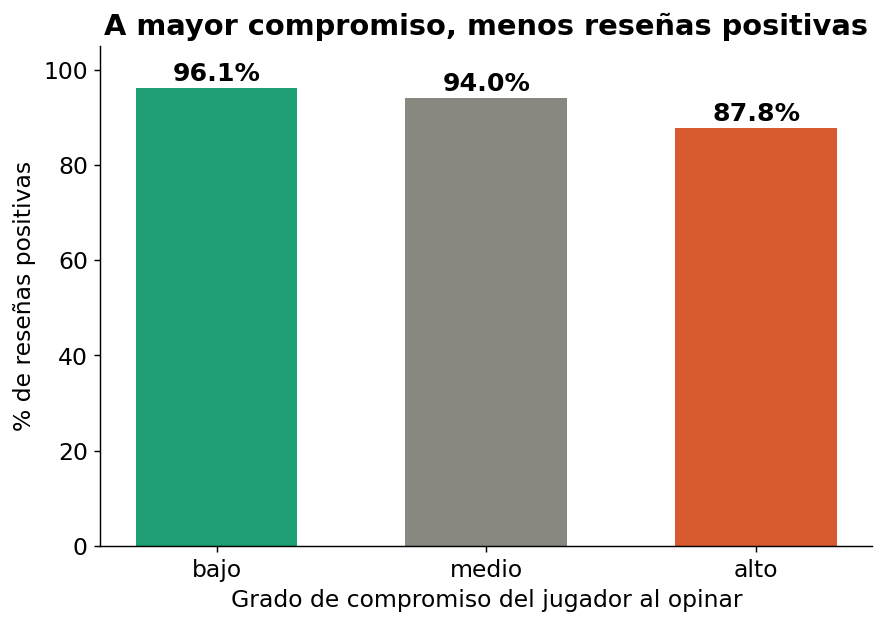

In [ ]:
tabla_pct = pd.crosstab(df["nivel_compromiso"], df["voted_up"], normalize="index") * 100
orden = ["bajo", "medio", "alto"]
valores = tabla_pct.loc[orden, True]

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(orden, valores, color=[COLOR_TEAL, COLOR_GRAY, COLOR_CORAL], width=0.6)

for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 1.5, f"{valor:.1f}%",
            ha="center", fontsize=14, fontweight="bold")

ax.set_ylim(0, 105)
ax.set_ylabel("% de reseñas positivas")
ax.set_xlabel("Grado de compromiso del jugador al opinar")
ax.set_title("A mayor compromiso, menos reseñas positivas")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_pct_positivas_por_compromiso.png"), bbox_inches="tight")
plt.show()


### A.2.3 Gráfico 2 — % de reseñas positivas por género (promedio por juego, no por reseña)

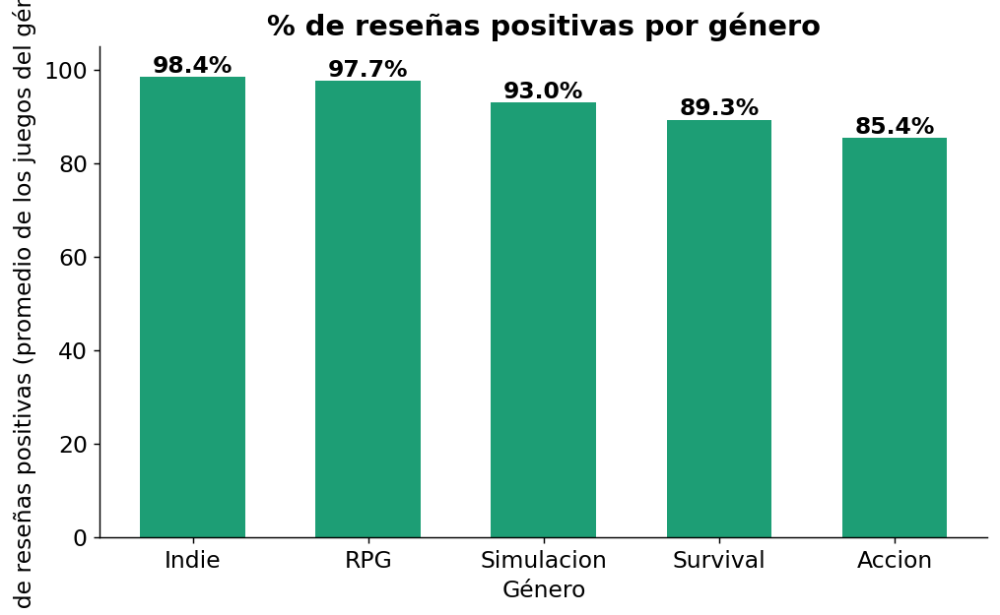

In [ ]:
resumen_juego = df.groupby(["juego", "genero"]).agg(
    pct_positivas=("voted_up", "mean"),
).reset_index()
resumen_juego["pct_positivas"] *= 100

resumen_genero = resumen_juego.groupby("genero")["pct_positivas"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(resumen_genero.index, resumen_genero.values, color=COLOR_TEAL, width=0.6)

for barra, valor in zip(barras, resumen_genero.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 1, f"{valor:.1f}%",
            ha="center", fontsize=13, fontweight="bold")

ax.set_ylim(0, 105)
ax.set_ylabel("% de reseñas positivas (promedio de los juegos del género)")
ax.set_xlabel("Género")
ax.set_title("% de reseñas positivas por género")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_pct_positivas_por_genero.png"), bbox_inches="tight")
plt.show()


### A.2.4 Gráfico 3 — La tendencia completa: % de positivas según el nivel exacto de compromiso

En vez de tres grupos, este gráfico divide `ratio_compromiso` en diez franjas y muestra
cómo varía el porcentaje de positivas a lo largo de todo el rango. Permite distinguir una
tendencia continua de un efecto producido por el corte en tres grupos.

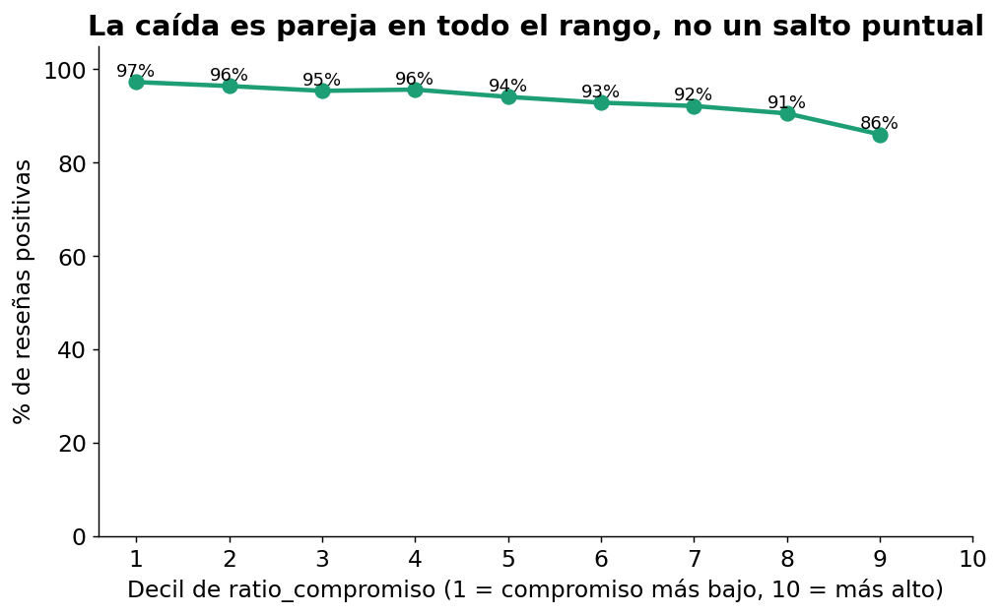

In [ ]:
df["decil_compromiso"] = pd.qcut(df["ratio_compromiso"], q=10, labels=False, duplicates="drop") + 1
pct_por_decil = df.groupby("decil_compromiso")["voted_up"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pct_por_decil.index, pct_por_decil.values, marker="o", color=COLOR_TEAL,
        linewidth=2.5, markersize=8)

for x, y in zip(pct_por_decil.index, pct_por_decil.values):
    ax.text(x, y + 1.2, f"{y:.0f}%", ha="center", fontsize=10)

ax.set_xlabel("Decil de ratio_compromiso (1 = compromiso más bajo, 10 = más alto)")
ax.set_ylabel("% de reseñas positivas")
ax.set_title("La caída es pareja en todo el rango, no un salto puntual")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, 105)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "03_tendencia_por_decil.png"), bbox_inches="tight")
plt.show()


### A.2.5 Gráfico 4 — Resumen visual de las tres pruebas

Un esquema de dos colores: destacado cuando la prueba rechazó la hipótesis nula, gris
cuando no. Resume el estado de las tres pruebas de esta línea sin mostrar los valores.

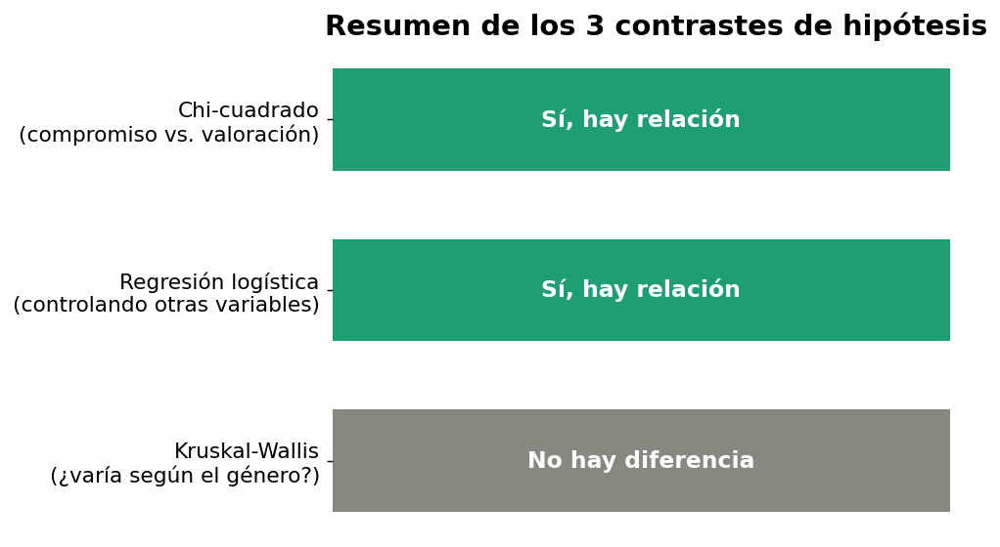


Todos los gráficos se guardaron en: /content/drive/MyDrive/tesina_steam/checkpoints/figuras_presentacion


In [ ]:
resultados_finales = [
    ("Chi-cuadrado\n(compromiso vs. valoración)", True),
    ("Regresión logística\n(controlando otras variables)", True),
    ("Kruskal-Wallis\n(¿varía según el género?)", False),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
etiquetas = [r[0] for r in resultados_finales]
colores = [COLOR_TEAL if r[1] else COLOR_GRAY for r in resultados_finales]
y_pos = range(len(resultados_finales))

ax.barh(y_pos, [1]*len(resultados_finales), color=colores, height=0.6)
ax.set_yticks(y_pos)
ax.set_yticklabels(etiquetas, fontsize=12)
ax.set_xticks([])
ax.invert_yaxis()

for i, (_, encontrado) in enumerate(resultados_finales):
    texto = "Sí, hay relación" if encontrado else "No hay diferencia"
    ax.text(0.5, i, texto, ha="center", va="center", fontsize=13, fontweight="bold", color="white")

for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Resumen de los 3 contrastes de hipótesis")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_resumen_hipotesis.png"), bbox_inches="tight")
plt.show()

print(f"\nTodos los gráficos se guardaron en: {FIGURES_DIR}")


### A.2.6 Dónde están las figuras del trabajo final

Estos cuatro gráficos corresponden a la línea previa y no se utilizan en el informe. Las
figuras del trabajo final se generan en la sección 13, a partir de la comparación entre el
porcentaje que publica la plataforma y la valoración de referencia construida leyendo los
textos.

## A.3 · Comparación de clasificadores

*La lectura preliminar con el modelo de sentimiento, que abría esta línea, forma parte del trabajo final y figura en la sección 4.*

### A.3.1 Cargar datos e instalar dependencias

In [ ]:
!pip install pysentimiento -q

import pandas as pd
import numpy as np
import os

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = "/content/drive/MyDrive/tesina_steam/checkpoints"
else:
    CHECKPOINT_DIR = "checkpoints"

df = pd.read_csv(os.path.join(CHECKPOINT_DIR, "dataset_variables.csv"))
df["voted_up"] = df["voted_up"].astype(bool)
df = df.dropna(subset=["review"])  # reseñas sin texto no sirven para esta parte
df = df[df["review"].str.strip().str.len() > 0]
print(f"Filas con texto utilizable: {len(df)} de {df['juego'].nunique()} juegos")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 33.8 MB/s eta 0:00:00
Mounted at /content/drive
Filas con texto utilizable: 56361 de 20 juegos


### A.3.2 Preparar los dos conjuntos de variables (solo texto vs. texto + tiempo de juego)

A partir de acá comienza la parte correspondiente a la línea previa.

- **Modelo A (solo texto)**: TF-IDF sobre el texto de la reseña.
- **Modelo B (texto + tiempo de juego)**: TF-IDF más `ratio_compromiso`,
  `dias_desde_lanzamiento`, `dias_desde_resena_hasta_extraccion` y género.

Se emplea regresión logística en ambos casos, de modo que la única diferencia entre A y B
sea la presencia de las variables de tiempo de juego y la comparación resulte equitativa.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from scipy.sparse import hstack, csr_matrix

y = df["voted_up"].astype(int).values

idx_train, idx_test = train_test_split(
    df.index, test_size=0.25, random_state=42, stratify=y
)

textos_train = df.loc[idx_train, "review"].astype(str)
textos_test = df.loc[idx_test, "review"].astype(str)
y_train = df.loc[idx_train, "voted_up"].astype(int).values
y_test = df.loc[idx_test, "voted_up"].astype(int).values

vectorizador = TfidfVectorizer(max_features=5000, min_df=3, ngram_range=(1, 2))
X_train_texto = vectorizador.fit_transform(textos_train)
X_test_texto = vectorizador.transform(textos_test)

print(f"Train: {X_train_texto.shape[0]} filas | Test: {X_test_texto.shape[0]} filas | Vocabulario: {X_train_texto.shape[1]} términos")


Train: 42270 filas | Test: 14091 filas | Vocabulario: 5000 términos


#### A.3.2.1 Variables de tiempo de juego (para el Modelo B)

In [ ]:
df_dummies = pd.get_dummies(df["genero"], prefix="genero", drop_first=True)
vars_comportamiento = pd.concat([
    df[["ratio_compromiso", "dias_desde_lanzamiento", "dias_desde_resena_hasta_extraccion"]],
    df_dummies,
], axis=1)

# Estandarizamos las variables numéricas de comportamiento para que estén en una escala
# comparable a las de TF-IDF antes de combinarlas.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_comport_train = scaler.fit_transform(vars_comportamiento.loc[idx_train])
X_comport_test = scaler.transform(vars_comportamiento.loc[idx_test])

X_train_combinado = hstack([X_train_texto, csr_matrix(X_comport_train)])
X_test_combinado = hstack([X_test_texto, csr_matrix(X_comport_test)])

print(f"Modelo A (solo texto): {X_train_texto.shape[1]} columnas")
print(f"Modelo B (texto + comportamiento): {X_train_combinado.shape[1]} columnas")


Modelo A (solo texto): 5000 columnas
Modelo B (texto + comportamiento): 5007 columnas


### A.3.3 Entrenar y evaluar los dos modelos

In [ ]:
modelo_A = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
modelo_A.fit(X_train_texto, y_train)
pred_A = modelo_A.predict(X_test_texto)
f1_A = f1_score(y_test, pred_A)

modelo_B = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
modelo_B.fit(X_train_combinado, y_train)
pred_B = modelo_B.predict(X_test_combinado)
f1_B = f1_score(y_test, pred_B)

print(f"Modelo A (solo texto)              -> F1-score = {f1_A:.4f}")
print(f"Modelo B (texto + comportamiento)  -> F1-score = {f1_B:.4f}")
print(f"Diferencia (B - A) = {f1_B - f1_A:+.4f}")

print("\nReporte detallado - Modelo A:")
print(classification_report(y_test, pred_A, target_names=["No recomendada", "Recomendada"]))
print("\nReporte detallado - Modelo B:")
print(classification_report(y_test, pred_B, target_names=["No recomendada", "Recomendada"]))


Modelo A (solo texto)              -> F1-score = 0.9359
Modelo B (texto + comportamiento)  -> F1-score = 0.9340
Diferencia (B - A) = -0.0019

Reporte detallado - Modelo A:
                precision    recall  f1-score   support

No recomendada       0.38      0.81      0.51      1040
   Recomendada       0.98      0.89      0.94     13051

      accuracy                           0.89     14091
     macro avg       0.68      0.85      0.72     14091
  weighted avg       0.94      0.89      0.90     14091


Reporte detallado - Modelo B:
                precision    recall  f1-score   support

No recomendada       0.37      0.83      0.51      1040
   Recomendada       0.99      0.89      0.93     13051

      accuracy                           0.88     14091
     macro avg       0.68      0.86      0.72     14091
  weighted avg       0.94      0.88      0.90     14091



### A.3.4 ¿La diferencia es estadísticamente significativa? (bootstrap)

Se remuestrea el conjunto de test 1.000 veces (con reemplazo) y se recalcula la
diferencia de F1-score en cada remuestreo, para construir un intervalo de confianza
de esa diferencia. Si el intervalo no incluye el 0, la mejora (o el empeoramiento)
del Modelo B sobre el Modelo A es estadísticamente significativa.

In [ ]:
np.random.seed(42)
n_bootstrap = 1000
n_test = len(y_test)
diferencias = []

pred_A_arr = np.array(pred_A)
pred_B_arr = np.array(pred_B)
y_test_arr = np.array(y_test)

for _ in range(n_bootstrap):
    indices = np.random.choice(n_test, size=n_test, replace=True)
    f1_A_boot = f1_score(y_test_arr[indices], pred_A_arr[indices])
    f1_B_boot = f1_score(y_test_arr[indices], pred_B_arr[indices])
    diferencias.append(f1_B_boot - f1_A_boot)

diferencias = np.array(diferencias)
ic_inferior = np.percentile(diferencias, 2.5)
ic_superior = np.percentile(diferencias, 97.5)

print(f"Diferencia observada (B - A): {f1_B - f1_A:+.4f}")
print(f"Intervalo de confianza 95% (bootstrap): [{ic_inferior:+.4f}, {ic_superior:+.4f}]")

if ic_inferior > 0:
    print("\nEl intervalo está completamente por encima de 0 -> el Modelo B es significativamente MEJOR que el Modelo A.")
elif ic_superior < 0:
    print("\nEl intervalo está completamente por debajo de 0 -> el Modelo B es significativamente PEOR que el Modelo A.")
else:
    print("\nEl intervalo incluye el 0 -> NO hay diferencia estadísticamente significativa entre los dos modelos.")


Diferencia observada (B - A): -0.0019
Intervalo de confianza 95% (bootstrap): [-0.0043, +0.0006]

El intervalo incluye el 0 -> NO hay diferencia estadísticamente significativa entre los dos modelos.


### A.3.5 Interpretabilidad: ejemplos y palabras clave

Dos formas distintas de "abrir la caja":

1. **Ejemplos reales** de reseñas para cada categoría de sentimiento (`POS`/`NEU`/`NEG`)
   detectada por `pysentimiento`. Como es un modelo neuronal (no funciona por
   palabras sueltas sino por el contexto completo), la forma más clara de
   entenderlo es leyendo ejemplos, no listando "palabras que usa".
2. **Palabras más influyentes** del Modelo A (TF-IDF + regresión logística). Este
   modelo sí es interpretable: cada término del vocabulario tiene un coeficiente
   que empuja la predicción hacia "Recomendada" o "No recomendada".

#### A.3.5.1 Ejemplos de reseñas por categoría de sentimiento

In [ ]:
pd.set_option("display.max_colwidth", 150)

for categoria in ["POS", "NEU", "NEG"]:
    print(f"\n{'='*80}\nEjemplos clasificados como {categoria}:\n{'='*80}")
    ejemplos = df[df["sentimiento_pln"] == categoria].sample(min(4, (df["sentimiento_pln"] == categoria).sum()), random_state=42)
    for _, fila in ejemplos.iterrows():
        recomendada = "Recomendada" if fila["voted_up"] else "No recomendada"
        print(f"\n[{recomendada} | polaridad_pln={fila['polaridad_pln']:.2f}] {fila['review'][:200]}")



Ejemplos clasificados como POS:

[Recomendada | polaridad_pln=0.81] juegazo

[Recomendada | polaridad_pln=0.97] esta buenisimo el juego :)

[Recomendada | polaridad_pln=0.71] Simulador de adopción de niños 

1000/10

[Recomendada | polaridad_pln=0.86] ¿quien no va a recomendar esta obra maestra absoluta de los videojuegos? da igual si no te gusta el rol es el juego que todo jugador debería probar.

Ejemplos clasificados como NEU:

[Recomendada | polaridad_pln=0.16] Es differente

[Recomendada | polaridad_pln=0.32] GOTY

[Recomendada | polaridad_pln=0.33] .

[Recomendada | polaridad_pln=0.02] no se q decir
si

Ejemplos clasificados como NEG:

[Recomendada | polaridad_pln=0.25] terrific !

[Recomendada | polaridad_pln=0.06] Matar y ser matado, Morir y ser morido, No paren de MATAR A LOS DEMONIOS  kill/100

[Recomendada | polaridad_pln=0.01] Cada partida hackers, mal ping, niños rusos...  JUEGAZO

[No recomendada | polaridad_pln=0.00] cuando arreglen la mierda de anticheat que tienen seg

#### A.3.5.2 Palabras (y pares de palabras) más influyentes en el Modelo A

Se extraen los coeficientes de la regresión logística asociados a cada término del
vocabulario de TF-IDF. Un coeficiente positivo alto empuja la predicción hacia
"Recomendada"; uno muy negativo, hacia "No recomendada".

In [ ]:
vocabulario = vectorizador.get_feature_names_out()
coeficientes = modelo_A.coef_[0]

tabla_coef = pd.DataFrame({"termino": vocabulario, "coeficiente": coeficientes})

top_positivos = tabla_coef.sort_values("coeficiente", ascending=False).head(20)
top_negativos = tabla_coef.sort_values("coeficiente", ascending=True).head(20)

print("Términos que más empujan hacia 'Recomendada':")
display(top_positivos.reset_index(drop=True))

print("\nTérminos que más empujan hacia 'No recomendada':")
display(top_negativos.reset_index(drop=True))


Términos que más empujan hacia 'Recomendada':


,termino,coeficiente
0,juegazo,8.074264
1,god,4.786107
2,10 10,4.773897
3,el mejor,4.746989
4,mejor que,4.644859
5,amo,4.469473
6,excelente,4.270648
7,entretenido,4.189765
8,muy bueno,4.169762
9,recomendado,4.142362



Términos que más empujan hacia 'No recomendada':


,termino,coeficiente
0,peor,-5.741884
1,basura,-5.515964
2,no,-5.031815
3,mierda,-4.796172
4,aburrido,-4.682146
5,asco,-4.503085
6,cagada,-3.840996
7,horrible,-3.793181
8,partidas,-3.700369
9,injugable,-3.655086


### A.3.6 Guardar resultados

In [ ]:
resultado_pln = pd.DataFrame([{
    "modelo": "A - Solo texto",
    "f1_score": round(f1_A, 4),
}, {
    "modelo": "B - Texto + comportamiento",
    "f1_score": round(f1_B, 4),
}, {
    "modelo": "Diferencia (B - A)",
    "f1_score": round(f1_B - f1_A, 4),
    "ic_95_inferior": round(ic_inferior, 4),
    "ic_95_superior": round(ic_superior, 4),
}])
display(resultado_pln)
resultado_pln.to_csv(os.path.join(CHECKPOINT_DIR, "resultado_objetivo_4_pln.csv"), index=False)

df[["appid", "juego", "recommendationid", "voted_up", "sentimiento_pln", "polaridad_pln"]].to_csv(
    os.path.join(CHECKPOINT_DIR, "dataset_con_sentimiento.csv"), index=False
)
print("Resultados guardados.")


### A.3.7 Qué de esta sección llega al trabajo final

Las pruebas de comparación entre clasificadores no intervienen en el trabajo final. Lo que
continúa es la lectura preliminar: las proporciones observadas con el modelo de sentimiento
sin ajuste son las que la sección 5 utiliza para estimar la composición de la muestra antes
de clasificarla a mano.